<a href="https://colab.research.google.com/github/camiloascencio-hash/GP-S/blob/main/Entrega1_BdM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Caso integrador Bebidas del Maipo S.A. — Entrega 1: Calidad y pronóstico
**Gestión de Producción de Bienes y Servicios · USACH · 2.º semestre 2026**

Este cuaderno es el repositorio ejecutable de la Entrega 1. Se ejecuta de principio a fin con
**Entorno de ejecución → Ejecutar todo** (en Colab) y reproduce todas las cifras del informe. La primera
celda de código clona los datos desde GitHub si no están. La ejecución completa tarda ≈ 7 a 10 minutos:
la mayor parte es el ajuste de los SARIMAX en la validación. Los resultados quedan en `resultados/`.

| Sección | Contenido | Ítem del enunciado |
|---|---|---|
| 0 | El caso y qué se pide | §2, §3, §6 |
| 1 | Configuración, semillas y carga de datos | §9 (reproducibilidad) |
| 2 | Análisis exploratorio y bitácora de calidad de datos | §1 «los datos no están limpios» |
| 3 | **Parte A**: cartas X̄–R, reglas, capacidad, OIML, carta p, Pareto, sobrellenado | §6.1 (1 a 5) |
| 4 | **Parte B**: diagnóstico, censura, modelos, origen deslizante, jerarquía, pronóstico final | §6.2 (1 a 6) |
| 5 | **Parte C**: tabla de traspaso a la Entrega 2 | §6.3 (1 a 4) |
| 6 | Verificaciones de fuga y reproducibilidad, cifras clave | Rúbrica de laboratorio |

## 0. El caso

**La empresa.** Bebidas del Maipo S.A. (BdM) es una embotelladora regional con planta en Cerrillos.
Produce **3 familias × 3 formatos = 9 SKU**:

| Familia | Sabor | SKU 0,5 L | SKU 1,5 L | SKU 3,0 L |
|---|---|---|---|---|
| CIT (Cítrico) | Limón | CIT-L05 | CIT-L15 | CIT-L30 |
| FUN (Funcional) | Berries | FUN-B05 | FUN-B15 | FUN-B30 |
| NEC (Néctar) | Durazno | NEC-D05 | NEC-D15 | NEC-D30 |

La cartera tiene **dos jerarquías a la vez**: una anidada (Planta → Familia → SKU), que se usa en el
pronóstico, y una cruzada por formato, que define la línea de envasado: **L1** envasa solo 0,5 L y
**L2** envasa 1,5 L y 3,0 L. Antes del envasado, una única mezcladora prepara el jarabe de todas las
familias. Es el cuello de botella, y por eso el sobrellenado (jarabe que se regala) consume capacidad.

**El encargo.** La gerencia plantea tres quejas. La Entrega 1 responde la primera y prepara la segunda:
1. *«Calidad dice que el proceso está bajo control, pero Finanzas ve una merma que no cuadra con las
   ventas.»* → **Parte A**: ¿se puede estar bajo control y aun así ser incapaz? ¿Cuánto cuesta el sobrellenado?
2. *«Comercial entrega un pronóstico y Planificación no le cree.»* → **Parte B**: un solo pronóstico
   por SKU, validado sin fuga, coherente en la jerarquía y con su incertidumbre.
3. *«El plan dice que la capacidad alcanza, pero el programa semanal no.»* → Entregas 2 y 3.
   La Entrega 1 deja los parámetros de entrada (**Parte C**).

**La regla del caso:** cada unidad produce *un número que alguien más va a usar*. La Entrega 1 entrega
cuatro números a la Entrega 2: la merma $\rho_\ell$ por línea, el sobrellenado en litros de jarabe por
caja, el pronóstico $\hat d_{it}$ y la desviación del error $\hat\sigma_{i,h}$.

**Dos advertencias del enunciado que guían todo el cuaderno:**
- Los datos vienen de un ERP real y **no están limpios**. Cada anomalía se documenta: qué es, cómo se
  detectó y qué se hizo con ella (bitácoras en las secciones 2 y 4).
- `demanda_semanal.csv` registra **ventas, no demanda**. Cuando hay quiebre de stock (`dias_sin_stock > 0`)
  la venta está *censurada* y subestima la demanda (sección 4.2).



## 1. Configuración, semillas y carga de datos

**1.1 Parámetros del análisis.** Todos los parámetros están en un solo diccionario `CONFIG`. Cambiar un
valor aquí, por ejemplo el número de ventanas, se propaga a todo el cuaderno sin tocar otras celdas.
Al final de la celda la configuración y las versiones de las librerías se guardan en `resultados/`
(registro de configuraciones).

In [ ]:
import os, sys, json, subprocess, warnings, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import scipy
from scipy import stats
import statsmodels
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore")              # statsmodels avisa mucho sobre convergencia
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

CONFIG = {
    "semilla": 20260923,            # la misma semilla de metadatos.json
    "repo": "https://github.com/camiloascencio-hash/GP-S.git",
    "carpeta_datos": "GP-S/datos",
    "carpeta_resultados": "resultados",
    # Parte A
    "semanas_fase1": 5,             # Fase I = semanas 1 a 5 ; Fase II = semanas 6 a 10
    "n_subgrupo": 5,
    "cpk_objetivo": 1.33,
    # Parte B
    "H": 13,                        # horizonte de pronóstico (semanas)
    "S": 52,                        # largo de la estación (semanas en un año)
    "ventanas": 8,                  # orígenes del origen deslizante (mínimo exigido = 8)
    "paso": 3,                      # semanas que avanza el origen entre ventanas
    "umbral_atipico": 3.0,          # ventas > 3 veces el nivel local = atípico
    "semanas_proporcion": 52,       # proporciones jerárquicas con el último año del entrenamiento
    "niveles_ip": [0.80, 0.95],     # intervalos de predicción pedidos
}

np.random.seed(CONFIG["semilla"])   # semilla global (el análisis es determinista, pero queda fijada)

# datos: en Colab se clona el repositorio; si la carpeta ya existe, se usa tal cual
if not os.path.isdir(CONFIG["carpeta_datos"]):
    subprocess.run(["git", "clone", "-q", CONFIG["repo"]], check=True)
assert os.path.isdir(CONFIG["carpeta_datos"]), "No se encontró la carpeta de datos"
os.makedirs(CONFIG["carpeta_resultados"], exist_ok=True)

versiones = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
             "statsmodels": statsmodels.__version__, "scipy": scipy.__version__}
with open(os.path.join(CONFIG["carpeta_resultados"], "config_ejecucion.json"), "w", encoding="utf-8") as f:
    json.dump({"config": CONFIG, "versiones": versiones}, f, indent=2, ensure_ascii=False)

print("Versiones:", versiones)

Versiones: {'python': '3.13.16', 'numpy': '2.1.3', 'pandas': '2.2.3', 'statsmodels': '0.15.0', 'scipy': '1.16.3'}


**1.2 Carga.** Se leen los cinco archivos que usa la Entrega 1. **Los datos crudos no se modifican.** Se
guardan como `*_raw` y todo el trabajo se hace sobre copias, como exige el enunciado (§9, «Estructura»).

In [ ]:
def leer(nombre_archivo):
    return pd.read_csv(os.path.join(CONFIG["carpeta_datos"], nombre_archivo))

with open(os.path.join(CONFIG["carpeta_datos"], "metadatos.json"), encoding="utf-8") as f:
    metadatos = json.load(f)

llen_raw = leer("calidad_llenado.csv")          # volumen de cada botella (subgrupos de n = 5)
atr_raw = leer("calidad_atributos.csv")         # inspección de fin de turno (defectuosas)
spec = leer("especificaciones_calidad.csv")     # nominal, LIE, LSE y tolerancia OIML por formato
maestro = leer("maestro_sku.csv")               # datos de cada SKU (botellas/caja, costos, línea)
dem_raw = leer("demanda_semanal.csv")           # 156 semanas x 9 SKU de VENTAS

for nombre, d in [("calidad_llenado", llen_raw), ("calidad_atributos", atr_raw),
                  ("especificaciones", spec), ("maestro_sku", maestro), ("demanda_semanal", dem_raw)]:
    print(f"{nombre:18s} {d.shape[0]:5d} filas x {d.shape[1]:2d} columnas")

# copias de trabajo (los *_raw quedan intactos y se verifican al final del cuaderno)
llen = llen_raw.copy()
atr = atr_raw.copy()
dem = dem_raw.copy()

esp = spec.set_index("formato_L")               # especificaciones indexadas por formato
mst = maestro.set_index("sku")                  # maestro indexado por SKU
print("\nSemilla del caso (metadatos.json):", metadatos["semilla"])
display(spec)

calidad_llenado     4200 filas x 10 columnas
calidad_atributos    210 filas x  8 columnas
especificaciones       3 filas x  6 columnas
maestro_sku            9 filas x 13 columnas
demanda_semanal     1404 filas x 10 columnas

Semilla del caso (metadatos.json): 20260923


,formato_L,nominal_mL,LIE_mL,LSE_mL,tolerancia_oiml_mL,limite_legal_inferior_mL
0,0.5,500.0,492.0,508.0,15.0,485.0
1,1.5,1500.0,1485.0,1515.0,22.5,1477.5
2,3.0,3000.0,2975.0,3025.0,45.0,2955.0


## 2. Análisis exploratorio y bitácora de calidad de datos

Antes de construir cartas o modelos hay que entender **cómo están compuestos los datos** y **qué
problemas traen**. Toda revisión se anota en una bitácora con cuatro campos: archivo, chequeo,
resultado y decisión. Así cada anomalía queda trazable hasta el informe.

In [ ]:
bitacora = []

def registrar(archivo, chequeo, resultado, decision):
    bitacora.append({"archivo": archivo, "chequeo": chequeo, "resultado": resultado, "decision": decision})

# ---------- calidad_llenado ----------
registrar("calidad_llenado", "Valores faltantes", f"{llen.isna().sum().sum()} celdas vacías", "Sin acción")
registrar("calidad_llenado", "Duplicados (subgrupo, n_obs)", f"{llen.duplicated(['subgrupo', 'n_obs']).sum()} duplicados", "Sin acción")

tam = llen.groupby("subgrupo").size()
registrar("calidad_llenado", "Tamaño de subgrupo", f"n = {sorted(tam.unique().tolist())} en {len(tam)} subgrupos",
          "n = 5 constante: se usan las constantes de la carta X̄–R")

mezclas = llen.groupby("subgrupo")[["linea", "sku", "turno"]].nunique().max().max()
registrar("calidad_llenado", "Subgrupos que mezclan línea, SKU o turno", f"máximo {mezclas} valor distinto por subgrupo",
          "Sin acción: los subgrupos son racionales")
registrar("calidad_llenado", "Volúmenes ≤ 0", f"{(llen['volumen_mL'] <= 0).sum()} valores", "Sin acción")

cuenta = llen.groupby(["linea", "formato_L", "turno"])["subgrupo"].nunique()
registrar("calidad_llenado", "Subgrupos por línea, formato y turno", f"mínimo {cuenta.min()}, máximo {cuenta.max()}",
          "Se reporta el desbalance; la capacidad por turno se lee con su n")

# ---------- calidad_atributos ----------
registrar("calidad_atributos", "Valores faltantes", f"{atr.isna().sum().sum()} celdas vacías", "Sin acción")
registrar("calidad_atributos", "Filas duplicadas", f"{atr.duplicated().sum()} duplicados", "Sin acción")
registrar("calidad_atributos", "Defectuosas > inspeccionadas",
          f"{(atr['n_defectuosas'] > atr['n_inspeccionadas']).sum()} filas", "Sin acción")
registrar("calidad_atributos", "Tamaño de inspección n",
          f"entre {atr['n_inspeccionadas'].min()} y {atr['n_inspeccionadas'].max()}",
          "n varía: carta p con límites variables (no np)")
registrar("calidad_atributos", "Categoría 'Sin defectos'", f"{(atr['causa_principal'] == 'Sin defectos').sum()} filas",
          "Cuentan para p; se excluyen del Pareto")

# ---------- especificaciones y maestro ----------
registrar("especificaciones_calidad", "Valores faltantes", f"{spec.isna().sum().sum()} celdas vacías", "Sin acción")
registrar("maestro_sku", "Valores faltantes", f"{maestro.isna().sum().sum()} celdas vacías", "Sin acción")

# ---------- demanda_semanal ----------
filas_nan = dem[dem.isna().any(axis=1)]
registrar("demanda_semanal", "Valores faltantes",
          f"{len(filas_nan)} filas sin ventas_cajas ni dias_sin_stock ({filas_nan['sku'].unique().tolist()}, semanas {filas_nan['semana'].tolist()})",
          "Interpolación lineal (celda 2.3)")
registrar("demanda_semanal", "Filas duplicadas", f"{dem.duplicated().sum()} duplicados", "Sin acción")
registrar("demanda_semanal", "Semanas x SKU", f"{dem['semana'].nunique()} semanas x {dem['sku'].nunique()} SKU = {len(dem)} filas",
          "Panel completo")

display(filas_nan)

,semana,fecha_lunes,anio_iso,semana_iso,sku,ventas_cajas,dias_sin_stock,promocion,precio_lista_clp,precio_efectivo_clp
724,101,2025-09-01,2025,36,CIT-L15,NaN,NaN,0,7980,7980
725,102,2025-09-08,2025,37,CIT-L15,NaN,NaN,1,7980,6433
726,103,2025-09-15,2025,38,CIT-L15,NaN,NaN,0,7980,7980


**Lectura de resultados.** Los archivos de calidad vienen completos: no tienen faltantes, duplicados ni
valores imposibles. Los 840 subgrupos tienen $n = 5$ y cada uno pertenece a una sola línea, SKU y turno,
así que son subgrupos racionales. En demanda faltan **3 semanas de CIT-L15 (101 a 103, septiembre de 2025)**,
con ventas y días sin stock vacíos a la vez: es un hueco de registro del ERP, no una venta cero.

**2.1 Cómo se compone el dato de llenado.** Cada fila es una botella. Cada 2 horas se toma un
*subgrupo racional* de 5 botellas seguidas de una misma línea, SKU y turno. Interesa saber cuántos
subgrupos hay por combinación y si el volumen promedio ya muestra sobrellenado respecto del nominal.

Subgrupos por línea, formato y turno (10 semanas):


turno            A (06-14)  B (14-22)  C (22-06)
linea formato_L                                 
L1    0.5            120.0      120.0        NaN
L2    1.5            108.0       76.0      104.0
      3.0             92.0      124.0       96.0

count     mean   std      min      max  nominal  sobre_nominal_mL  %_sobre_LSE  %_bajo_LIE
linea formato_L                                                                                            
L1    0.5         1200   504.09  2.61   495.76   512.19    500.0              4.09         6.75        0.00
L2    1.5         1440  1504.60  5.42  1488.80  1525.19   1500.0              4.60         4.24        0.00
      3.0         1560  3008.50  8.81  2974.20  3036.85   3000.0              8.50         3.40        0.06

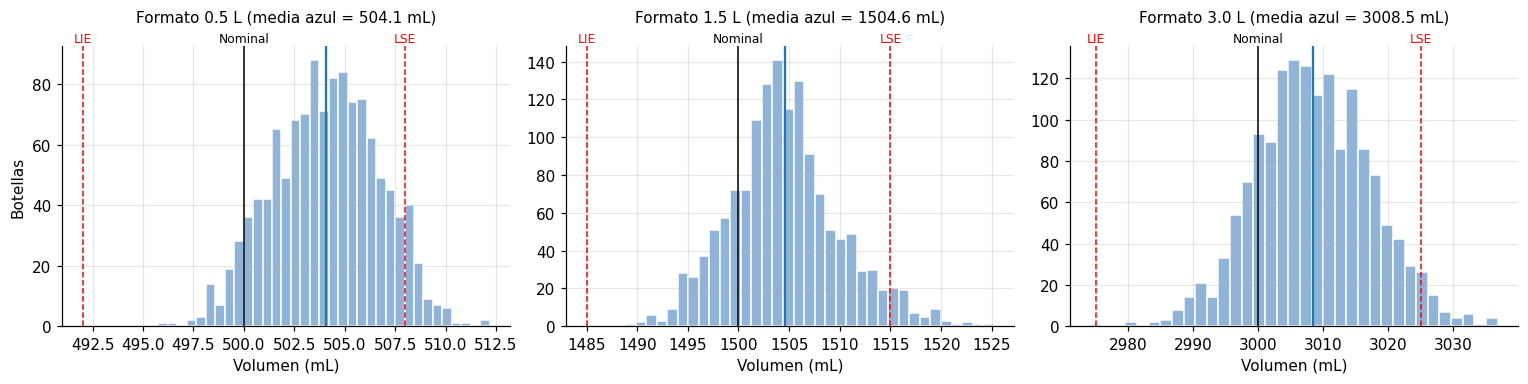

In [ ]:
sub_por_comb = (llen.groupby(["linea", "formato_L", "turno"])["subgrupo"].nunique()
                    .unstack("turno"))
print("Subgrupos por línea, formato y turno (10 semanas):")
display(sub_por_comb)

resumen_llen = llen.groupby(["linea", "formato_L"])["volumen_mL"].agg(["count", "mean", "std", "min", "max"])
resumen_llen["nominal"] = esp.loc[resumen_llen.index.get_level_values("formato_L"), "nominal_mL"].values
resumen_llen["sobre_nominal_mL"] = resumen_llen["mean"] - resumen_llen["nominal"]
lim_f = esp.loc[llen["formato_L"]]
resumen_llen["%_sobre_LSE"] = pd.Series(100 * (llen["volumen_mL"].values > lim_f["LSE_mL"].values), index=llen.index).groupby([llen["linea"], llen["formato_L"]]).mean()
resumen_llen["%_bajo_LIE"] = pd.Series(100 * (llen["volumen_mL"].values < lim_f["LIE_mL"].values), index=llen.index).groupby([llen["linea"], llen["formato_L"]]).mean()
display(resumen_llen.round(2))

# Histograma de cada formato con sus especificaciones (la especificación va en el histograma, NUNCA en la carta X̄)
fig, ejes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, (formato, d) in zip(ejes, llen.groupby("formato_L")):
    ax.hist(d["volumen_mL"], bins=35, color="#8fb3d9", edgecolor="white")
    for valor, etiqueta, color in [(esp.loc[formato, "LIE_mL"], "LIE", "red"), (esp.loc[formato, "LSE_mL"], "LSE", "red"),
                                   (esp.loc[formato, "nominal_mL"], "Nominal", "black")]:
        ax.axvline(valor, color=color, linestyle="--" if etiqueta != "Nominal" else "-", lw=1)
        ax.annotate(etiqueta, xy=(valor, 1.0), xycoords=("data", "axes fraction"), xytext=(0, 3),
                    textcoords="offset points", ha="center", fontsize=8, color=color)
    ax.axvline(d["volumen_mL"].mean(), color="tab:blue", lw=1.5)
    ax.set_title(f"Formato {formato} L (media azul = {d['volumen_mL'].mean():.1f} mL)", pad=16, fontsize=10)
    ax.set_xlabel("Volumen (mL)")
ejes[0].set_ylabel("Botellas")
plt.tight_layout()
plt.show()

**Lectura de resultados.** L1 tiene 2 turnos (A y B, 120 subgrupos cada uno). L2 tiene 3 turnos, con
desbalance: el turno B de 1,5 L tiene 76 subgrupos contra 104 a 108 de los otros, y el B de 3,0 L tiene
124. **Las tres medias están sobre el nominal**: +4,1 mL en 0,5 L, +4,6 mL en 1,5 L y +8,5 mL en 3,0 L.
Es la primera evidencia del sobrellenado que la Parte A debe cuantificar. Los histogramas son
aproximadamente simétricos. Bajo el LIE prácticamente no hay botellas (una sola, de 3,0 L), pero **sobre el
LSE sí**: el proceso está corrido hacia arriba, y esas botellas son jarabe regalado (columna `%_sobre_LSE`).

**2.2 Cómo se compone el dato de atributos.** Cada fila es la inspección de fin de turno de una línea:
cuántas botellas se revisaron, cuántas salieron defectuosas y cuál fue la causa principal.

In [ ]:
insp = atr.groupby(["linea", "turno"]).agg(inspecciones=("n_inspeccionadas", "size"),
                                           botellas=("n_inspeccionadas", "sum"),
                                           defectuosas=("n_defectuosas", "sum"))
insp["%_defectuosas"] = 100 * insp["defectuosas"] / insp["botellas"]
display(insp.round(2))

inspecciones  botellas  defectuosas  %_defectuosas
linea turno                                                        
L1    A (06-14)            30      6427          134           2.08
      B (14-22)            30      6478          114           1.76
L2    A (06-14)            50     10879          338           3.11
      B (14-22)            50     11120          346           3.11
      C (22-06)            50     10975          343           3.13

**Lectura de resultados.** L1 rechaza cerca de 1,9 % de lo inspeccionado y L2 cerca de 3,1 %, con
porcentajes casi iguales entre turnos. A diferencia del llenado, la merma por atributos **no** depende del
turno. Es un primer indicio de que sus causas son distintas (sección 3.4).

**2.3 Cómo se compone el dato de demanda, y su limpieza básica.** Son 156 semanas (02/10/2023 a
21/09/2026) × 9 SKU de **ventas** en cajas. Las variables auxiliares son la promoción (0/1), los días sin
stock en el CD y los precios. Aquí se tratan los dos problemas de *registro* del ERP, que afectan tanto
a la Parte A (volumen anual para valorizar el sobrellenado) como a la Parte B:

- **Datos faltantes.** Se completan por interpolación lineal entre la semana anterior y la siguiente.
  Solo usa las semanas vecinas, y las tres semanas faltantes (101 a 103) quedan antes de todos los
  orígenes de validación, así que no introduce fuga.
- **Valores atípicos.** Cada semana se compara con su **nivel local, calculado solo con las 13 semanas
  anteriores** (mediana móvil hacia atrás, sin mirar el futuro). Una promoción sube la venta a lo más
  unas 2 veces (se verifica abajo), así que más de `umbral_atipico` = 3 veces el nivel local no se explica
  por promoción y se trata como **error de registro**. Se reemplaza por ese mismo nivel local.

In [ ]:
ventas = dem.pivot(index="semana", columns="sku", values="ventas_cajas")
promo = dem.pivot(index="semana", columns="sku", values="promocion")
sin_stock = dem.pivot(index="semana", columns="sku", values="dias_sin_stock")
precio_ef = dem.pivot(index="semana", columns="sku", values="precio_efectivo_clp")
precio_li = dem.pivot(index="semana", columns="sku", values="precio_lista_clp")
fechas = pd.to_datetime(dem.drop_duplicates("semana").set_index("semana")["fecha_lunes"])
mes = fechas.dt.month
skus = list(ventas.columns)

# Resumen por SKU de cómo viene la serie
eda_dem = pd.DataFrame({
    "familia": mst.loc[skus, "familia"],
    "linea": mst.loc[skus, "linea_envasado"],
    "venta_media_cajas": ventas.mean(),
    "CV": ventas.std() / ventas.mean(),
    "semanas_en_cero": (ventas == 0).sum(),
    "faltantes": ventas.isna().sum(),
    "semanas_promo": promo.sum(),
    "semanas_con_quiebre": (sin_stock > 0).sum(),
})
display(eda_dem.round(2))

anomalias = []                                   # bitácora de la Parte B: qué es, cómo se detectó, qué se hizo

def anotar(sku, semana, que_es, deteccion, accion):
    anomalias.append({"sku": sku, "semana": semana, "que_es": que_es, "deteccion": deteccion, "accion": accion})

# --- faltantes ---
faltan = ventas.isna().stack()
faltan = faltan[faltan]
for sem, sku in faltan.index:
    anotar(sku, sem, "Dato faltante", "ventas_cajas y dias_sin_stock vacíos", "Interpolación lineal entre semanas vecinas")
limpia = ventas.interpolate(method="linear", limit_area="inside")
sin_stock_l = sin_stock.fillna(0)                # en las semanas faltantes no hay registro de quiebre: se asume 0

# --- atípicos (nivel local solo con el pasado) ---
nivel_local = limpia.shift(1).rolling(13, min_periods=7).median()
razon = limpia / nivel_local

print("Razón venta / nivel local: las 5 más altas en semanas CON promoción (lo que una promoción puede explicar)")
print(razon.where((promo == 1) & (nivel_local > 0)).stack().dropna().sort_values().iloc[-5:].round(2))
print("Máxima razón con promoción, sin contar el caso > 3:",
      round(razon.where((promo == 1) & (razon <= CONFIG["umbral_atipico"])).max().max(), 2))

atipico = (razon > CONFIG["umbral_atipico"]) & (nivel_local > 0)
for sem, sku in atipico.stack()[atipico.stack()].index:
    valor, reemplazo = limpia.loc[sem, sku], nivel_local.loc[sem, sku]
    anotar(sku, sem, f"Valor atípico ({valor:.0f} cajas, promoción = {promo.loc[sem, sku]})",
           f"{razon.loc[sem, sku]:.1f} veces el nivel de las 13 semanas previas (con promoción la razón no pasa de ~2,6)",
           f"Se reemplaza por el nivel local ({reemplazo:.0f} cajas)")
    limpia.loc[sem, sku] = reemplazo
print("\nAtípicos corregidos:", int(atipico.sum().sum()))
registrar("demanda_semanal", "Valores atípicos (> 3 veces el nivel de las 13 semanas previas)",
          f"{int(atipico.sum().sum())} valores", "Se reemplazan por el nivel local (ver bitácora de anomalías)")

assert limpia.isna().sum().sum() == 0, "Quedaron faltantes"
display(pd.DataFrame(anomalias))

,familia,linea,venta_media_cajas,CV,semanas_en_cero,faltantes,semanas_promo,semanas_con_quiebre
sku,,,,,,,,
CIT-L05,CIT,L1,2200.96,1.18,0,0,17,1
CIT-L15,CIT,L2,2231.12,0.37,0,3,16,0
CIT-L30,CIT,L2,431.70,0.35,0,0,17,0
FUN-B05,FUN,L1,1842.94,0.36,0,0,17,0
FUN-B15,FUN,L2,1267.59,0.38,0,0,18,2
FUN-B30,FUN,L2,129.37,0.96,69,0,17,55
NEC-D05,NEC,L1,1506.44,0.25,0,0,16,0
NEC-D15,NEC,L2,2781.26,0.57,0,0,18,0
NEC-D30,NEC,L2,640.08,0.27,0,0,18,0


Razón venta / nivel local: las 5 más altas en semanas CON promoción (lo que una promoción puede explicar)
semana  sku    
11      FUN-B05    2.38
100     FUN-B05    2.52
104     CIT-L05    2.55
62      CIT-L05    2.57
63      NEC-D15    9.35
dtype: float64
Máxima razón con promoción, sin contar el caso > 3: 2.57

Atípicos corregidos: 2


,sku,semana,que_es,deteccion,accion
0,CIT-L15,101,Dato faltante,ventas_cajas y dias_sin_stock vacíos,Interpolación lineal entre semanas vecinas
1,CIT-L15,102,Dato faltante,ventas_cajas y dias_sin_stock vacíos,Interpolación lineal entre semanas vecinas
2,CIT-L15,103,Dato faltante,ventas_cajas y dias_sin_stock vacíos,Interpolación lineal entre semanas vecinas
3,NEC-D15,63,"Valor atípico (20052 cajas, promoción = 1)",9.4 veces el nivel de las 13 semanas previas (...,Se reemplaza por el nivel local (2144 cajas)
4,CIT-L05,118,"Valor atípico (32916 cajas, promoción = 0)",15.5 veces el nivel de las 13 semanas previas ...,Se reemplaza por el nivel local (2126 cajas)


**Lectura de resultados.** La razón máxima en una semana de promoción, sin contar el atípico, es 2,57. El
umbral de 3 queda entonces sobre todo lo que una promoción explica. Se detectan **dos atípicos**:
**NEC-D15, semana 63** (20.052 cajas, 9,4 veces su nivel, aun con promoción) y **CIT-L05, semana 118**
(32.916 cajas sin promoción, 15,5 veces su nivel). Son errores de digitación típicos de un ERP (un dígito
de más) y se reemplazan por el nivel local. El CV de 1,18 de CIT-L05 en la tabla resumen se debe solo a
ese atípico. FUN-B30 tiene 69 semanas en cero y 55 semanas con quiebre de stock: es el SKU problemático de
la Parte B.

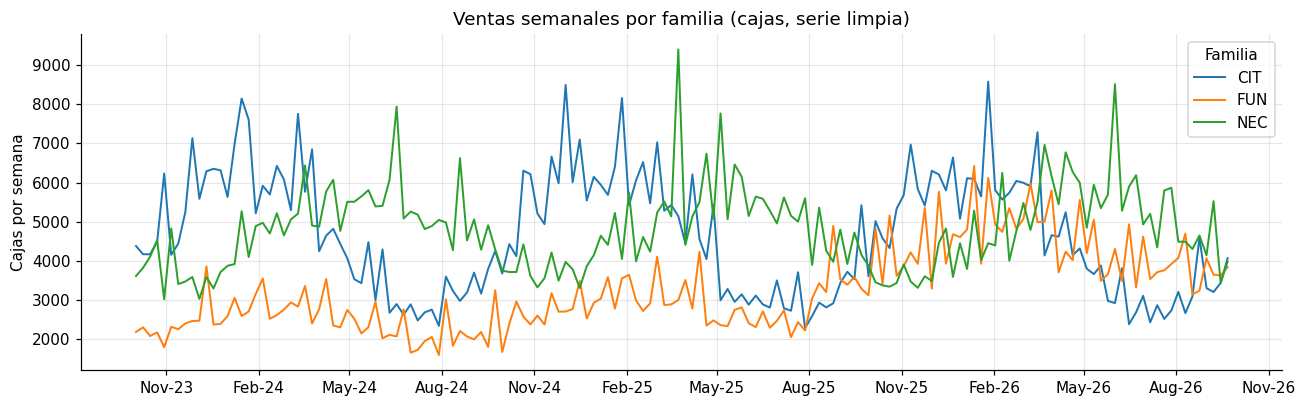

,archivo,chequeo,resultado,decision
0,calidad_llenado,Valores faltantes,0 celdas vacías,Sin acción
1,calidad_llenado,"Duplicados (subgrupo, n_obs)",0 duplicados,Sin acción
2,calidad_llenado,Tamaño de subgrupo,n = [5] en 840 subgrupos,n = 5 constante: se usan las constantes de la ...
3,calidad_llenado,"Subgrupos que mezclan línea, SKU o turno",máximo 1 valor distinto por subgrupo,Sin acción: los subgrupos son racionales
4,calidad_llenado,Volúmenes ≤ 0,0 valores,Sin acción
5,calidad_llenado,"Subgrupos por línea, formato y turno","mínimo 76, máximo 124",Se reporta el desbalance; la capacidad por tur...
6,calidad_atributos,Valores faltantes,0 celdas vacías,Sin acción
7,calidad_atributos,Filas duplicadas,0 duplicados,Sin acción
8,calidad_atributos,Defectuosas > inspeccionadas,0 filas,Sin acción
9,calidad_atributos,Tamaño de inspección n,entre 181 y 260,n varía: carta p con límites variables (no np)


In [ ]:
# Vista agregada: ventas por familia (suma de sus 3 SKU), ya limpias
familia_de = mst["familia"]
familias = sorted(familia_de.unique())
skus_de = {f: [s for s in skus if familia_de[s] == f] for f in familias}

fig, ax = plt.subplots(figsize=(12, 3.8))
for f in familias:
    ax.plot(fechas, limpia[skus_de[f]].sum(axis=1), label=f, lw=1.3)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
ax.set(title="Ventas semanales por familia (cajas, serie limpia)", ylabel="Cajas por semana")
ax.legend(title="Familia")
plt.tight_layout()
plt.show()

bit_df = pd.DataFrame(bitacora)
display(bit_df)
bit_df.to_csv(os.path.join(CONFIG["carpeta_resultados"], "bitacora_datos.csv"), index=False)

**Lectura de resultados.** Las familias no se mueven juntas. **CIT** y **FUN** tienen su peak en verano
(diciembre a febrero) y su valle en invierno. **NEC** tiene la forma contraria: sube en otoño e invierno
(abril a junio) y baja en primavera, coherente con el calendario escolar (colaciones). FUN además muestra
un **salto de nivel** a mediados de 2025. Estas dos observaciones, fases estacionales opuestas y un quiebre
estructural, condicionan toda la Parte B.



## 3. Parte A — Control estadístico y capacidad de proceso

### 3.1 Cartas X̄–R por línea × formato, Fase I y Fase II

**Qué carta usar.** Todos los subgrupos tienen $n = 5$. Con $n \le 10$ el rango $R$ estima la
dispersión casi tan bien como la desviación estándar $S$, y es más simple. Por eso corresponde la
**carta X̄–R**. La X̄–S se reserva para $n > 10$ o $n$ variable. Constantes para $n = 5$:
$A_2 = 0{,}577$, $D_3 = 0$, $D_4 = 2{,}114$, $d_2 = 2{,}326$.

$$LCS_{\bar X} = \bar{\bar x} + A_2 \bar R,\qquad LCI_{\bar X} = \bar{\bar x} - A_2 \bar R,\qquad
LCS_R = D_4 \bar R,\qquad \hat\sigma = \bar R / d_2$$

**Fase I y Fase II.** En la **Fase I** (semanas 1 a 5) se *establecen* los límites: se calculan, se
sacan los subgrupos fuera de control y se recalcula, hasta que no quede ninguno fuera. Ahí los límites
se **congelan**. En la **Fase II** (semanas 6 a 10) los subgrupos nuevos se *juzgan* contra esos límites
congelados, que **nunca se recalculan con datos de Fase II**. Recalcularlos sería una fuga: el límite se
movería con el mismo cambio que debe detectar.

**Celda siguiente.** Construye una fila por subgrupo con su media $\bar x$, su rango $R$, la fecha y hora
(que fijan el orden en el tiempo) y su turno y SKU.

In [ ]:
A2, D3, D4, d2 = 0.577, 0, 2.114, 2.326          # constantes de la carta X̄–R para n = 5
N = CONFIG["n_subgrupo"]
FASE1 = CONFIG["semanas_fase1"]

g = llen.groupby("subgrupo")
sg = g.agg(fecha=("fecha", "first"), hora=("hora", "first"), semana=("semana_registro", "first"),
           turno=("turno", "first"), linea=("linea", "first"), formato=("formato_L", "first"), sku=("sku", "first"))
sg["xbar"] = g["volumen_mL"].mean()
sg["R"] = g["volumen_mL"].max() - g["volumen_mL"].min()
sg = sg.reset_index()
sg["fecha_hora"] = pd.to_datetime(sg["fecha"] + " " + sg["hora"])   # el número de subgrupo no ordena bien en L2
sg["fase"] = np.where(sg["semana"] <= FASE1, "I", "II")

cartas = [("L1", 0.5), ("L2", 1.5), ("L2", 3.0)]
print(sg.groupby(["linea", "formato", "fase"]).size().unstack())
sg.head()

fase             I   II
linea formato          
L1    0.5      120  120
L2    1.5      136  152
      3.0      164  148


,subgrupo,fecha,hora,semana,turno,linea,formato,sku,xbar,R,fecha_hora,fase
0,1,2026-07-20,06:00,1,A (06-14),L1,0.5,FUN-B05,501.560,4.01,2026-07-20 06:00:00,I
1,2,2026-07-20,08:00,1,A (06-14),L1,0.5,FUN-B05,501.752,5.17,2026-07-20 08:00:00,I
2,3,2026-07-20,10:00,1,A (06-14),L1,0.5,FUN-B05,503.630,4.13,2026-07-20 10:00:00,I
3,4,2026-07-20,12:00,1,A (06-14),L1,0.5,FUN-B05,503.172,2.10,2026-07-20 12:00:00,I
4,5,2026-07-20,14:00,1,B (14-22),L1,0.5,CIT-L05,503.396,8.49,2026-07-20 14:00:00,I


**Función de Fase I.** Es la misma lógica de rondas del cálculo original, pero dentro de un ciclo
`while` que repite hasta que no quede ningún punto fuera. Así no depende de cuántas rondas se escriban
a mano, y el mismo código sirve para las tres cartas. La función devuelve los límites congelados, el
registro de cada ronda y los subgrupos excluidos.

In [ ]:
def limites_fase1(c):
    """Calcula los límites X̄–R con la Fase I, sacando puntos fuera hasta que no quede ninguno."""
    f1 = c[c["fase"] == "I"].copy()
    rondas = []
    while True:
        xbb, Rb = f1["xbar"].mean(), f1["R"].mean()
        LCSx, LCIx, LCSr = xbb + A2 * Rb, xbb - A2 * Rb, D4 * Rb
        fuera = f1[(f1["R"] > LCSr) | (f1["xbar"] > LCSx) | (f1["xbar"] < LCIx)]
        rondas.append({"ronda": len(rondas) + 1, "subgrupos": len(f1), "x_doble_barra": xbb, "R_barra": Rb,
                       "puntos_fuera": len(fuera)})
        if len(fuera) == 0:
            break
        f1 = f1.drop(fuera.index)
    lim = {"xbb": xbb, "Rb": Rb, "LCSx": LCSx, "LCIx": LCIx, "LCSr": LCSr, "LCIr": D3 * Rb, "sigma": Rb / d2,
           "subgrupos_estables": f1["subgrupo"].tolist()}
    return lim, pd.DataFrame(rondas)


def preparar_carta(linea, formato):
    c = sg[(sg["linea"] == linea) & (sg["formato"] == formato)].sort_values("fecha_hora").reset_index(drop=True)
    c["orden"] = c.index + 1
    return c


lims, datos_carta, resumen, excluidos_todos = {}, {}, [], []
for linea, formato in cartas:
    c = preparar_carta(linea, formato)
    lim, rondas = limites_fase1(c)
    # control de fuga: los límites solo usan subgrupos de Fase I
    assert c[c["subgrupo"].isin(lim["subgrupos_estables"])]["semana"].max() <= FASE1

    c["fuera_x"] = (c["xbar"] > lim["LCSx"]) | (c["xbar"] < lim["LCIx"])
    c["fuera_r"] = (c["R"] > lim["LCSr"]) | (c["R"] < lim["LCIr"])
    lims[(linea, formato)], datos_carta[(linea, formato)] = lim, c

    excl = c[(c["fase"] == "I") & ~c["subgrupo"].isin(lim["subgrupos_estables"])]
    excluidos_todos.append(excl.assign(carta=f"{linea} {formato} L"))
    f2 = c[c["fase"] == "II"]
    resumen.append([linea, formato, (c["fase"] == "I").sum(), len(excl), len(rondas), lim["xbb"], lim["Rb"],
                    lim["LCSx"], lim["LCIx"], lim["LCSr"], lim["sigma"], f2["fuera_x"].sum(), f2["fuera_r"].sum(), len(f2)])
    print(f"\n{linea} {formato} L — rondas de Fase I")
    display(rondas.round(2))

res = pd.DataFrame(resumen, columns=["linea", "formato", "n_fase1", "excluidos", "rondas", "xbb", "Rb", "LCSx", "LCIx",
                                     "LCSr", "sigma", "f2_fuera_x", "f2_fuera_r", "n_fase2"])
print("\nLímites congelados de Fase I y resultado de la Fase II")
display(res.round(3))
print("\nSubgrupos de Fase I excluidos del cálculo de límites")
display(pd.concat(excluidos_todos)[["carta", "orden", "fecha_hora", "turno", "sku", "xbar", "R"]].round(2))


L1 0.5 L — rondas de Fase I


,ronda,subgrupos,x_doble_barra,R_barra,puntos_fuera
0,1,120,502.47,4.86,0



L2 1.5 L — rondas de Fase I


,ronda,subgrupos,x_doble_barra,R_barra,puntos_fuera
0,1,136,1504.55,12.01,5
1,2,131,1504.35,11.57,1
2,3,130,1504.30,11.56,0



L2 3.0 L — rondas de Fase I


,ronda,subgrupos,x_doble_barra,R_barra,puntos_fuera
0,1,164,3008.89,19.81,6
1,2,158,3008.73,19.16,0



Límites congelados de Fase I y resultado de la Fase II


,linea,formato,n_fase1,excluidos,rondas,xbb,Rb,LCSx,LCIx,LCSr,sigma,f2_fuera_x,f2_fuera_r,n_fase2
0,L1,0.5,120,0,1,502.467,4.863,505.274,499.661,10.281,2.091,91,0,120
1,L2,1.5,136,6,3,1504.296,11.559,1510.966,1497.626,24.436,4.970,6,4,152
2,L2,3.0,164,6,2,3008.725,19.159,3019.780,2997.671,40.502,8.237,0,2,148



Subgrupos de Fase I excluidos del cálculo de límites


,carta,orden,fecha_hora,turno,sku,xbar,R
3,L2 1.5 L,4,2026-07-20 22:00:00,C (22-06),NEC-D15,1505.64,25.95
31,L2 1.5 L,32,2026-07-28 22:00:00,C (22-06),NEC-D15,1513.75,9.26
72,L2 1.5 L,73,2026-08-07 00:00:00,C (22-06),FUN-B15,1510.65,27.57
74,L2 1.5 L,75,2026-08-07 04:00:00,C (22-06),FUN-B15,1508.44,26.43
79,L2 1.5 L,80,2026-08-07 22:00:00,C (22-06),FUN-B15,1510.72,28.13
81,L2 1.5 L,82,2026-08-10 02:00:00,C (22-06),NEC-D15,1511.32,13.43
23,L2 3.0 L,24,2026-07-22 22:00:00,C (22-06),FUN-B30,3023.59,21.08
69,L2 3.0 L,70,2026-08-03 02:00:00,C (22-06),FUN-B30,3010.47,43.43
102,L2 3.0 L,103,2026-08-11 04:00:00,C (22-06),FUN-B30,3021.06,20.58
141,L2 3.0 L,142,2026-08-19 02:00:00,C (22-06),NEC-D30,3005.37,43.67


**Lectura de resultados.**
- **L1 0,5 L.** La Fase I es estable desde la primera ronda: $\bar{\bar x}$ = 502,47 mL, $\bar R$ = 4,86 mL,
  $\hat\sigma$ = 2,09 mL y límites [499,66; 505,27]. En la Fase II, **91 de 120 subgrupos quedan sobre el
  LCS** y ninguno fuera en la carta R: cambió la **media**, no la variabilidad.
- **L2 1,5 L.** Hicieron falta 3 rondas para estabilizar, con 6 subgrupos excluidos, **todos del turno C
  (22 a 06 h)**. En la Fase II hay 6 puntos fuera en X̄ y 4 en R.
- **L2 3,0 L.** 2 rondas y 6 excluidos, 5 de ellos del turno C. En la Fase II hay 0 puntos fuera en X̄ y 2 en R.

Que casi todos los excluidos sean del turno nocturno es la primera pista de causa asignable en L2.

**Gráficos.** Cada carta muestra la Fase I y la Fase II separadas por la línea vertical, con los límites
congelados de Fase I. Los puntos rojos están fuera de los límites. Las etiquetas de los límites van en el
margen derecho para que no tapen los datos.

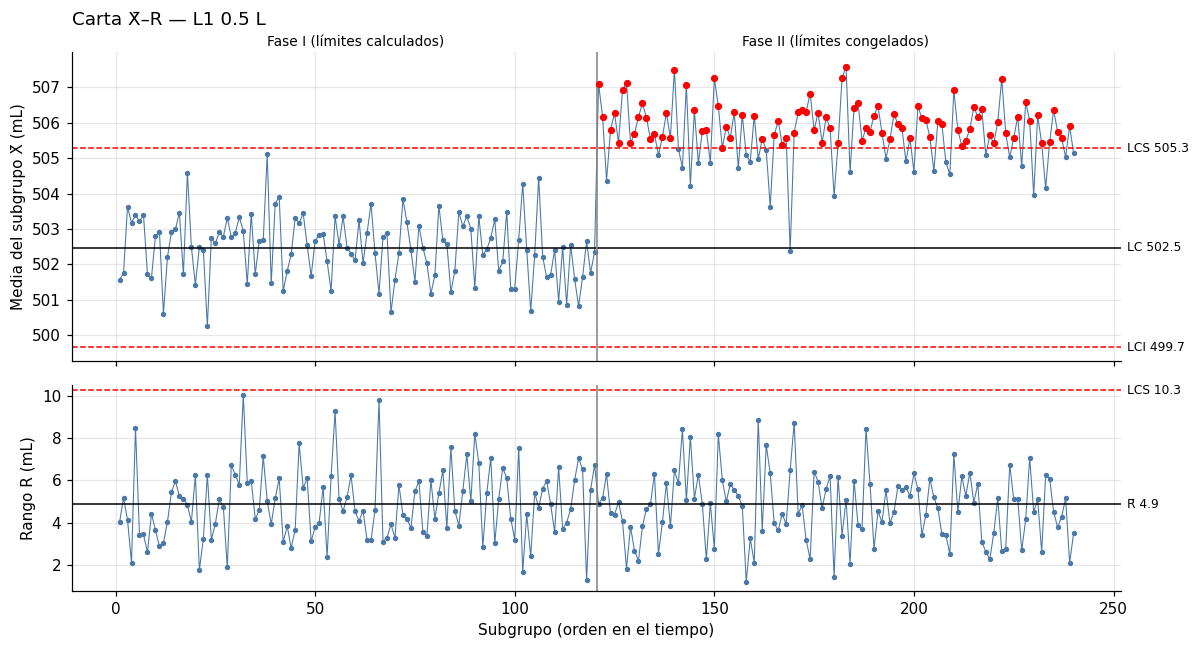

In [ ]:
def graficar_xr(linea, formato):
    c, lim = datos_carta[(linea, formato)], lims[(linea, formato)]
    corte = c.loc[c["fase"] == "I", "orden"].max() + 0.5
    fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
    ax[0].plot(c["orden"], c["xbar"], "o-", ms=2.5, lw=0.7, color="#4a78a8")
    ax[0].scatter(c.loc[c["fuera_x"], "orden"], c.loc[c["fuera_x"], "xbar"], color="red", s=14, zorder=5)
    for y, nombre in [(lim["LCSx"], "LCS"), (lim["xbb"], "LC"), (lim["LCIx"], "LCI")]:
        ax[0].axhline(y, color="black" if nombre == "LC" else "red", ls="-" if nombre == "LC" else "--", lw=1)
        ax[0].text(1.005, y, f"{nombre} {y:.1f}", transform=ax[0].get_yaxis_transform(), va="center", fontsize=8)
    ax[1].plot(c["orden"], c["R"], "o-", ms=2.5, lw=0.7, color="#4a78a8")
    ax[1].scatter(c.loc[c["fuera_r"], "orden"], c.loc[c["fuera_r"], "R"], color="red", s=14, zorder=5)
    for y, nombre in [(lim["LCSr"], "LCS"), (lim["Rb"], "R̄")]:
        ax[1].axhline(y, color="red" if nombre == "LCS" else "black", ls="--" if nombre == "LCS" else "-", lw=1)
        ax[1].text(1.005, y, f"{nombre} {y:.1f}", transform=ax[1].get_yaxis_transform(), va="center", fontsize=8)
    for a in ax:
        a.axvline(corte, color="gray", lw=1)
    ax[0].text(corte / 2, 1.02, "Fase I (límites calculados)", transform=ax[0].get_xaxis_transform(), ha="center", fontsize=9)
    ax[0].text((corte + c["orden"].max()) / 2, 1.02, "Fase II (límites congelados)", transform=ax[0].get_xaxis_transform(),
               ha="center", fontsize=9)
    ax[0].set_ylabel("Media del subgrupo X̄ (mL)")
    ax[0].set_title(f"Carta X̄–R — {linea} {formato} L", loc="left", pad=18)
    ax[1].set(xlabel="Subgrupo (orden en el tiempo)", ylabel="Rango R (mL)")
    plt.tight_layout()
    plt.show()

graficar_xr("L1", 0.5)

**Lectura de resultados.** El quiebre es nítido. Desde el primer subgrupo de la semana 6 (lunes
24/08/2026) la media salta a ≈ 505,7 mL y se queda ahí. La carta R no cambia: la dispersión es la misma
antes y después. Es el patrón típico de un **cambio de ajuste (setpoint) de la llenadora**, no de desgaste,
que aumentaría el rango.

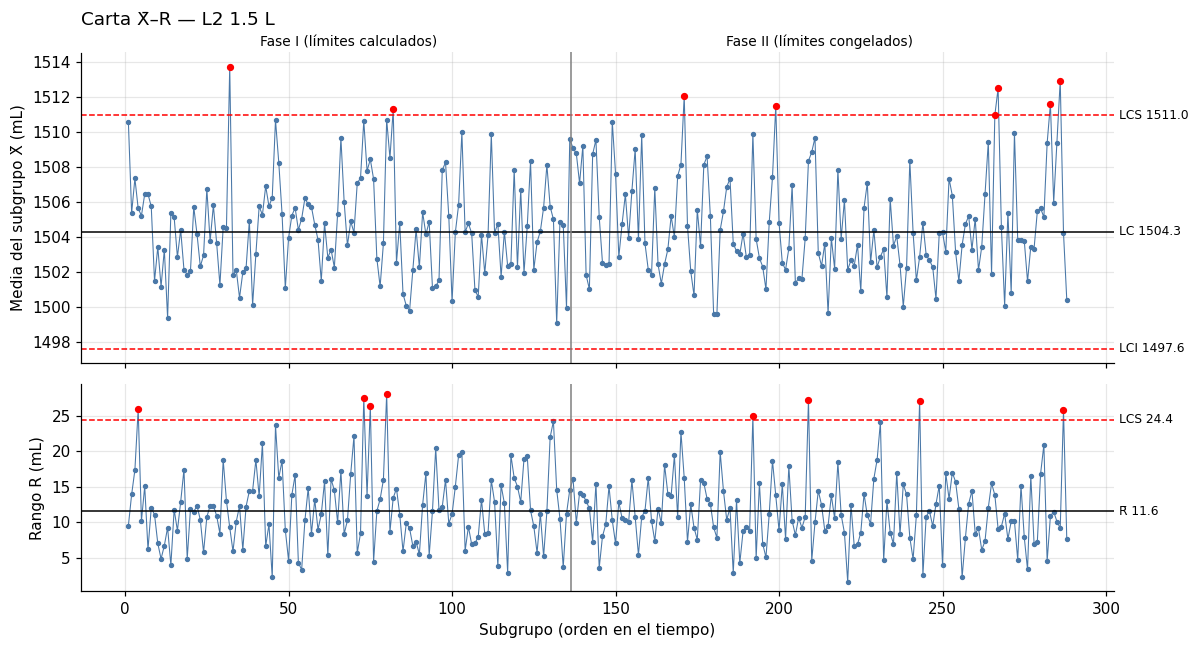

In [ ]:
graficar_xr("L2", 1.5)

**Lectura de resultados.** No hay un cambio de nivel entre fases. Hay puntos dispersos sobre el LCS y
rangos altos que se repiten durante todo el periodo. Es un proceso «bajo control» en el sentido estrecho
(pocas señales), pero con una fuente de variación recurrente: el turno C, como se verá en 3.2.

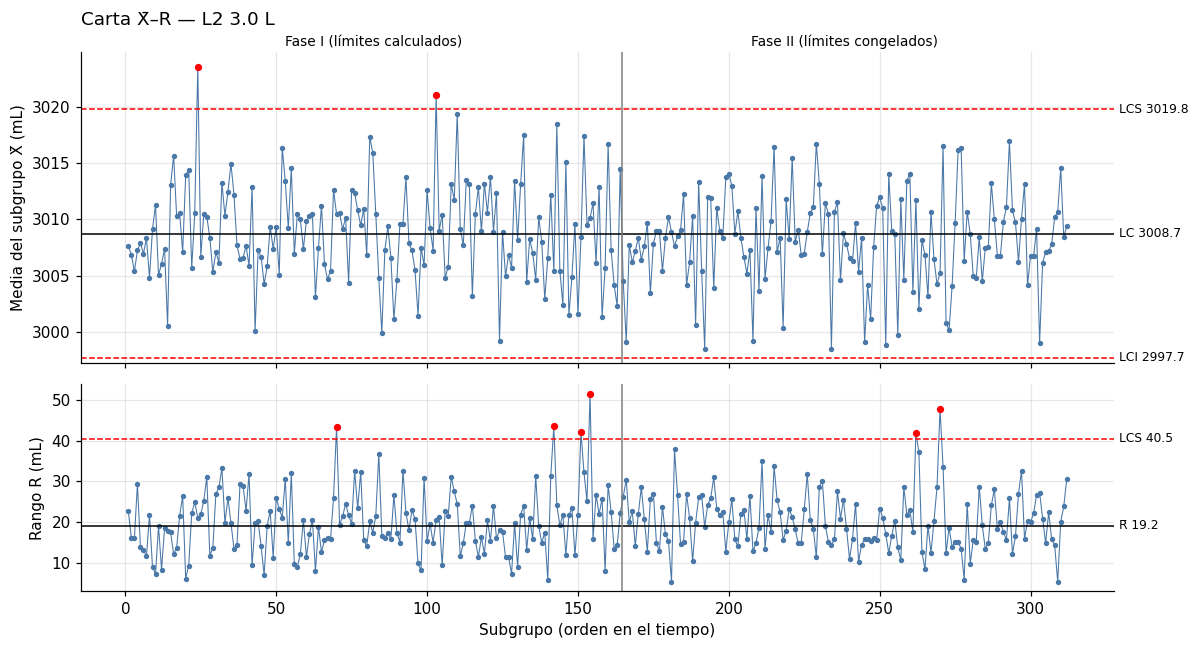

In [ ]:
graficar_xr("L2", 3.0)

**Lectura de resultados.** Es la carta más estable. En la Fase II ninguna media sale de los límites y solo
dos rangos superan el LCS. Que esté bajo control no significa que sea capaz: los límites de control reflejan
la variación del proceso, no la especificación (sección 3.3).

### 3.2 Reglas de decisión (Western Electric) y causas asignables

Un punto fuera de los límites no es la única señal. Las **reglas de Western Electric** buscan patrones
que serían muy poco probables si solo actuaran causas comunes. Se aplican sobre la media estandarizada
con los parámetros congelados de Fase I:

$$z_i = \frac{\bar x_i - \bar{\bar x}}{\hat\sigma/\sqrt{n}}$$

| Regla | Señal | Detecta |
|---|---|---|
| R1 | 1 punto a más de 3σ | salto grande |
| R2 | 2 de 3 puntos seguidos a más de 2σ, del mismo lado | corrimiento moderado |
| R3 | 4 de 5 puntos seguidos a más de 1σ, del mismo lado | corrimiento pequeño sostenido |
| R4 | 8 puntos seguidos del mismo lado de la LC | cambio de nivel persistente |
| R alta | rango sobre $LCS_R$ | aumento de la variabilidad |

In [ ]:
def reglas_we(z):
    r1 = z.abs() > 3
    r2 = ((z > 2).astype(int).rolling(3).sum() >= 2) | ((z < -2).astype(int).rolling(3).sum() >= 2)
    r3 = ((z > 1).astype(int).rolling(5).sum() >= 4) | ((z < -1).astype(int).rolling(5).sum() >= 4)
    r4 = ((z > 0).astype(int).rolling(8).sum() == 8) | ((z < 0).astype(int).rolling(8).sum() == 8)
    return r1, r2, r3, r4

senales, filas = {}, []
for linea, formato in cartas:
    c, lim = datos_carta[(linea, formato)].copy(), lims[(linea, formato)]
    c["z"] = (c["xbar"] - lim["xbb"]) / (lim["sigma"] / np.sqrt(N))
    c["R1"], c["R2"], c["R3"], c["R4"] = reglas_we(c["z"])
    c["R_alta"] = c["R"] > lim["LCSr"]
    c["senal"] = c[["R1", "R2", "R3", "R4", "R_alta"]].any(axis=1)
    senales[(linea, formato)] = c
    for fase in ["I", "II"]:
        d = c[c["fase"] == fase]
        filas.append([f"{linea} {formato} L", fase, len(d), d["R1"].sum(), d["R2"].sum(), d["R3"].sum(),
                      d["R4"].sum(), d["R_alta"].sum(), d["senal"].sum(), 100 * d["senal"].mean()])

tabla_we = pd.DataFrame(filas, columns=["carta", "fase", "subgrupos", "R1", "R2", "R3", "R4", "R alta",
                                        "con señal", "% con señal"])
display(tabla_we.round(1))

,carta,fase,subgrupos,R1,R2,R3,R4,R alta,con señal,% con señal
0,L1 0.5 L,I,120,0,0,0,2,0,2,1.7
1,L1 0.5 L,II,120,91,119,117,105,0,120,100.0
2,L2 1.5 L,I,136,2,1,4,3,4,12,8.8
3,L2 1.5 L,II,152,6,19,4,1,4,25,16.4
4,L2 3.0 L,I,164,2,0,0,2,4,8,4.9
5,L2 3.0 L,II,148,0,5,1,1,2,9,6.1


**Lectura de resultados.** En **L1** el **100 % de los subgrupos de Fase II** activa alguna regla. Además de
los puntos fuera (R1), casi todos cumplen R2, R3 y R4: es un corrimiento sostenido. En la Fase I solo hay 2
señales (R4), de esperar como falsas alarmas. En **L2 1,5 L** las señales suben de 8,8 % (Fase I) a 16,4 %
(Fase II) y se reparten entre R1, R2 y R alta. En **L2 3,0 L** se mantienen bajas (≈ 5 a 6 %).

**Contraste con los campos disponibles (turno, semana, SKU).** Para proponer una causa asignable hay que
ver *dónde* se concentran las señales. Una causa que actúa en todas las semanas de Fase II, en todos los
turnos y en todos los SKU apunta a la máquina o a su ajuste. Una causa que aparece en un solo turno apunta
a la operación de ese turno.

In [ ]:
todos = pd.concat([d.assign(carta=f"{l} {f} L") for (l, f), d in senales.items()], ignore_index=True)

print("Media de X̄ por semana (mL) — la Fase I son las semanas 1 a 5")
display(todos.pivot_table(index="carta", columns="semana", values="xbar", aggfunc="mean").round(1))
print("Subgrupos con señal por semana")
display(todos.pivot_table(index="carta", columns="semana", values="senal", aggfunc="sum"))

por_turno = todos.groupby(["carta", "fase", "turno"]).agg(subgrupos=("senal", "size"), con_senal=("senal", "sum"),
                                                          xbar_medio=("xbar", "mean"), R_medio=("R", "mean"))
por_turno["%_con_senal"] = 100 * por_turno["con_senal"] / por_turno["subgrupos"]
print("Señales, media y rango por carta, fase y turno")
display(por_turno.round(2))

por_sku = todos.groupby(["carta", "sku"]).agg(subgrupos=("senal", "size"), con_senal=("senal", "sum"),
                                              xbar_medio=("xbar", "mean"), R_medio=("R", "mean"))
por_sku["%_con_senal"] = 100 * por_sku["con_senal"] / por_sku["subgrupos"]
print("Señales por SKU")
display(por_sku.round(2))

Media de X̄ por semana (mL) — la Fase I son las semanas 1 a 5


semana,1,2,3,4,5,6,7,8,9,10
carta,,,,,,,,,,
L1 0.5 L,502.5,502.8,502.5,502.5,502.1,505.9,505.6,505.9,505.7,505.6
L2 1.5 L,1504.3,1504.6,1505.4,1504.0,1504.7,1505.8,1504.6,1504.2,1503.6,1505.3
L2 3.0 L,3009.1,3008.2,3008.7,3010.7,3008.4,3007.7,3008.5,3007.8,3007.8,3008.7


Subgrupos con señal por semana


semana,1,2,3,4,5,6,7,8,9,10
carta,,,,,,,,,,
L1 0.5 L,0,2,0,0,0,24,24,24,24,24
L2 1.5 L,2,2,7,1,0,8,4,4,1,8
L2 3.0 L,2,0,1,1,4,2,0,2,5,0


Señales, media y rango por carta, fase y turno


subgrupos  con_senal  xbar_medio  R_medio  %_con_senal
carta    fase turno                                                            
L1 0.5 L I    A (06-14)         60          0      502.38     4.81         0.00
              B (14-22)         60          2      502.56     4.92         3.33
         II   A (06-14)         60         60      505.67     4.89       100.00
              B (14-22)         60         60      505.77     4.59       100.00
L2 1.5 L I    A (06-14)         64          5     1503.29    10.31         7.81
              B (14-22)         24          0     1503.31    11.09         0.00
              C (22-06)         48          7     1506.86    14.74        14.58
         II   A (06-14)         44          6     1503.00    10.18        13.64
              B (14-22)         52          1     1503.76    10.61         1.92
              C (22-06)         56         18     1506.76    13.25        32.14
L2 3.0 L I    A (06-14)         36          0     3007.56    18.72         0.00
              B (14-22)         76          2     3007.83    17.79         2.63
              C (22-06)         52          6     3011.35    23.53        11.54
         II   A (06-14)         56          3     3007.29    19.45         5.36
              B (14-22)         48          3     3007.40    19.68         6.25
              C (22-06)         44          3     3009.80    21.73         6.82

Señales por SKU


subgrupos  con_senal  xbar_medio  R_medio  %_con_senal
carta    sku                                                            
L1 0.5 L CIT-L05         96         42      503.86     5.06        43.75
         FUN-B05         64         32      504.05     5.02        50.00
         NEC-D05         80         48      504.41     4.32        60.00
L2 1.5 L CIT-L15         88          6     1503.63    10.74         6.82
         FUN-B15        104         18     1505.34    12.34        17.31
         NEC-D15         96         13     1504.69    11.94        13.54
L2 3.0 L CIT-L30        136          8     3007.88    19.32         5.88
         FUN-B30         80          5     3009.30    19.44         6.25
         NEC-D30         96          4     3008.71    21.43         4.17

**Lectura de resultados (contraste con turno, semana y SKU).**
- **L1:** la media pasa de 502,5 mL (semanas 1 a 5) a 505,7 mL (semanas 6 a 10). Las 5 semanas de la
  Fase II tienen 24 de 24 subgrupos con señal, **en ambos turnos por igual** (A: 505,67; B: 505,77) y en los
  **tres SKU**. Una causa que no distingue turno ni producto y empieza un día preciso es una **intervención
  sobre la máquina**, un reajuste del setpoint de llenado de L1 el 24/08/2026, por ejemplo tras una
  mantención o un cambio de boquillas. Se debe pedir la bitácora de mantención de esa fecha para confirmarlo.
- **L2:** las señales se concentran en el **turno C**. En 1,5 L el 72 % de las señales de Fase II son del
  turno C, que llena en promedio 1.506,8 mL contra 1.503,0 y 1.503,8 de los turnos A y B, con rangos más
  altos (≈ 13 a 15 mL contra ≈ 10 a 11). En 3,0 L el turno C también es el más alto (3.011 mL en Fase I) y
  el más disperso. La causa plausible es **operacional del turno nocturno**: un ajuste propio de la
  llenadora («llenar de más por seguridad»), menos supervisión o recalibraciones al inicio del turno.
- Las diferencias por SKU de L2 (FUN y NEC parecen peores que CIT) **pueden ser un efecto del turno**,
  porque CIT-L15 casi no se envasa de noche. La celda siguiente lo separa.

**¿Es el turno o es el SKU?** En L2 los SKU no se reparten igual entre turnos (CIT-L15 casi no se envasa
de noche). Un «efecto SKU» podría ser solo el efecto del turno donde se produce ese SKU. Por eso se hace un
ANOVA de dos factores (turno + SKU) sobre $\bar x$ en la **Fase I estable**, que separa ambos efectos.
También se compara el rango medio por turno con Kruskal-Wallis (el rango no es normal).

In [ ]:
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm

filas = []
for linea, formato in cartas:
    c = senales[(linea, formato)]
    est = c[c["subgrupo"].isin(lims[(linea, formato)]["subgrupos_estables"])]
    modelo = ols("xbar ~ C(turno) + C(sku)", data=est).fit()
    tabla = anova_lm(modelo, typ=2)
    p_rango = stats.kruskal(*[g["R"] for _, g in est.groupby("turno")]).pvalue
    filas.append([f"{linea} {formato} L", tabla.loc["C(turno)", "PR(>F)"], tabla.loc["C(sku)", "PR(>F)"], p_rango])

anova = pd.DataFrame(filas, columns=["carta", "p_valor turno (media)", "p_valor SKU (media)", "p_valor turno (rango)"])
display(anova.round(4))

c = senales[("L2", 1.5)]
print("L2 1,5 L, Fase I: media de X̄ por SKU y turno")
display(c[c["fase"] == "I"].pivot_table(index="sku", columns="turno", values="xbar", aggfunc="mean").round(1))

,carta,p_valor turno (media),p_valor SKU (media),p_valor turno (rango)
0,L1 0.5 L,0.1038,0.3381,0.7789
1,L2 1.5 L,0.0000,0.3544,0.0024
2,L2 3.0 L,0.0000,0.3059,0.0027


L2 1,5 L, Fase I: media de X̄ por SKU y turno


turno,A (06-14),B (14-22),C (22-06)
sku,,,
CIT-L15,1503.0,1503.3,NaN
FUN-B15,1503.8,1503.6,1506.9
NEC-D15,1503.2,1502.7,1506.8


**Lectura de resultados.** Con turno y SKU en el mismo modelo, el **turno es significativo** en ambas
cartas de L2 (p < 0,0001), tanto en la media como en el rango (Kruskal-Wallis p ≈ 0,002 a 0,003). El
**SKU deja de serlo** (p = 0,35 y 0,31). La tabla lo confirma: dentro de cada turno los tres SKU llenan casi
igual (≈ 1.503 mL en A y B), y FUN-B15 y NEC-D15 suben a ≈ 1.507 mL *solo* en el turno C. El aparente
«efecto SKU» de un ANOVA de un factor era el turno disfrazado. En L1 ni turno ni SKU son significativos en
la Fase I, coherente con que su problema es un evento puntual (el reajuste), no una diferencia crónica.

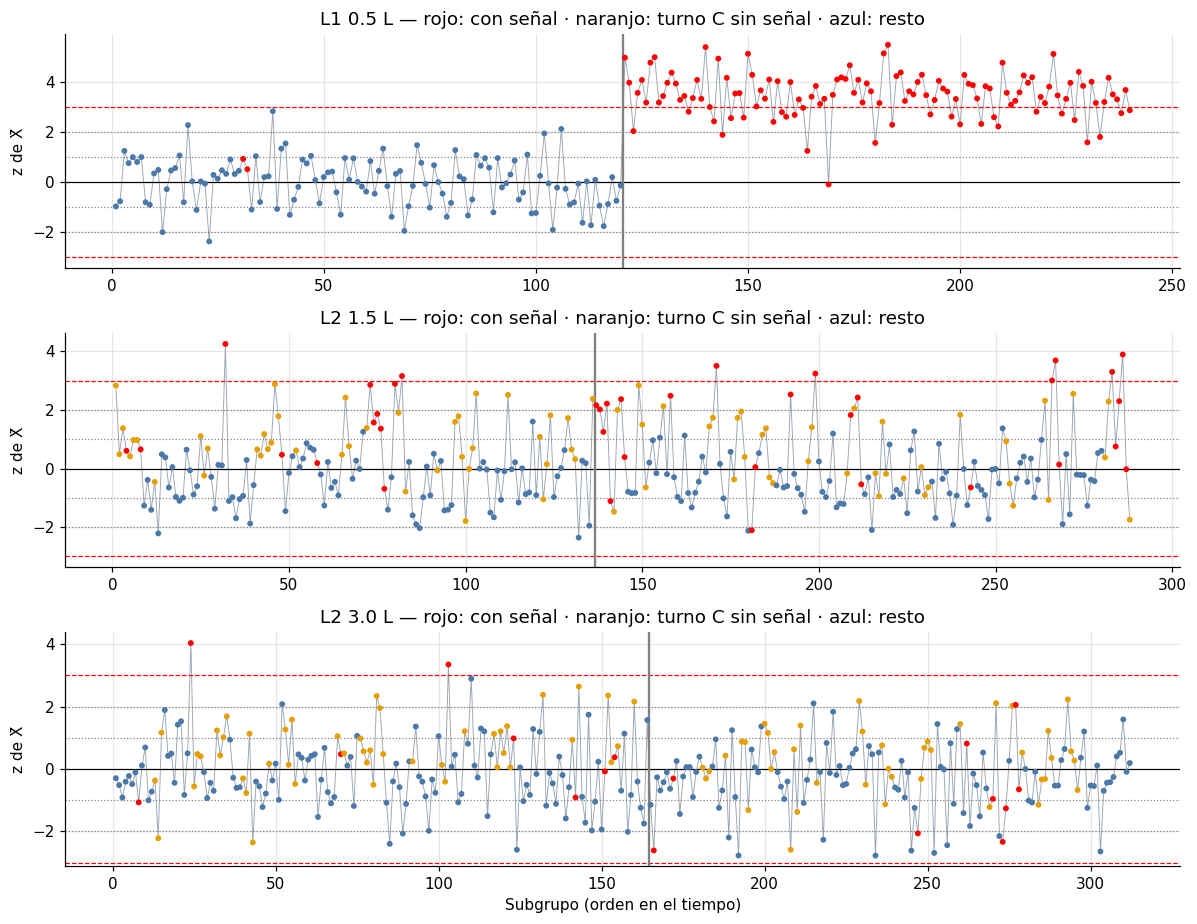

In [ ]:
# Gráfico de z con las zonas de 1, 2 y 3 sigma (rojo = subgrupo con alguna señal)
fig, ejes = plt.subplots(3, 1, figsize=(11, 8.5), sharex=False)
for ax, (linea, formato) in zip(ejes, cartas):
    c = senales[(linea, formato)]
    ax.plot(c["orden"], c["z"], "-", color="#9aa5b1", lw=0.6)
    colores = np.where(c["senal"], "red", np.where(c["turno"].str.startswith("C"), "#e69f00", "#4a78a8"))
    ax.scatter(c["orden"], c["z"], c=colores, s=8, zorder=3)
    for zl, est in [(3, "--"), (2, ":"), (1, ":")]:
        ax.axhline(zl, color="red" if zl == 3 else "gray", ls=est, lw=0.8)
        ax.axhline(-zl, color="red" if zl == 3 else "gray", ls=est, lw=0.8)
    ax.axhline(0, color="black", lw=0.8)
    ax.axvline(c.loc[c["fase"] == "I", "orden"].max() + 0.5, color="gray")
    ax.set(ylabel="z de X̄", title=f"{linea} {formato} L — rojo: con señal · naranjo: turno C sin señal · azul: resto")
ejes[-1].set_xlabel("Subgrupo (orden en el tiempo)")
plt.tight_layout()
plt.show()

In [ ]:
# Tabla de causas asignables: se agrupan las señales y se contrastan con semana, turno y SKU
causas = (todos[todos["senal"]].groupby(["carta", "fase"])
          .agg(subgrupos_con_senal=("senal", "size"),
               semanas=("semana", lambda s: sorted(s.unique().tolist())),
               turno_mas_frecuente=("turno", lambda s: s.value_counts().index[0]),
               pct_en_ese_turno=("turno", lambda s: round(100 * s.value_counts().iloc[0] / len(s), 1)),
               skus=("sku", "nunique"),
               z_medio=("z", "mean")))
display(causas.round(2))

subgrupos_con_senal           semanas turno_mas_frecuente  pct_en_ese_turno  skus  z_medio
carta    fase                                                                                            
L1 0.5 L I                       2               [2]           B (14-22)             100.0     1     0.72
         II                    120  [6, 7, 8, 9, 10]           A (06-14)              50.0     3     3.48
L2 1.5 L I                      12      [1, 2, 3, 4]           C (22-06)              58.3     3     1.60
         II                     25  [6, 7, 8, 9, 10]           C (22-06)              72.0     3     1.57
L2 3.0 L I                       8      [1, 3, 4, 5]           C (22-06)              75.0     3     0.89
         II                      9         [6, 8, 9]           A (06-14)              33.3     3    -0.81

**Lectura de resultados.** El gráfico z y la tabla resumen la causa asignable de cada carta:

| Carta | Señal | Dónde se concentra | Causa asignable propuesta | Acción |
|---|---|---|---|---|
| L1 0,5 L | Corrimiento +3,25 mL desde el 24/08 (R1 a R4) | Todas las semanas de Fase II, ambos turnos, 3 SKU | Reajuste del setpoint de la llenadora L1 | Recentrar la media (barato) |
| L2 1,5 L | Puntos altos y rangos altos recurrentes | Turno C (72 % de las señales) | Práctica de llenado del turno nocturno | Estandarizar el ajuste y la supervisión del turno C |
| L2 3,0 L | Pocas señales, rangos altos ocasionales | Turno C en Fase I | Mismo patrón nocturno, más débil | Igual que 1,5 L |

### 3.3 Capacidad de proceso: Cp, Cpk, Pp y Ppk (global y por turno), normalidad y límite legal

La capacidad solo tiene sentido en un **proceso estable**. Por eso los índices se calculan con los
subgrupos de la **Fase I estable** (los que quedaron dentro de los límites). Se usan dos sigmas:

- **Cp y Cpk** usan la $\sigma$ de *corto plazo* $= \bar R/d_2$, la variación dentro del subgrupo. Miden
  lo que el proceso *puede* hacer.
- **Pp y Ppk** usan la $\sigma$ de *largo plazo* (desviación estándar de todas las botellas). Miden lo que
  el proceso *hace* realmente.

$$C_p = \frac{LSE-LIE}{6\sigma},\qquad C_{pk}=\frac{\min(LSE-\mu,\ \mu-LIE)}{3\sigma}$$

Si Cp ≈ Cpk el proceso está centrado. Si Cp > Cpk está **descentrado**: el problema es la **media**.
Si Cp < 1,33 el problema es la **variabilidad**: aunque se centre, no cabe en la tolerancia.

In [ ]:
def indices(d, LIE, LSE):
    """Cp, Cpk (sigma corto plazo = R̄/d2) y Pp, Ppk (sigma largo plazo) de un conjunto de botellas."""
    grupos = d.groupby("subgrupo")["volumen_mL"]
    mu = d["volumen_mL"].mean()
    s_c = (grupos.max() - grupos.min()).mean() / d2
    s_l = d["volumen_mL"].std(ddof=1)
    return {"subgrupos": grupos.ngroups, "media": mu, "sigma_corto": s_c, "sigma_largo": s_l,
            "Cp": (LSE - LIE) / (6 * s_c), "Cpk": min(LSE - mu, mu - LIE) / (3 * s_c),
            "Pp": (LSE - LIE) / (6 * s_l), "Ppk": min(LSE - mu, mu - LIE) / (3 * s_l)}

capacidades, desempeno = [], []
for linea, formato in cartas:
    LIE, LSE = esp.loc[formato, "LIE_mL"], esp.loc[formato, "LSE_mL"]
    d1 = llen[llen["subgrupo"].isin(lims[(linea, formato)]["subgrupos_estables"])]          # Fase I estable
    d2_ = llen[(llen["linea"] == linea) & (llen["formato_L"] == formato) & (llen["semana_registro"] > FASE1)]
    capacidades.append({"linea": linea, "formato": formato, "grupo": "Global", **indices(d1, LIE, LSE)})
    desempeno.append({"linea": linea, "formato": formato, "grupo": "Global", **indices(d2_, LIE, LSE)})
    for turno in sorted(d1["turno"].unique()):
        capacidades.append({"linea": linea, "formato": formato, "grupo": turno, **indices(d1[d1["turno"] == turno], LIE, LSE)})
        desempeno.append({"linea": linea, "formato": formato, "grupo": turno, **indices(d2_[d2_["turno"] == turno], LIE, LSE)})

tabla_cap = pd.DataFrame(capacidades)
tabla_cap["Cp/Cpk"] = tabla_cap["Cp"] / tabla_cap["Cpk"]
print("CAPACIDAD — Fase I estable (proceso bajo control)")
display(tabla_cap.round(2))

tabla_f2 = pd.DataFrame(desempeno)[["linea", "formato", "grupo", "subgrupos", "media", "sigma_largo", "Pp", "Ppk"]]
print("DESEMPEÑO — Fase II (solo Pp y Ppk: si el proceso no está bajo control, Cp y Cpk no aplican)")
display(tabla_f2.round(2))

CAPACIDAD — Fase I estable (proceso bajo control)


,linea,formato,grupo,subgrupos,media,sigma_corto,sigma_largo,Cp,Cpk,Pp,Ppk,Cp/Cpk
0,L1,0.5,Global,120,502.47,2.09,2.06,1.28,0.88,1.30,0.90,1.45
1,L1,0.5,A (06-14),60,502.38,2.07,2.01,1.29,0.91,1.33,0.93,1.42
2,L1,0.5,B (14-22),60,502.56,2.12,2.10,1.26,0.86,1.27,0.86,1.47
3,L2,1.5,Global,130,1504.30,4.97,5.15,1.01,0.72,0.97,0.69,1.40
4,L2,1.5,A (06-14),64,1503.29,4.43,4.44,1.13,0.88,1.12,0.88,1.28
5,L2,1.5,B (14-22),24,1503.31,4.77,4.53,1.05,0.82,1.10,0.86,1.28
6,L2,1.5,C (22-06),42,1506.40,5.90,5.82,0.85,0.49,0.86,0.49,1.74
7,L2,3.0,Global,158,3008.73,8.24,8.43,1.01,0.66,0.99,0.64,1.54
8,L2,3.0,A (06-14),36,3007.56,8.05,8.29,1.04,0.72,1.01,0.70,1.43
9,L2,3.0,B (14-22),75,3007.83,7.51,7.61,1.11,0.76,1.10,0.75,1.46


DESEMPEÑO — Fase II (solo Pp y Ppk: si el proceso no está bajo control, Cp y Cpk no aplican)


,linea,formato,grupo,subgrupos,media,sigma_largo,Pp,Ppk
0,L1,0.5,Global,120,505.72,2.02,1.32,0.38
1,L1,0.5,A (06-14),60,505.67,2.08,1.28,0.37
2,L1,0.5,B (14-22),60,505.77,1.95,1.36,0.38
3,L2,1.5,Global,152,1504.65,5.37,0.93,0.64
4,L2,1.5,A (06-14),44,1503.00,4.40,1.14,0.91
5,L2,1.5,B (14-22),52,1503.76,4.51,1.11,0.83
6,L2,1.5,C (22-06),56,1506.76,6.07,0.82,0.45
7,L2,3.0,Global,148,3008.07,8.82,0.95,0.64
8,L2,3.0,A (06-14),56,3007.29,8.45,0.99,0.70
9,L2,3.0,B (14-22),48,3007.40,8.33,1.00,0.70



- **L1 0,5 L:** Cp = 1,28 y Cpk = 0,88 en la Fase I. La razón Cp/Cpk = 1,45 indica un **problema de
  media**: el proceso cabe casi en la tolerancia (Cp cercano a 1,33), pero está corrido 2,5 mL hacia el LSE.
  En la Fase II la media sube a 505,7 mL y el **Ppk cae a 0,38** con el Pp intacto (1,32): mismo ancho,
  mucho más descentrado. Ambos turnos son prácticamente iguales.
- **L2 1,5 L y 3,0 L:** Cp = 1,01 en ambos. **Aunque se centraran perfectamente, no cabrían en la
  tolerancia con Cp ≥ 1,33**: es un **problema de variabilidad**. Cpk = 0,72 y 0,66.
- **Por turno**, el **turno C** es el peor en los dos formatos de L2: Cpk = 0,49, con la media más alta *y*
  la sigma más grande (5,9 mL contra 4,4 a 4,8 en 1,5 L). Los turnos A y B de L2 tienen Cpk de 0,72 a 0,88.
- σ corto y σ largo son muy parecidos (por ejemplo 2,09 contra 2,06 en L1), así que dentro de la Fase I
  estable no hay variación adicional entre subgrupos. Cp ≈ Pp lo confirma.

**Normalidad.** Cp, Cpk y la conversión a PPM suponen que el volumen es aproximadamente normal. Se
verifica con Shapiro-Wilk, asimetría y curtosis, y con gráficos QQ. Con cientos de botellas, Shapiro-Wilk
rechaza desviaciones pequeñas sin importancia práctica. Por eso se lee junto con la asimetría y la
curtosis (cerca de 0 = normal) y con el QQ.

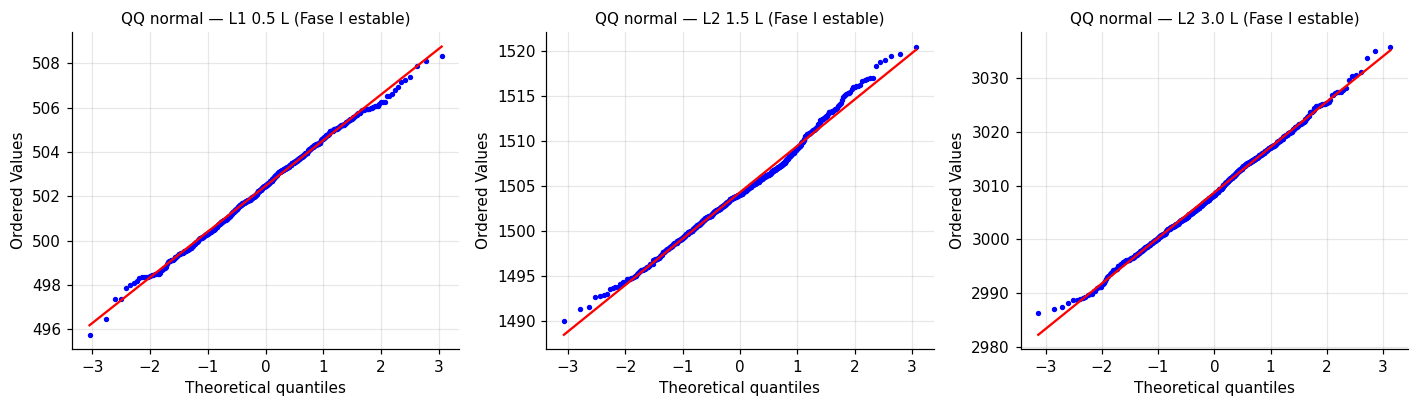

,carta,botellas,p_Shapiro,asimetria,curtosis_exceso
0,L1 0.5 L,600,0.511,-0.066,-0.268
1,L2 1.5 L,650,0.001,0.281,0.196
2,L2 3.0 L,790,0.333,0.090,-0.138


In [ ]:
filas = []
fig, ejes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (linea, formato) in zip(ejes, cartas):
    x = llen[llen["subgrupo"].isin(lims[(linea, formato)]["subgrupos_estables"])]["volumen_mL"]
    filas.append([f"{linea} {formato} L", len(x), stats.shapiro(x).pvalue, stats.skew(x), stats.kurtosis(x)])
    stats.probplot(x, dist="norm", plot=ax)
    ax.get_lines()[0].set_markersize(2.5)
    ax.set_title(f"QQ normal — {linea} {formato} L (Fase I estable)", fontsize=10)
plt.tight_layout()
plt.show()

normalidad = pd.DataFrame(filas, columns=["carta", "botellas", "p_Shapiro", "asimetria", "curtosis_exceso"])
display(normalidad.round(3))

**Lectura de resultados.** En L1 (p = 0,51) y L2 3,0 L (p = 0,33) no se rechaza la normalidad. En L2 1,5 L
sí se rechaza (p = 0,001), pero la desviación es pequeña: asimetría 0,28 y curtosis 0,20, y el QQ es casi
recto con una cola derecha algo más larga. Esa leve asimetría a la derecha es la **mezcla de turnos**: el
turno C llena más alto. Los índices de capacidad son una buena aproximación. Del lado inferior (el que
importa para el límite legal) el riesgo está bien representado, y la cola superior real es algo más pesada
de lo que supone la normal, lo que refuerza el diagnóstico de sobrellenado.

**Límite legal (OIML R87).** La norma de preenvasados no mira la especificación de ingeniería sino la
*cantidad nominal* $Q_n$ y la deficiencia tolerable $T$ (15 mL en 0,5 L; 22,5 mL en 1,5 L; 45 mL en 3,0 L).
Exige tres criterios: (1) la media del lote ≥ $Q_n$; (2) a lo más un 2,5 % de botellas bajo $Q_n - T$
(error T1); (3) ninguna botella bajo $Q_n - 2T$ (error T2). Se verifica con **todas** las mediciones,
por línea × formato y también por turno.

In [ ]:
filas = []
for linea, formato in cartas:
    nominal, T = esp.loc[formato, "nominal_mL"], esp.loc[formato, "tolerancia_oiml_mL"]
    d = llen[(llen["linea"] == linea) & (llen["formato_L"] == formato)]
    for grupo, x in [("Global", d["volumen_mL"])] + [(t, g["volumen_mL"]) for t, g in d.groupby("turno")]:
        t1 = ((x < nominal - T) & (x >= nominal - 2 * T)).sum()
        t2 = (x < nominal - 2 * T).sum()
        cumple = (x.mean() >= nominal) and (100 * t1 / len(x) <= 2.5) and (t2 == 0)
        filas.append([linea, formato, grupo, len(x), x.mean(), x.min(), nominal - T, x.min() - (nominal - T),
                      t1, 100 * t1 / len(x), t2, cumple])

tabla_legal = pd.DataFrame(filas, columns=["linea", "formato", "grupo", "botellas", "media", "minimo", "limite_T1",
                                           "margen_minimo", "error_T1", "%_T1", "error_T2", "cumple_R87"])
display(tabla_legal.round(2))

,linea,formato,grupo,botellas,media,minimo,limite_T1,margen_minimo,error_T1,%_T1,error_T2,cumple_R87
0,L1,0.5,Global,1200,504.09,495.76,485.0,10.76,0,0.0,0,True
1,L1,0.5,A (06-14),600,504.02,495.76,485.0,10.76,0,0.0,0,True
2,L1,0.5,B (14-22),600,504.16,496.48,485.0,11.48,0,0.0,0,True
3,L2,1.5,Global,1440,1504.60,1488.80,1477.5,11.30,0,0.0,0,True
4,L2,1.5,A (06-14),540,1503.17,1491.52,1477.5,14.02,0,0.0,0,True
5,L2,1.5,B (14-22),380,1503.62,1491.30,1477.5,13.80,0,0.0,0,True
6,L2,1.5,C (22-06),520,1506.81,1488.80,1477.5,11.30,0,0.0,0,True
7,L2,3.0,Global,1560,3008.50,2974.20,2955.0,19.20,0,0.0,0,True
8,L2,3.0,A (06-14),460,3007.40,2981.15,2955.0,26.15,0,0.0,0,True
9,L2,3.0,B (14-22),620,3007.67,2980.36,2955.0,25.36,0,0.0,0,True


**Lectura de resultados.** **Las tres combinaciones cumplen OIML R87**, globalmente y en cada turno: la
media supera al nominal, no hay ninguna botella con error T1 ni T2 y la botella más baja queda 10,8 mL
(0,5 L), 11,3 mL (1,5 L) y 19,2 mL (3,0 L) por sobre el límite legal $Q_n - T$. **El riesgo legal no es el
problema de BdM.** El LIE interno (492 mL en 0,5 L) es más exigente que el límite legal (485 mL), y la planta
llena con un margen que excede ambos. La merma que ve Finanzas es **económica**, no legal.

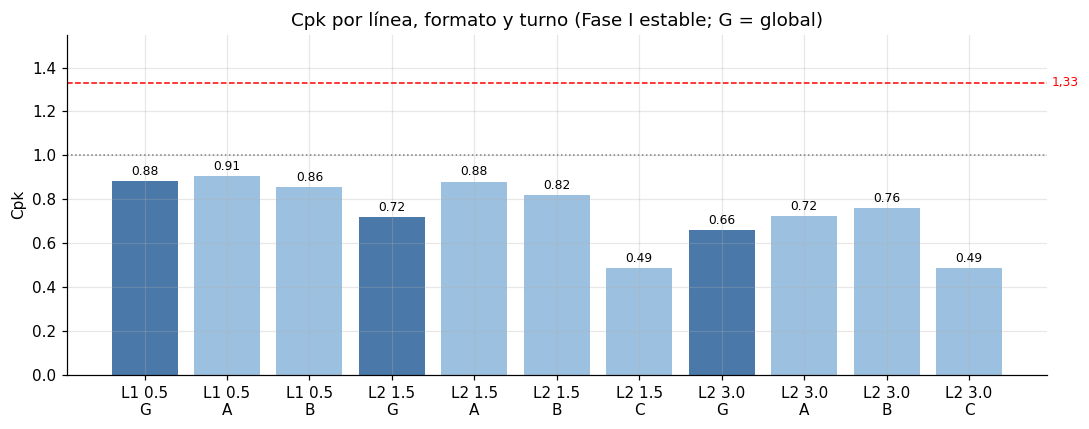

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4))
etiquetas = tabla_cap["linea"] + " " + tabla_cap["formato"].astype(str) + "\n" + tabla_cap["grupo"].str[:1]
colores = np.where(tabla_cap["grupo"] == "Global", "#4a78a8", "#9cc0e0")
barras = ax.bar(etiquetas, tabla_cap["Cpk"], color=colores)
ax.bar_label(barras, fmt="%.2f", fontsize=8, padding=2)
ax.axhline(CONFIG["cpk_objetivo"], color="red", ls="--", lw=1)
ax.text(1.005, CONFIG["cpk_objetivo"], "1,33", transform=ax.get_yaxis_transform(), va="center", fontsize=8, color="red")
ax.axhline(1, color="gray", ls=":", lw=1)
ax.set(ylabel="Cpk", title="Cpk por línea, formato y turno (Fase I estable; G = global)", ylim=(0, 1.55))
plt.tight_layout()
plt.show()

**Respuesta a la pregunta de decisión: ¿se puede estar bajo control y ser incapaz?** **Sí, y BdM tiene los
dos casos.**
- **L2 (1,5 y 3,0 L) está bajo control estadístico**: Fase I estable, Fase II con pocas señales y sin
  cambio de nivel. Aun así es **incapaz**, con Cp = 1,01 y Cpk de 0,66 a 0,72. El control dice que el proceso
  es *predecible*. La capacidad dice que lo predecible **no cabe en la especificación**. La acción ataca la
  **variabilidad**: primero homologar el turno C con A y B (es la mayor fuente de dispersión), luego
  mantención de válvulas de llenado. Para llegar a Cp = 1,33 hay que **reducir σ ≈ 24 %** (tabla de 3.5).
  Es la acción más cara y lenta.
- **L1 era casi capaz (Cp = 1,28) pero descentrado** (Cpk = 0,88), y desde el 24/08 además está **fuera de
  control** por un corrimiento de la media (Ppk = 0,38). La acción ataca la **media**: recentrar el setpoint
  en el nominal. Es barata e inmediata y recupera casi todo el sobrellenado de L1 (sección 3.5).

### 3.4 Carta p (atributos) y Pareto de causas

**¿p o np?** La carta np exige el mismo tamaño de inspección en cada muestra. Aquí $n$ varía entre 181
y 260 botellas, así que corresponde la **carta p** con límites que cambian con cada $n_i$:

$$LC = \bar p,\qquad LCS_i = \bar p + 3\sqrt{\frac{\bar p(1-\bar p)}{n_i}},\qquad
LCI_i = \max\!\left(0,\ \bar p - 3\sqrt{\frac{\bar p(1-\bar p)}{n_i}}\right)$$

Se usa la **misma disciplina de fases** que en la carta X̄–R: $\bar p$ se calcula con las semanas 1 a 5
(sacando los puntos fuera hasta estabilizar), se congela y se juzgan las semanas 6 a 10. Así un episodio
de Fase II no infla los límites que deben detectarlo.

,linea,inspeccionadas,defectuosas,%_defectuosas_total,p_barra_FaseI_%,excluidos_FaseI,fuera_FaseII,semanas_fuera
0,L1,12905,248,1.92,1.86,0,0,[]
1,L2,32974,1027,3.11,2.61,0,12,"[6, 8]"


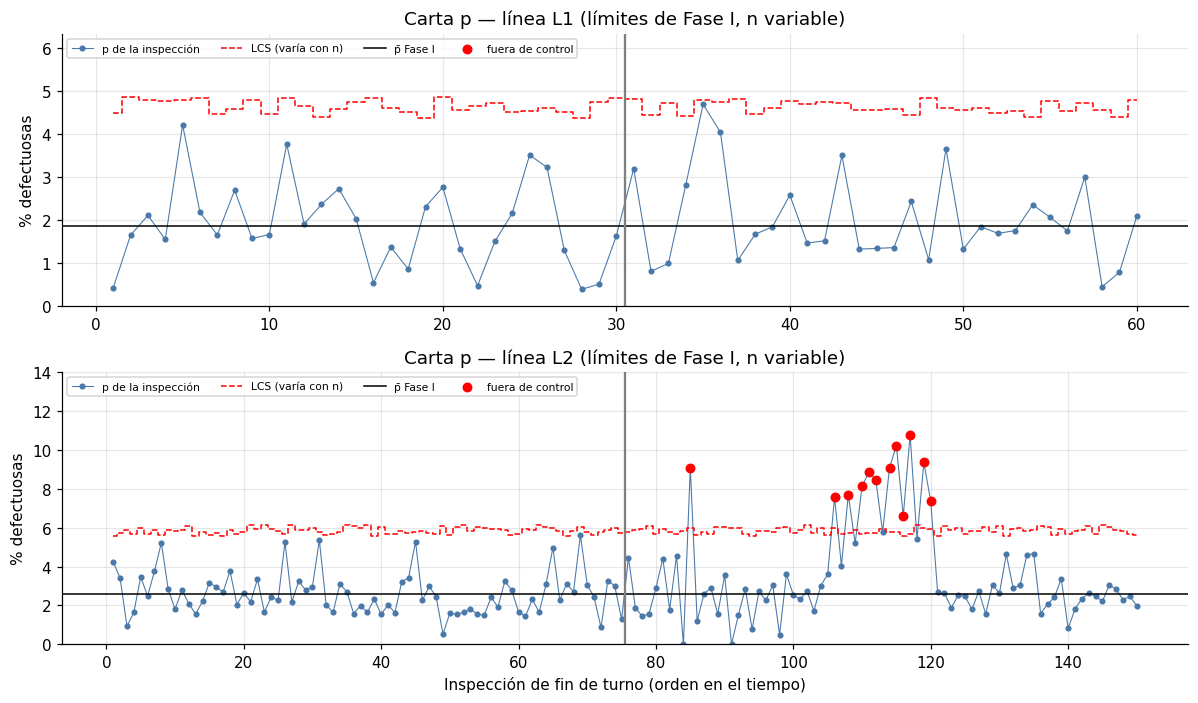

In [ ]:
cartas_p, resumen_p = {}, []
for linea_nom, datos in atr.groupby("linea"):
    datos = datos.sort_values(["fecha", "turno"]).reset_index(drop=True)
    datos["orden"] = datos.index + 1
    datos["p"] = datos["n_defectuosas"] / datos["n_inspeccionadas"]
    datos["fase"] = np.where(datos["semana_registro"] <= FASE1, "I", "II")

    f1 = datos[datos["fase"] == "I"]
    while True:                                                  # Fase I iterativa
        p_bar = f1["n_defectuosas"].sum() / f1["n_inspeccionadas"].sum()
        e = np.sqrt(p_bar * (1 - p_bar) / f1["n_inspeccionadas"])
        fuera = (f1["p"] > p_bar + 3 * e) | (f1["p"] < np.maximum(0, p_bar - 3 * e))
        if fuera.sum() == 0:
            break
        f1 = f1[~fuera]

    e = np.sqrt(p_bar * (1 - p_bar) / datos["n_inspeccionadas"])
    datos["p_bar"] = p_bar
    datos["LCS"], datos["LCI"] = p_bar + 3 * e, np.maximum(0, p_bar - 3 * e)
    datos["fuera"] = (datos["p"] > datos["LCS"]) | (datos["p"] < datos["LCI"])
    cartas_p[linea_nom] = datos
    resumen_p.append([linea_nom, datos["n_inspeccionadas"].sum(), datos["n_defectuosas"].sum(),
                      100 * datos["n_defectuosas"].sum() / datos["n_inspeccionadas"].sum(), 100 * p_bar,
                      (datos["fase"] == "I").sum() - len(f1), datos.loc[datos["fase"] == "II", "fuera"].sum(),
                      sorted(datos.loc[datos["fuera"], "semana_registro"].unique().tolist())])

tabla_p = pd.DataFrame(resumen_p, columns=["linea", "inspeccionadas", "defectuosas", "%_defectuosas_total",
                                           "p_barra_FaseI_%", "excluidos_FaseI", "fuera_FaseII", "semanas_fuera"])
display(tabla_p.round(2))

fig, ejes = plt.subplots(2, 1, figsize=(11, 6.5))
for ax, (linea_nom, datos) in zip(ejes, cartas_p.items()):
    ax.plot(datos["orden"], 100 * datos["p"], "o-", ms=3, lw=0.7, color="#4a78a8", label="p de la inspección")
    ax.step(datos["orden"], 100 * datos["LCS"], where="mid", color="red", ls="--", lw=1, label="LCS (varía con n)")
    ax.axhline(100 * datos["p_bar"].iloc[0], color="black", lw=1, label="p̄ Fase I")
    f = datos[datos["fuera"]]
    ax.scatter(f["orden"], 100 * f["p"], color="red", s=30, zorder=5, label="fuera de control")
    ax.axvline(datos.loc[datos["fase"] == "I", "orden"].max() + 0.5, color="gray")
    ax.set(ylabel="% defectuosas", title=f"Carta p — línea {linea_nom} (límites de Fase I, n variable)")
    ax.set_ylim(0, 100 * max(datos["p"].max(), datos["LCS"].max()) * 1.3)     # espacio para la leyenda
    ax.legend(fontsize=7, loc="upper left", ncol=4)
ejes[-1].set_xlabel("Inspección de fin de turno (orden en el tiempo)")
plt.tight_layout()
plt.show()

**Lectura de resultados.** **L1:** $\bar p$ = 1,86 % en Fase I y ningún punto fuera en las 10 semanas; la
merma por atributos de L1 es estable. **L2:** $\bar p$ = 2,61 % en Fase I (estable, sin exclusiones) y **12
inspecciones fuera de control en la Fase II**. Por eso su tasa total (3,11 %) es mayor que la estable. El
gráfico muestra que no están dispersas: forman un **episodio** concentrado en la semana 8.

In [ ]:
# Causa y turno de los puntos fuera de control
fuera_p = pd.concat([d[d["fuera"]].assign(linea=l) for l, d in cartas_p.items()])
display(fuera_p[["linea", "fecha", "semana_registro", "turno", "sku", "n_inspeccionadas", "n_defectuosas", "p", "causa_principal"]].round(3))

,linea,fecha,semana_registro,turno,sku,n_inspeccionadas,n_defectuosas,p,causa_principal
84,L2,2026-08-27,6,A (06-14),FUN-B30,198,18,0.091,Nivel de llenado
105,L2,2026-09-07,8,A (06-14),CIT-L30,198,15,0.076,Etiqueta
107,L2,2026-09-07,8,C (22-06),NEC-D30,234,18,0.077,Etiqueta
109,L2,2026-09-08,8,B (14-22),FUN-B15,246,20,0.081,Etiqueta
110,L2,2026-09-08,8,C (22-06),FUN-B15,237,21,0.089,Etiqueta
111,L2,2026-09-09,8,A (06-14),CIT-L30,236,20,0.085,Sello/tapa
113,L2,2026-09-09,8,C (22-06),CIT-L30,231,21,0.091,Etiqueta
114,L2,2026-09-10,8,A (06-14),NEC-D30,225,23,0.102,Nivel de llenado
115,L2,2026-09-10,8,B (14-22),CIT-L30,258,17,0.066,Etiqueta
116,L2,2026-09-10,8,C (22-06),NEC-D30,241,26,0.108,Sello/tapa


**Lectura de resultados.** 11 de los 12 puntos fuera son del **07 al 11/09/2026 (semana 8)**, en **los tres
turnos** y en SKU de las tres familias, con la causa **Etiqueta** como principal. Una causa que afecta a
todos los turnos y productos a la vez apunta a un **insumo o equipo común**: un lote defectuoso de
etiquetas o un desajuste de la etiquetadora de L2. El punto restante (27/08, FUN-B30, «Nivel de llenado»)
es un evento aislado.

**Pareto.** Se excluye la categoría «Sin defectos». Se separa el **episodio** (las inspecciones fuera de
control de la carta p) del resto. Mezclarlos haría que una causa especial y pasajera parezca el problema
crónico de la planta.

Pareto TOTAL


,defectuosas,%,%_acumulado
causa_principal,,,
Etiqueta,440,34.5,34.5
Sello/tapa,344,27.0,61.5
Nivel de llenado,324,25.4,86.9
Envase deformado,92,7.2,94.1
Cuerpo extranio,75,5.9,100.0


Pareto SIN el episodio (problema crónico)


,defectuosas,%,%_acumulado
causa_principal,,,
Sello/tapa,298,28.6,28.6
Etiqueta,294,28.2,56.8
Nivel de llenado,283,27.2,84.0
Envase deformado,92,8.8,92.8
Cuerpo extranio,75,7.2,100.0


Pareto del EPISODIO (inspecciones fuera de control)


,defectuosas,%,%_acumulado
causa_principal,,,
Etiqueta,146,62.7,62.7
Sello/tapa,46,19.7,82.4
Nivel de llenado,41,17.6,100.0


Pareto crónico por línea


linea,L1,L2
causa_principal,,
Cuerpo extranio,11,64
Envase deformado,26,66
Etiqueta,60,234
Nivel de llenado,92,191
Sello/tapa,59,239


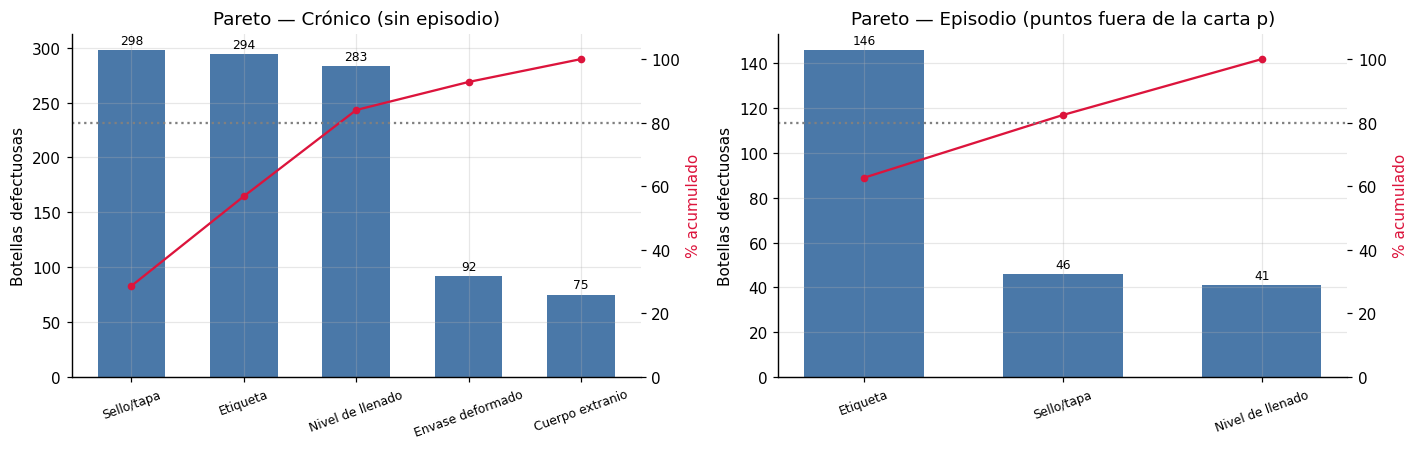

In [ ]:
base = atr[atr["causa_principal"] != "Sin defectos"].copy()
clave_ep = set(zip(fuera_p["fecha"], fuera_p["turno"], fuera_p["linea"]))
base["episodio"] = [(f, t, l) in clave_ep for f, t, l in zip(base["fecha"], base["turno"], base["linea"])]

def pareto(d):
    p = d.groupby("causa_principal")["n_defectuosas"].sum().sort_values(ascending=False).to_frame("defectuosas")
    p["%"] = 100 * p["defectuosas"] / p["defectuosas"].sum()
    p["%_acumulado"] = p["%"].cumsum()
    return p

par_total, par_cronico, par_episodio = pareto(base), pareto(base[~base["episodio"]]), pareto(base[base["episodio"]])
print("Pareto TOTAL"); display(par_total.round(1))
print("Pareto SIN el episodio (problema crónico)"); display(par_cronico.round(1))
print("Pareto del EPISODIO (inspecciones fuera de control)"); display(par_episodio.round(1))
print("Pareto crónico por línea")
display(base[~base["episodio"]].pivot_table(index="causa_principal", columns="linea", values="n_defectuosas", aggfunc="sum").round(0))

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, (titulo, p) in zip(ejes, [("Crónico (sin episodio)", par_cronico), ("Episodio (puntos fuera de la carta p)", par_episodio)]):
    b = ax.bar(p.index, p["defectuosas"], color="#4a78a8", width=0.6)
    ax.bar_label(b, fmt="%d", fontsize=8, padding=2)
    ax.tick_params(axis="x", rotation=20, labelsize=8)
    ax.set(title=f"Pareto — {titulo}", ylabel="Botellas defectuosas")
    a2 = ax.twinx()
    a2.plot(p.index, p["%_acumulado"], "o-", color="crimson", ms=4)
    a2.axhline(80, color="gray", ls=":")
    a2.set_ylim(0, 108)
    a2.set_ylabel("% acumulado", color="crimson")
    a2.grid(False)
    a2.spines["top"].set_visible(False)
plt.tight_layout()
plt.show()

 El Pareto total muestra a Etiqueta como causa dominante (34,5 %). Pero
sin el episodio el Pareto crónico es casi plano: Sello/tapa 28,6 %, Etiqueta 28,2 % y Nivel de
llenado 27,2 % suman el 84 %. Dos conclusiones:
1. El problema de etiquetas es en buena parte un episodio (63 % de los defectos de la semana 8). Se
   corrige con control de insumos, no con un proyecto de mejora permanente.
2. El problema **crónico** no tiene una causa dominante: reducir la merma exige atacar tres causas. Una de
   ellas, *Nivel de llenado* (27 %), conecta la merma por atributos con la variabilidad del llenado de la
   sección 3.3.

### 3.5 Cuantificación económica del sobrellenado

**Lógica.** Litros regalados al año = botellas producidas al año × (media − nominal) / 1000. Se valorizan
al **costo variable por litro** de cada SKU (costo variable por caja / litros por caja).

- **Volumen anual:** ventas del último año (semanas 105 a 156) de la serie limpia (sin faltantes ni
  atípicos). Se usan ventas como aproximación de la producción. La producción real es algo mayor por la
  merma $\rho$, así que la cifra es conservadora.
- **Sobrellenado:** se reportan dos escenarios. **Vigente (Fase II, semanas 6 a 10)** describe el proceso
  *tal como está hoy* y es el que se traspasa a la Entrega 2. **Promedio de las 10 semanas** se da como
  referencia. En L1 la diferencia entre ambos es justamente el corrimiento de la media detectado en 3.2.

In [ ]:
cajas_anio = limpia.loc[105:156].sum()            # cajas del último año por SKU (serie limpia)
escenarios = [("Vigente (Fase II)", llen[llen["semana_registro"] > FASE1]), ("Promedio 10 semanas", llen)]

filas = []
for nombre, d in escenarios:
    for sku in skus:
        formato = mst.loc[sku, "formato_L"]
        sobre = d.loc[d["sku"] == sku, "volumen_mL"].mean() - esp.loc[formato, "nominal_mL"]   # mL por botella
        botellas = cajas_anio[sku] * mst.loc[sku, "botellas_por_caja"]
        costo_L = mst.loc[sku, "costo_variable_caja_clp"] / mst.loc[sku, "litros_por_caja"]
        filas.append([nombre, mst.loc[sku, "linea_envasado"], formato, sku, sobre, botellas,
                      botellas * sobre / 1000, costo_L, botellas * sobre / 1000 * costo_L])

tabla_eco = pd.DataFrame(filas, columns=["escenario", "linea", "formato", "sku", "sobrellenado_mL", "botellas_anio",
                                         "litros_anio", "costo_var_CLP_L", "valor_CLP_anio"])
display(tabla_eco[tabla_eco["escenario"] == "Vigente (Fase II)"].round(2))

tot = tabla_eco.groupby(["escenario", "linea", "formato"])[["litros_anio", "valor_CLP_anio"]].sum()
tot["valor_MM_CLP"] = tot["valor_CLP_anio"] / 1e6
display(tot.round(1))
tot_planta = tabla_eco.groupby("escenario")[["litros_anio", "valor_CLP_anio"]].sum()
tot_planta["valor_MM_CLP"] = tot_planta["valor_CLP_anio"] / 1e6
display(tot_planta.round(1))

,escenario,linea,formato,sku,sobrellenado_mL,botellas_anio,litros_anio,costo_var_CLP_L,valor_CLP_anio
0,Vigente (Fase II),L1,0.5,CIT-L05,5.85,1227888.0,7188.49,470.0,3378588.47
1,Vigente (Fase II),L2,1.5,CIT-L15,4.00,689730.0,2756.27,470.0,1295445.58
2,Vigente (Fase II),L2,3.0,CIT-L30,7.77,90052.0,700.01,470.0,329004.05
3,Vigente (Fase II),L1,0.5,FUN-B05,5.52,1547952.0,8537.73,810.0,6915560.70
4,Vigente (Fase II),L2,1.5,FUN-B15,5.20,544374.0,2833.40,810.0,2295057.12
5,Vigente (Fase II),L2,3.0,FUN-B30,7.50,30320.0,227.46,810.0,184246.19
6,Vigente (Fase II),L1,0.5,NEC-D05,5.74,950796.0,5461.17,640.0,3495151.45
7,Vigente (Fase II),L2,1.5,NEC-D15,4.74,839976.0,3983.97,640.0,2549741.55
8,Vigente (Fase II),L2,3.0,NEC-D30,8.53,129436.0,1104.43,640.0,706834.46


litros_anio  valor_CLP_anio  valor_MM_CLP
escenario           linea formato                                           
Promedio 10 semanas L1    0.5          15198.9       9986388.8          10.0
                    L2    1.5           9351.6       6052815.5           6.1
                          3.0           2119.2       1283537.0           1.3
Vigente (Fase II)   L1    0.5          21187.4      13789300.6          13.8
                    L2    1.5           9573.6       6140244.3           6.1
                          3.0           2031.9       1220084.7           1.2

,litros_anio,valor_CLP_anio,valor_MM_CLP
escenario,,,
Promedio 10 semanas,26669.7,17322741.3,17.3
Vigente (Fase II),32792.9,21149629.6,21.1


**Lectura de resultados.** En la situación **vigente** BdM regala **≈ 32.800 litros de jarabe al año,
equivalentes a ≈ 21,1 MM CLP a costo variable**. El promedio de las 10 semanas da 26.700 L y 17,3 MM CLP;
la diferencia es exactamente el corrimiento de L1 desde el 24/08. **L1 explica el 65 %** (21.200 L;
13,8 MM CLP), porque envasa muchas más botellas pequeñas con un sobrellenado de ≈ 5,7 mL cada una. Por SKU
el mayor costo es FUN-B05 (6,9 MM CLP): es el de mayor volumen de botellas y el de mayor costo por litro.

**Por turno.** Se reparte el volumen anual de cada línea × formato entre turnos en proporción a sus
subgrupos muestreados. El supuesto es que se muestrea cada 2 horas en todos los turnos, así que los
subgrupos son proporcionales a las horas producidas. Escenario vigente (Fase II).

In [ ]:
filas = []
d_vig = llen[llen["semana_registro"] > FASE1]
for linea, formato in cartas:
    nominal = esp.loc[formato, "nominal_mL"]
    d = d_vig[(d_vig["linea"] == linea) & (d_vig["formato_L"] == formato)]
    skus_fl = mst[(mst["linea_envasado"] == linea) & (mst["formato_L"] == formato)].index
    botellas = (cajas_anio[skus_fl] * mst.loc[skus_fl, "botellas_por_caja"]).sum()
    litros_sku = cajas_anio[skus_fl] * mst.loc[skus_fl, "litros_por_caja"]
    costo_L = (litros_sku * mst.loc[skus_fl, "costo_variable_caja_clp"] / mst.loc[skus_fl, "litros_por_caja"]).sum() / litros_sku.sum()
    n_sub = d.groupby("turno")["subgrupo"].nunique()
    for turno in n_sub.index:
        sobre = d.loc[d["turno"] == turno, "volumen_mL"].mean() - nominal
        bt = botellas * n_sub[turno] / n_sub.sum()
        filas.append([linea, formato, turno, sobre, bt, bt * sobre / 1000, bt * sobre / 1000 * costo_L])

tabla_turno = pd.DataFrame(filas, columns=["linea", "formato", "turno", "sobrellenado_mL", "botellas_anio", "litros_anio", "valor_CLP_anio"])
tabla_turno["valor_MM_CLP"] = tabla_turno["valor_CLP_anio"] / 1e6
display(tabla_turno.round(2))

,linea,formato,turno,sobrellenado_mL,botellas_anio,litros_anio,valor_CLP_anio,valor_MM_CLP
0,L1,0.5,A (06-14),5.67,1863318.00,10563.65,6914968.74,6.91
1,L1,0.5,B (14-22),5.77,1863318.00,10751.84,7038161.36,7.04
2,L2,1.5,A (06-14),3.00,600391.58,1802.46,1132098.31,1.13
3,L2,1.5,B (14-22),3.76,709553.68,2668.19,1675855.86,1.68
4,L2,1.5,C (22-06),6.76,764134.74,5164.49,3243741.83,3.24
5,L2,3.0,A (06-14),7.29,94521.95,689.09,413007.99,0.41
6,L2,3.0,B (14-22),7.40,81018.81,599.41,359259.57,0.36
7,L2,3.0,C (22-06),9.80,74267.24,728.04,436350.56,0.44


**Lectura de resultados.** En L1 ambos turnos regalan lo mismo (≈ 7 MM CLP cada uno): el problema es de la
máquina. En L2 1,5 L el **turno C regala 3,2 MM CLP al año, contra 1,1 y 1,7 MM CLP de A y B**, porque
llena +6,8 mL contra +3,0 y +3,8. Este es el número que pide el enunciado para la recomendación ejecutiva:
*el turno de noche regala ≈ 3,7 MM CLP al año en sobrellenado* (1,5 L + 3,0 L).

**¿Cuánto se puede recuperar y con qué acción?** El sobrellenado no es todo desperdicio: parte es un
*seguro* contra la variabilidad. Para cumplir la especificación con Cpk ≥ 1,33 por el lado inferior, la
media mínima es $\mu^* = \max\big(Q_n,\ LIE + 3\cdot 1{,}33\cdot\hat\sigma\big)$. Lo que está por sobre
$\mu^*$ se recupera **ajustando la media** (acción barata: reprogramar la llenadora). Lo que queda entre
$Q_n$ y $\mu^*$ solo se recupera **reduciendo $\sigma$** (acción cara: mantención de válvulas,
estandarizar el turno).

In [ ]:
filas = []
for linea, formato in cartas:
    nominal, LIE = esp.loc[formato, "nominal_mL"], esp.loc[formato, "LIE_mL"]
    sigma_c = lims[(linea, formato)]["sigma"]
    mu_hoy = d_vig[(d_vig["linea"] == linea) & (d_vig["formato_L"] == formato)]["volumen_mL"].mean()
    mu_est = max(nominal, LIE + 3 * CONFIG["cpk_objetivo"] * sigma_c)
    eco = tabla_eco[(tabla_eco["escenario"] == "Vigente (Fase II)") & (tabla_eco["linea"] == linea) & (tabla_eco["formato"] == formato)]
    valor_por_mL = eco["valor_CLP_anio"].sum() / (mu_hoy - nominal)                 # CLP/año por cada mL de sobrellenado
    por_media = max(0, mu_hoy - mu_est)                      # mL que sobran por sobre la media mínima
    por_sigma = min(mu_hoy, mu_est) - nominal                # mL que solo se recuperan bajando sigma
    sigma_meta = (esp.loc[formato, "LSE_mL"] - LIE) / (6 * CONFIG["cpk_objetivo"])   # sigma que daría Cp = 1,33
    filas.append([linea, formato, mu_hoy, sigma_c, mu_est, por_media, por_media * valor_por_mL / 1e6,
                  por_sigma * valor_por_mL / 1e6, sigma_meta, 100 * (1 - sigma_meta / sigma_c)])

recuperable = pd.DataFrame(filas, columns=["linea", "formato", "media_hoy", "sigma_corto", "media_minima_mu*",
                                           "mL_recuperables_media", "MM_CLP_ajustando_media", "MM_CLP_que_exige_bajar_sigma",
                                           "sigma_para_Cp_1.33", "reduccion_sigma_%"])
display(recuperable.round(2))

,linea,formato,media_hoy,sigma_corto,media_minima_mu*,mL_recuperables_media,MM_CLP_ajustando_media,MM_CLP_que_exige_bajar_sigma,sigma_para_Cp_1.33,reduccion_sigma_%
0,L1,0.5,505.72,2.09,500.34,5.38,12.96,0.83,2.01,4.11
1,L2,1.5,1504.65,4.97,1504.83,0.00,0.00,6.14,3.76,24.35
2,L2,3.0,3008.07,8.24,3007.87,0.21,0.03,1.19,6.27,23.93


**Lectura de resultados.** **En L1, ≈ 5,4 de los 5,7 mL de sobrellenado son recuperables ajustando solo la
media**: con σ = 2,09 mL basta una media de 500,3 mL para mantener Cpk ≥ 1,33 contra el LIE. Esa acción
vale **≈ 13,0 MM CLP al año** y cuesta casi nada. **En L2 el sobrellenado es un seguro contra la
variabilidad**: con σ = 4,97 mL (1,5 L) y 8,24 mL (3,0 L) la media mínima segura ya está sobre la actual, así
que bajar la media sin reducir σ aumentaría las botellas bajo el LIE. Recuperar los ≈ 7,6 MM CLP de L2
exige **reducir σ ≈ 24 %**. Ésta es la respuesta cuantitativa a «las acciones que atacan la media y las que
atacan la variabilidad no son las mismas ni cuestan lo mismo».



## 4. Parte B — Pronóstico de demanda

### 4.1 Diagnóstico documentado de las 9 series

El enunciado pide revisar siete aspectos: tendencia, estacionalidad, atípicos, faltantes, quiebres
estructurales, intermitencia y promociones. Los **faltantes** y **atípicos** ya se trataron en la sección
2.3 porque son errores de registro. Aquí se diagnostica el resto sobre la serie `limpia`. Todo lo de esta
sección es **diagnóstico** (mirar los datos), no ajuste de modelos. Lo que se use dentro de un modelo se
vuelve a calcular dentro de cada pliegue (sección 4.4).

**Tendencia.** Nivel medio de cada año del historial (3 bloques de 52 semanas) y su variación.

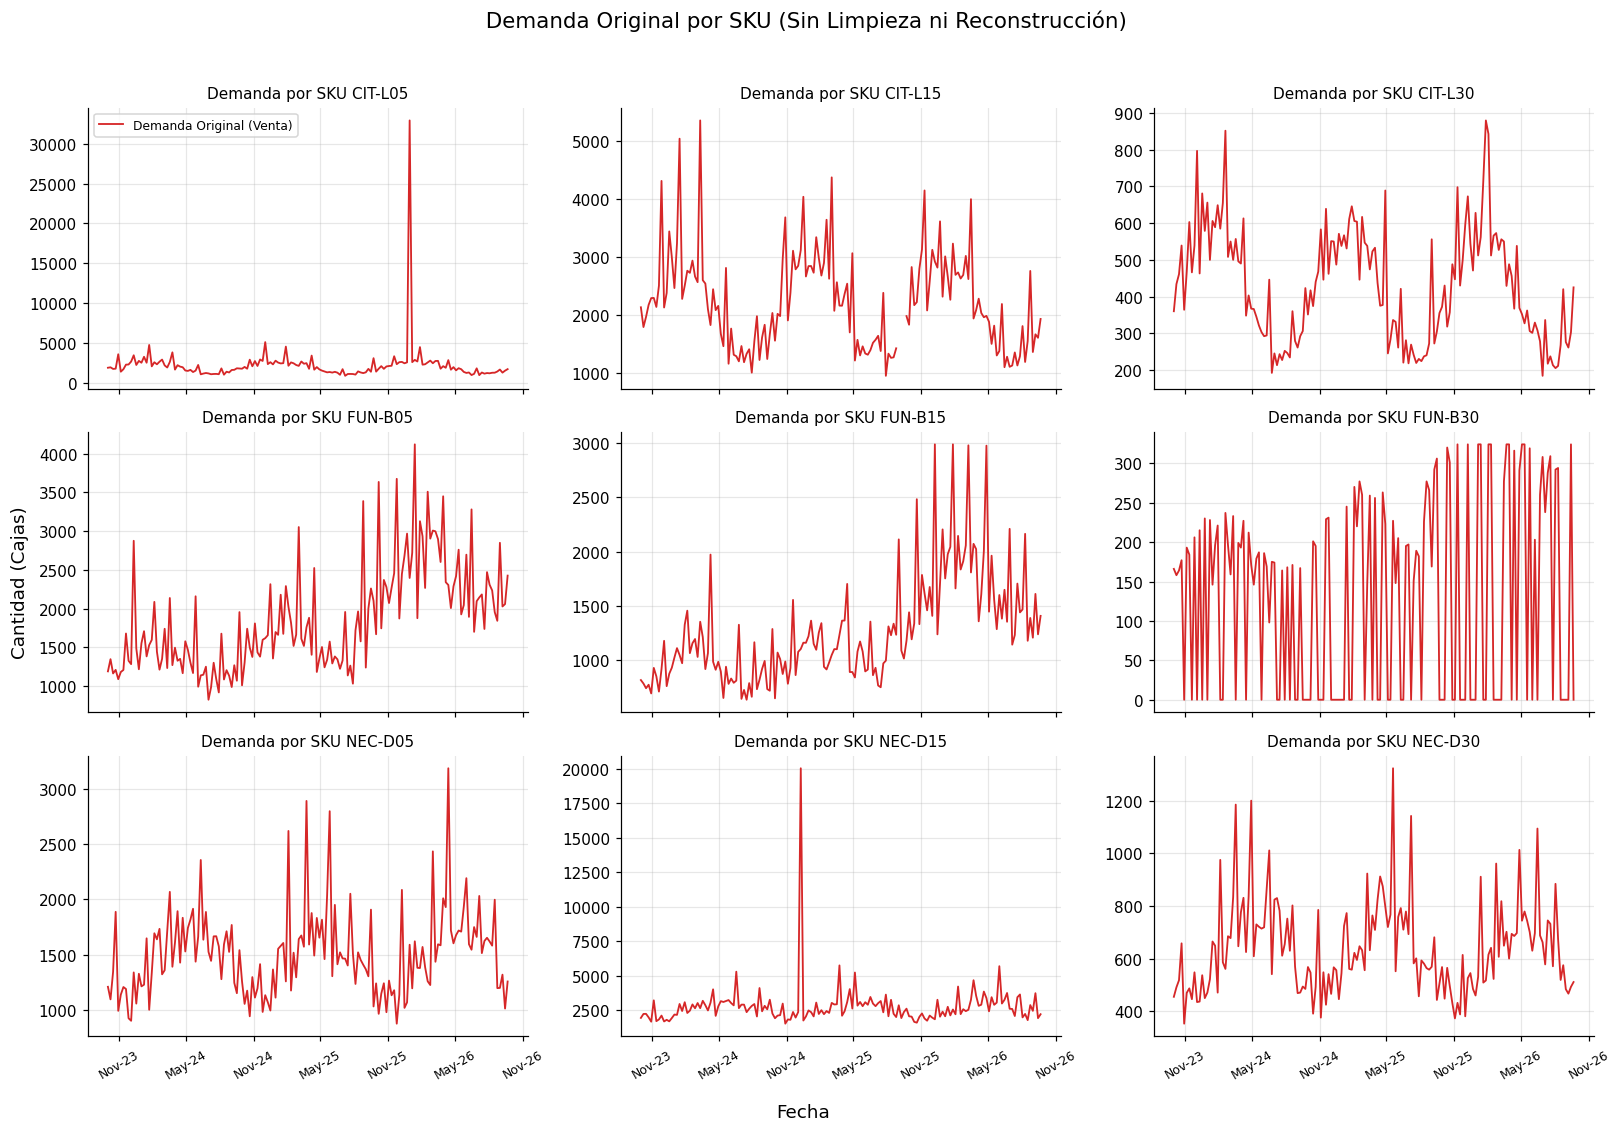

In [ ]:
fig, ejes = plt.subplots(3, 3, figsize=(15, 10), sharex=True)
for ax, sku in zip(ejes.flatten(), skus):
    # Graficamos la serie original sin limpiar ni reconstruir (ventas original)
    ax.plot(fechas, ventas[sku], color="tab:red", lw=1.2, label="Demanda Original (Venta)")
    ax.set_title(f"Demanda por SKU {sku}", fontsize=10)
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
    ax.tick_params(axis="x", rotation=30, labelsize=8)
    ax.grid(True, alpha=0.3)
ejes[0, 0].legend(fontsize=8)
fig.supxlabel("Fecha")
fig.supylabel("Cantidad (Cajas)")
plt.suptitle(" Demanda Original por SKU (Sin Limpieza ni Reconstrucción)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

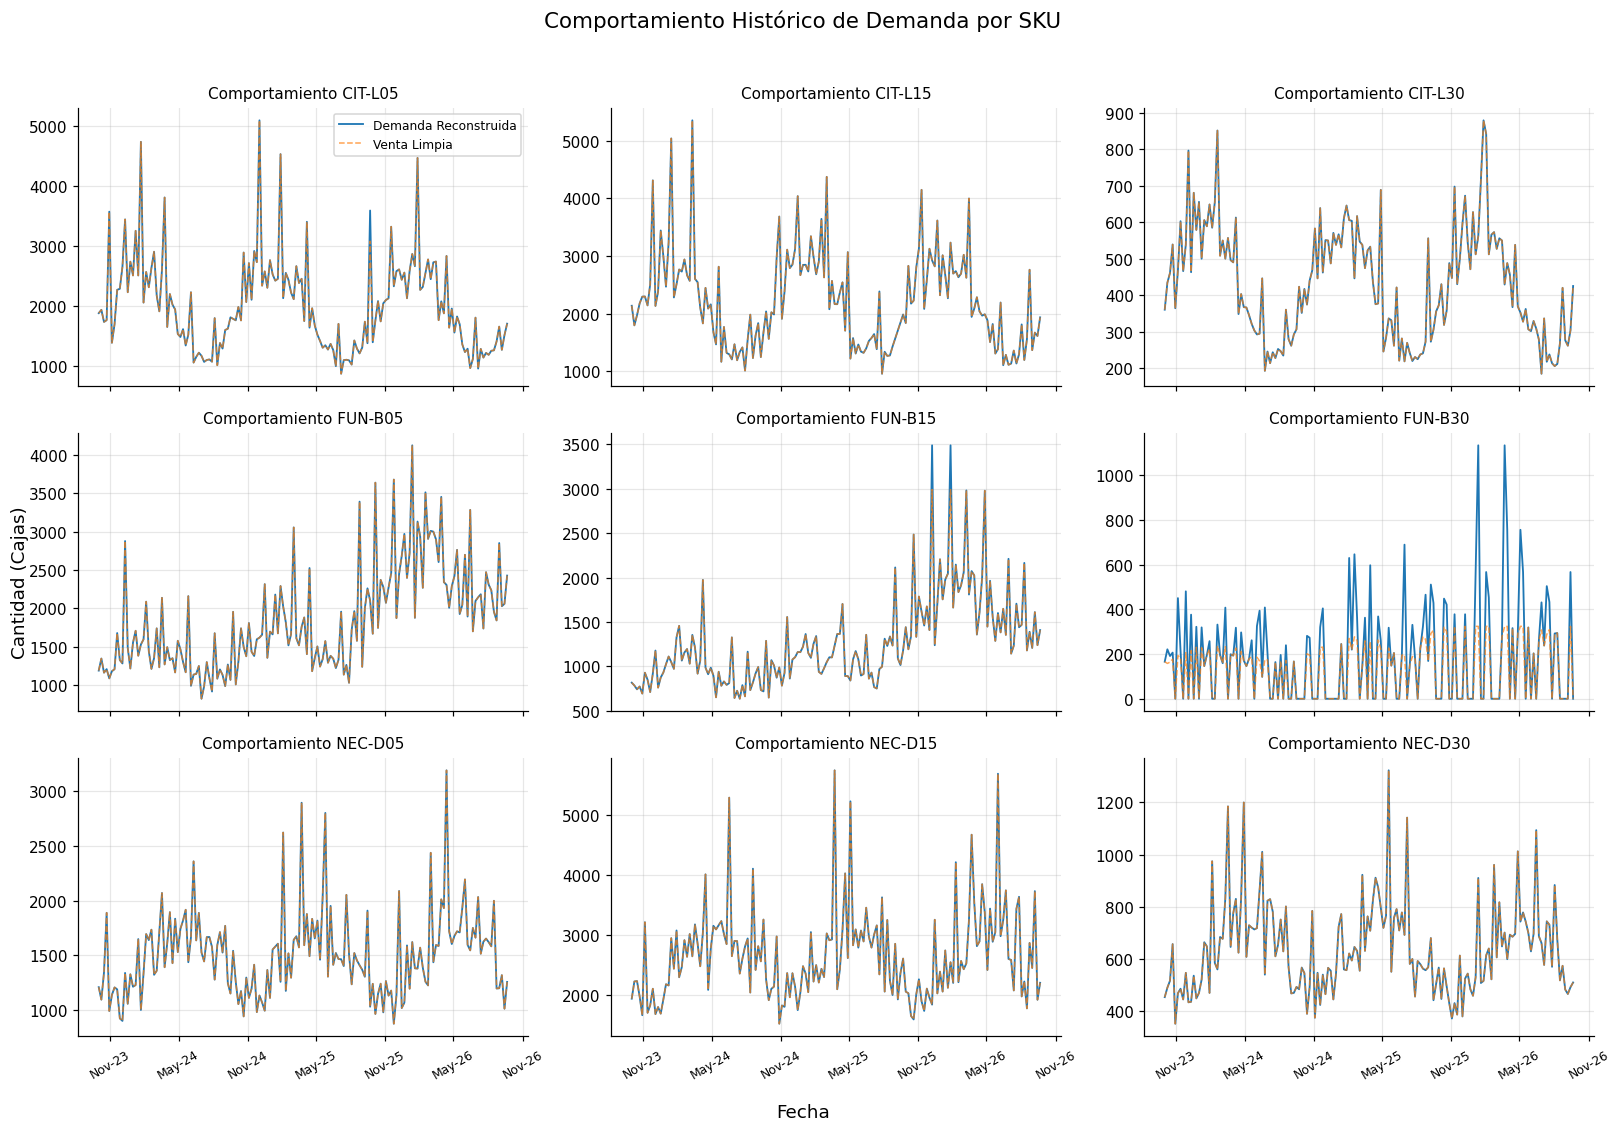

In [ ]:
fig, ejes = plt.subplots(3, 3, figsize=(15, 10), sharex=True)
for ax, sku in zip(ejes.flatten(), skus):
    ax.plot(fechas, demanda[sku], color="tab:blue", lw=1.2, label="Demanda Reconstruida")
    ax.plot(fechas, limpia[sku], color="tab:orange", ls="--", lw=1, alpha=0.7, label="Venta Limpia")
    ax.set_title(f"Comportamiento {sku}", fontsize=10)
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
    ax.tick_params(axis="x", rotation=30, labelsize=8)
    ax.grid(True, alpha=0.3)
ejes[0, 0].legend(fontsize=8)
fig.supxlabel("Fecha")
fig.supylabel("Cantidad (Cajas)")
plt.suptitle("Comportamiento Histórico de Demanda por SKU", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

In [ ]:
H, S = CONFIG["H"], CONFIG["S"]
bloque = pd.Series(np.repeat([1, 2, 3], 52), index=limpia.index)
nivel_anual = limpia.groupby(bloque).mean().T
nivel_anual.columns = ["año 1", "año 2", "año 3"]
nivel_anual["cambio año1→2 %"] = 100 * (nivel_anual["año 2"] / nivel_anual["año 1"] - 1)
nivel_anual["cambio año2→3 %"] = 100 * (nivel_anual["año 3"] / nivel_anual["año 2"] - 1)
display(nivel_anual.round(1))

,año 1,año 2,año 3,cambio año1→2 %,cambio año2→3 %
sku,,,,,
CIT-L05,2004.4,2038.6,1967.8,1.7,-3.5
CIT-L15,2216.5,2236.0,2210.7,0.9,-1.1
CIT-L30,438.8,423.3,432.9,-3.5,2.3
FUN-B05,1377.7,1670.5,2480.7,21.3,48.5
FUN-B15,955.2,1102.8,1744.8,15.5,58.2
FUN-B30,121.1,121.3,145.8,0.2,20.2
NEC-D05,1488.6,1507.0,1523.7,1.2,1.1
NEC-D15,2650.3,2656.9,2692.2,0.2,1.3
NEC-D30,649.3,648.6,622.3,-0.1,-4.1


Solo la familia FUN crece: FUN-B05 +48,5 %, FUN-B15 +58,2 % y FUN-B30
+20,2 % entre el año 2 y el 3, después de crecer ya entre 15 y 21 % el año anterior. CIT y NEC son
estables (±4 %). Un modelo sin tendencia o sin nivel adaptativo subestimará FUN.

**Estacionalidad.** Índice mensual = venta / promedio móvil centrado de 52 semanas. El promedio de un año
completo saca la estación y deja solo la tendencia. Se usan solo las semanas **sin promoción** para no
confundir el efecto de la promoción con la estación. 1,00 = mes normal; 1,26 = 26 % sobre lo normal.

In [ ]:
sin_promo = limpia.where(promo == 0)
tendencia_ciclo = limpia.rolling(52, center=True, min_periods=40).mean()
indice_mes = (sin_promo / tendencia_ciclo).groupby(mes).mean()
display(indice_mes.round(2).T)

fuerza = pd.DataFrame({"mes_pico": indice_mes.idxmax(), "indice_pico": indice_mes.max(),
                       "mes_valle": indice_mes.idxmin(), "indice_valle": indice_mes.min()})
fuerza["amplitud (pico/valle)"] = fuerza["indice_pico"] / fuerza["indice_valle"]
display(fuerza.round(2))

fecha_lunes,1,2,3,4,5,6,7,8,9,10,11,12
sku,,,,,,,,,,,,
CIT-L05,1.26,1.22,1.14,0.91,0.75,0.59,0.53,0.61,0.79,0.96,1.20,1.24
CIT-L15,1.25,1.25,1.08,0.96,0.67,0.62,0.58,0.62,0.78,1.09,1.16,1.28
CIT-L30,1.39,1.29,1.20,0.92,0.75,0.63,0.56,0.57,0.76,0.96,1.14,1.31
FUN-B05,1.15,1.10,1.08,0.91,0.88,0.77,0.67,0.83,0.81,0.97,1.02,1.05
FUN-B15,1.15,1.06,1.13,0.97,0.87,0.80,0.68,0.88,0.79,0.93,0.95,1.06
FUN-B30,0.89,1.34,1.24,1.24,1.07,0.92,0.89,1.01,0.76,1.22,1.01,0.25
NEC-D05,0.91,0.95,1.08,1.12,1.15,1.08,1.03,0.98,0.85,0.73,0.73,0.77
NEC-D15,0.89,0.91,1.08,1.10,1.12,1.13,1.04,0.91,0.92,0.70,0.74,0.78
NEC-D30,0.88,0.95,1.07,1.21,1.09,1.10,1.02,0.94,0.79,0.75,0.68,0.78


,mes_pico,indice_pico,mes_valle,indice_valle,amplitud (pico/valle)
sku,,,,,
CIT-L05,1,1.26,7,0.53,2.36
CIT-L15,12,1.28,7,0.58,2.21
CIT-L30,1,1.39,7,0.56,2.49
FUN-B05,1,1.15,7,0.67,1.72
FUN-B15,1,1.15,7,0.68,1.70
FUN-B30,2,1.34,12,0.25,5.40
NEC-D05,5,1.15,10,0.73,1.58
NEC-D15,6,1.13,10,0.70,1.62
NEC-D30,4,1.21,11,0.68,1.76


**Lectura de resultados.** **CIT** tiene la estacionalidad más fuerte: peak en diciembre y enero (índice
≈ 1,26 a 1,39), valle en julio (≈ 0,55) y amplitud de 2,2 a 2,5 veces. **FUN** tiene la misma fase (peak en
enero, valle en julio) con amplitud de 1,7. **NEC** va en contrafase: peak de abril a junio, valle de
octubre a noviembre y amplitud de 1,6 a 1,8. En FUN-B30 el índice es errático (amplitud 5,4) por su
intermitencia, no por una estación real. Las familias de verano son CIT y FUN; la del calendario escolar
es NEC.

**Quiebres estructurales.** Se quita la estacionalidad y se busca el corte que mejor separa la serie en
dos niveles constantes, minimizando la suma de errores cuadrados. Se exigen al menos 26 semanas a cada
lado. Hay quiebre si el nivel cambia más de 20 % **y** el corte explica más de 25 % de la variación.

In [ ]:
desest = limpia / indice_mes.loc[mes].values
filas = []
for sku in skus:
    y = desest[sku].values
    mejor_sse, mejor_t = np.inf, None
    for t in range(26, len(y) - 26):
        sse = ((y[:t] - y[:t].mean()) ** 2).sum() + ((y[t:] - y[t:].mean()) ** 2).sum()
        if sse < mejor_sse:
            mejor_sse, mejor_t = sse, t
    antes, despues = y[:mejor_t].mean(), y[mejor_t:].mean()
    filas.append([sku, mejor_t + 1, fechas.iloc[mejor_t].date(), antes, despues, 100 * (despues / antes - 1),
                  100 * (1 - mejor_sse / ((y - y.mean()) ** 2).sum())])

quiebre = pd.DataFrame(filas, columns=["sku", "semana_corte", "fecha", "nivel_antes", "nivel_despues", "cambio_%",
                                       "variacion_explicada_%"])
quiebre["hay_quiebre"] = (quiebre["cambio_%"].abs() > 20) & (quiebre["variacion_explicada_%"] > 25)
for _, f in quiebre[quiebre["hay_quiebre"]].iterrows():
    anotar(f["sku"], int(f["semana_corte"]), f"Quiebre estructural (nivel {f['cambio_%']:+.0f} %)",
           "Corte de dos niveles en la serie desestacionalizada", "Se conserva; los modelos con nivel adaptativo lo siguen")
display(quiebre.round(1))

,sku,semana_corte,fecha,nivel_antes,nivel_despues,cambio_%,variacion_explicada_%,hay_quiebre
0,CIT-L05,71,2025-02-03,2193.7,2105.1,-4.0,0.8,False
1,CIT-L15,56,2024-10-21,2322.5,2373.7,2.2,0.2,False
2,CIT-L30,39,2024-06-24,466.8,445.8,-4.5,1.2,False
3,FUN-B05,98,2025-08-11,1580.0,2652.9,67.9,56.5,True
4,FUN-B15,96,2025-07-28,1063.2,1814.3,70.6,55.8,True
5,FUN-B30,94,2025-07-14,119.4,169.0,41.5,1.9,False
6,NEC-D05,115,2025-12-08,1575.2,1622.3,3.0,0.5,False
7,NEC-D15,116,2025-12-15,2783.8,2896.1,4.0,0.6,False
8,NEC-D30,94,2025-07-14,696.6,654.1,-6.1,2.5,False


**Lectura de resultados.** Hay **quiebre estructural en FUN-B05 (semana 98, 11/08/2025, +68 %) y FUN-B15
(semana 96, 28/07/2025, +71 %)**. El corte explica el 56 % de su variación: no es tendencia gradual sino un
**salto de nivel** a mediados de 2025 (por ejemplo, la entrada a una nueva cadena o un relanzamiento).
FUN-B30 también cambia de nivel (+41 %), pero el corte explica solo 1,9 % de su variación porque la
intermitencia domina, así que no se marca como quiebre. El resto de los SKU no tiene quiebres. **Decisión:**
no se recorta la historia previa al quiebre. Se usan modelos con nivel adaptativo (ETS) o diferencia
estacional con constante (SARIMA), que siguen el nivel nuevo, y la validación verifica que lo logren.

**Intermitencia** (clasificación de Syntetos-Boylan). **ADI** es el número promedio de semanas entre ventas
y **CV²** es la variabilidad del tamaño de la venta cuando sí hay venta. ADI > 1,32 indica demanda
intermitente.

In [ ]:
filas = []
for sku in skus:
    v = limpia[sku]
    con_venta = v[v > 0]
    adi, cv2 = len(v) / len(con_venta), (con_venta.std() / con_venta.mean()) ** 2
    tipo = ("intermitente" if cv2 < 0.49 else "irregular") if adi > 1.32 else ("errática" if cv2 > 0.49 else "suave")
    filas.append([sku, (v == 0).sum(), adi, cv2, tipo, ((v == 0) & (sin_stock_l[sku] > 0)).sum()])
intermit = pd.DataFrame(filas, columns=["sku", "semanas_en_cero", "ADI", "CV2", "tipo", "ceros_con_quiebre"])
display(intermit.round(2))
for _, f in intermit[intermit["tipo"] != "suave"].iterrows():
    anotar(f["sku"], "varias", f"Demanda {f['tipo']} ({f['semanas_en_cero']} semanas en cero)",
           f"ADI = {f['ADI']:.2f} > 1,32; ningún cero coincide con quiebre de stock",
           "Los ceros se conservan (son demanda nula real, no faltantes ni atípicos)")

,sku,semanas_en_cero,ADI,CV2,tipo,ceros_con_quiebre
0,CIT-L05,0,1.00,0.15,suave,0
1,CIT-L15,0,1.00,0.14,suave,0
2,CIT-L30,0,1.00,0.13,suave,0
3,FUN-B05,0,1.00,0.13,suave,0
4,FUN-B15,0,1.00,0.15,suave,0
5,FUN-B30,69,1.79,0.07,intermitente,0
6,NEC-D05,0,1.00,0.06,suave,0
7,NEC-D15,0,1.00,0.08,suave,0
8,NEC-D30,0,1.00,0.07,suave,0


**Lectura de resultados.** Solo **FUN-B30 es intermitente**: ADI = 1,79 y CV² = 0,07, es decir, vende cada
≈ 1,8 semanas, pero cuando vende lo hace en cantidades parecidas. **Ninguno de sus 69 ceros coincide con un
quiebre de stock**, así que son semanas de demanda nula real y se conservan. Para esta serie el WAPE será
alto con cualquier modelo: el pronóstico útil es el **nivel medio**, no la semana exacta en que vende.

**Promociones.** El *lift* es la venta en semana de promoción dividida por la mediana de las semanas
vecinas (±6) **sin** promoción. También se mide el descuento de precio asociado.

In [ ]:
filas = []
for sku in skus:
    lifts = []
    for sem in promo.index[promo[sku] == 1]:
        ventana = limpia[sku].loc[sem - 6: sem + 6]
        base_ = ventana[promo[sku].loc[sem - 6: sem + 6] == 0].median()
        if base_ > 0:
            lifts.append(limpia.loc[sem, sku] / base_)
    desc = 1 - precio_ef[sku] / precio_li[sku]
    filas.append([sku, int(promo[sku].sum()), 100 * promo[sku].mean(), 100 * desc[promo[sku] == 1].mean(),
                  np.mean(lifts), np.min(lifts), np.max(lifts)])
efecto_promo = pd.DataFrame(filas, columns=["sku", "semanas_promo", "%_semanas", "descuento_medio_%", "lift_medio", "lift_min", "lift_max"])
display(efecto_promo.round(2))
anotar("todos", "≈11 % de las semanas", "Promociones: suben la venta ≈1,5 a 1,7 veces",
       "Lift contra semanas vecinas sin promoción", "Se modela como regresor en SARIMAX (justificación en 4.3)")

,sku,semanas_promo,%_semanas,descuento_medio_%,lift_medio,lift_min,lift_max
0,CIT-L05,17,10.90,23.03,1.68,1.32,2.02
1,CIT-L15,16,10.26,20.69,1.64,1.00,2.09
2,CIT-L30,17,10.90,23.33,1.47,0.95,2.04
3,FUN-B05,17,10.90,22.95,1.62,1.29,2.12
4,FUN-B15,18,11.54,22.36,1.59,1.22,2.00
5,FUN-B30,17,10.90,22.75,1.14,0.00,3.65
6,NEC-D05,16,10.26,25.20,1.52,1.14,1.87
7,NEC-D15,18,11.54,22.15,1.56,1.05,2.19
8,NEC-D30,18,11.54,23.60,1.52,1.14,1.91


 Las promociones ocurren en aproximadamente el 11 % de las semanas, con un descuento medio del 23 %, y suben la venta 1,5 a 1,7 veces (FUN-B30: 1,14, por su intermitencia). Es un efecto grande,
sistemático y repartido en todos los SKU, así que tiene sentido evaluarlo como regresor.

**Quiebres de stock (censura).** Aquí solo se *detectan*. La reconstrucción de la demanda es el punto 4.2.
Una segunda pista de censura es una venta que choca contra un tope, es decir, la serie repite su máximo varias
semanas.

In [ ]:
cens = pd.DataFrame({"semanas_con_quiebre": (sin_stock_l > 0).sum(), "dias_sin_stock": sin_stock_l.sum(),
                     "semanas_en_el_maximo": [(ventas[s] >= ventas[s].max() * 0.995).sum() for s in skus],
                     "maximo_cajas": ventas.max()})
cens = cens[cens["dias_sin_stock"] > 0]
display(cens)
for sku in cens.index:
    anotar(sku, "varias", f"Quiebres de stock ({cens.loc[sku, 'dias_sin_stock']:.0f} días en {cens.loc[sku, 'semanas_con_quiebre']} semanas)",
           "dias_sin_stock > 0" + (f"; la venta repite su máximo ({cens.loc[sku, 'maximo_cajas']:.0f} cajas)" if cens.loc[sku, "semanas_en_el_maximo"] >= 3 else ""),
           "Venta censurada: se reconstruye la demanda (4.2)")

,semanas_con_quiebre,dias_sin_stock,semanas_en_el_maximo,maximo_cajas
sku,,,,
CIT-L05,1,1.0,1,32916.0
FUN-B15,2,2.0,4,2988.0
FUN-B30,55,139.0,11,324.0


**Lectura de resultados.** Tres SKU tienen quiebres. **FUN-B30 es el caso grave**: 55 semanas con quiebre
(139 días), y sus ventas repiten el máximo de **324 cajas en 11 semanas**. Esa es la firma de un **tope de
oferta**: se vendió todo lo que había, no todo lo que se pedía. FUN-B15 (2 semanas) y CIT-L05 (1 semana)
son marginales.

In [ ]:
resumen_diag = pd.DataFrame(index=skus)
resumen_diag["tendencia año2→3 %"] = nivel_anual["cambio año2→3 %"]
resumen_diag["mes_pico"] = fuerza["mes_pico"]
resumen_diag["amplitud_estacional"] = fuerza["amplitud (pico/valle)"]
resumen_diag["faltantes"] = ventas.isna().sum()
resumen_diag["atipicos"] = atipico.sum()
resumen_diag["quiebre_estructural"] = quiebre.set_index("sku")["hay_quiebre"]
resumen_diag["tipo_demanda"] = intermit.set_index("sku")["tipo"]
resumen_diag["lift_promo"] = efecto_promo.set_index("sku")["lift_medio"]
resumen_diag["semanas_quiebre_stock"] = (sin_stock_l > 0).sum()
print("=== RESUMEN DEL DIAGNÓSTICO POR SKU ===")
display(resumen_diag.round(2))
print("=== BITÁCORA DE ANOMALÍAS (qué es, cómo se detectó, qué se hizo) ===")
tabla_anom = pd.DataFrame(anomalias)
display(tabla_anom)
tabla_anom.to_csv(os.path.join(CONFIG["carpeta_resultados"], "bitacora_anomalias_demanda.csv"), index=False)

=== RESUMEN DEL DIAGNÓSTICO POR SKU ===


,tendencia año2→3 %,mes_pico,amplitud_estacional,faltantes,atipicos,quiebre_estructural,tipo_demanda,lift_promo,semanas_quiebre_stock
CIT-L05,-3.47,1,2.36,0,1,False,suave,1.68,1
CIT-L15,-1.13,12,2.21,3,0,False,suave,1.64,0
CIT-L30,2.27,1,2.49,0,0,False,suave,1.47,0
FUN-B05,48.50,1,1.72,0,0,True,suave,1.62,0
FUN-B15,58.21,1,1.70,0,0,True,suave,1.59,2
FUN-B30,20.18,2,5.40,0,0,False,intermitente,1.14,55
NEC-D05,1.11,5,1.58,0,0,False,suave,1.52,0
NEC-D15,1.33,6,1.62,0,1,False,suave,1.56,0
NEC-D30,-4.06,4,1.76,0,0,False,suave,1.52,0


=== BITÁCORA DE ANOMALÍAS (qué es, cómo se detectó, qué se hizo) ===


,sku,semana,que_es,deteccion,accion
0,CIT-L15,101,Dato faltante,ventas_cajas y dias_sin_stock vacíos,Interpolación lineal entre semanas vecinas
1,CIT-L15,102,Dato faltante,ventas_cajas y dias_sin_stock vacíos,Interpolación lineal entre semanas vecinas
2,CIT-L15,103,Dato faltante,ventas_cajas y dias_sin_stock vacíos,Interpolación lineal entre semanas vecinas
3,NEC-D15,63,"Valor atípico (20052 cajas, promoción = 1)",9.4 veces el nivel de las 13 semanas previas (...,Se reemplaza por el nivel local (2144 cajas)
4,CIT-L05,118,"Valor atípico (32916 cajas, promoción = 0)",15.5 veces el nivel de las 13 semanas previas ...,Se reemplaza por el nivel local (2126 cajas)
5,FUN-B05,98,Quiebre estructural (nivel +68 %),Corte de dos niveles en la serie desestacional...,Se conserva; los modelos con nivel adaptativo ...
6,FUN-B15,96,Quiebre estructural (nivel +71 %),Corte de dos niveles en la serie desestacional...,Se conserva; los modelos con nivel adaptativo ...
7,FUN-B30,varias,Demanda intermitente (69 semanas en cero),"ADI = 1.79 > 1,32; ningún cero coincide con qu...","Los ceros se conservan (son demanda nula real,..."
8,todos,≈11 % de las semanas,"Promociones: suben la venta ≈1,5 a 1,7 veces",Lift contra semanas vecinas sin promoción,Se modela como regresor en SARIMAX (justificac...
9,CIT-L05,varias,Quiebres de stock (1 días en 1 semanas),dias_sin_stock > 0,Venta censurada: se reconstruye la demanda (4.2)


**Lectura de resultados.** La bitácora reúne las **12 anomalías** detectadas, con qué es, cómo se detectó y
qué se hizo con cada una: 3 faltantes, 2 atípicos, 2 quiebres estructurales, 1 serie intermitente,
promociones y 3 SKU con censura. Es la tabla que pide el punto 1 de la Parte B para el informe.

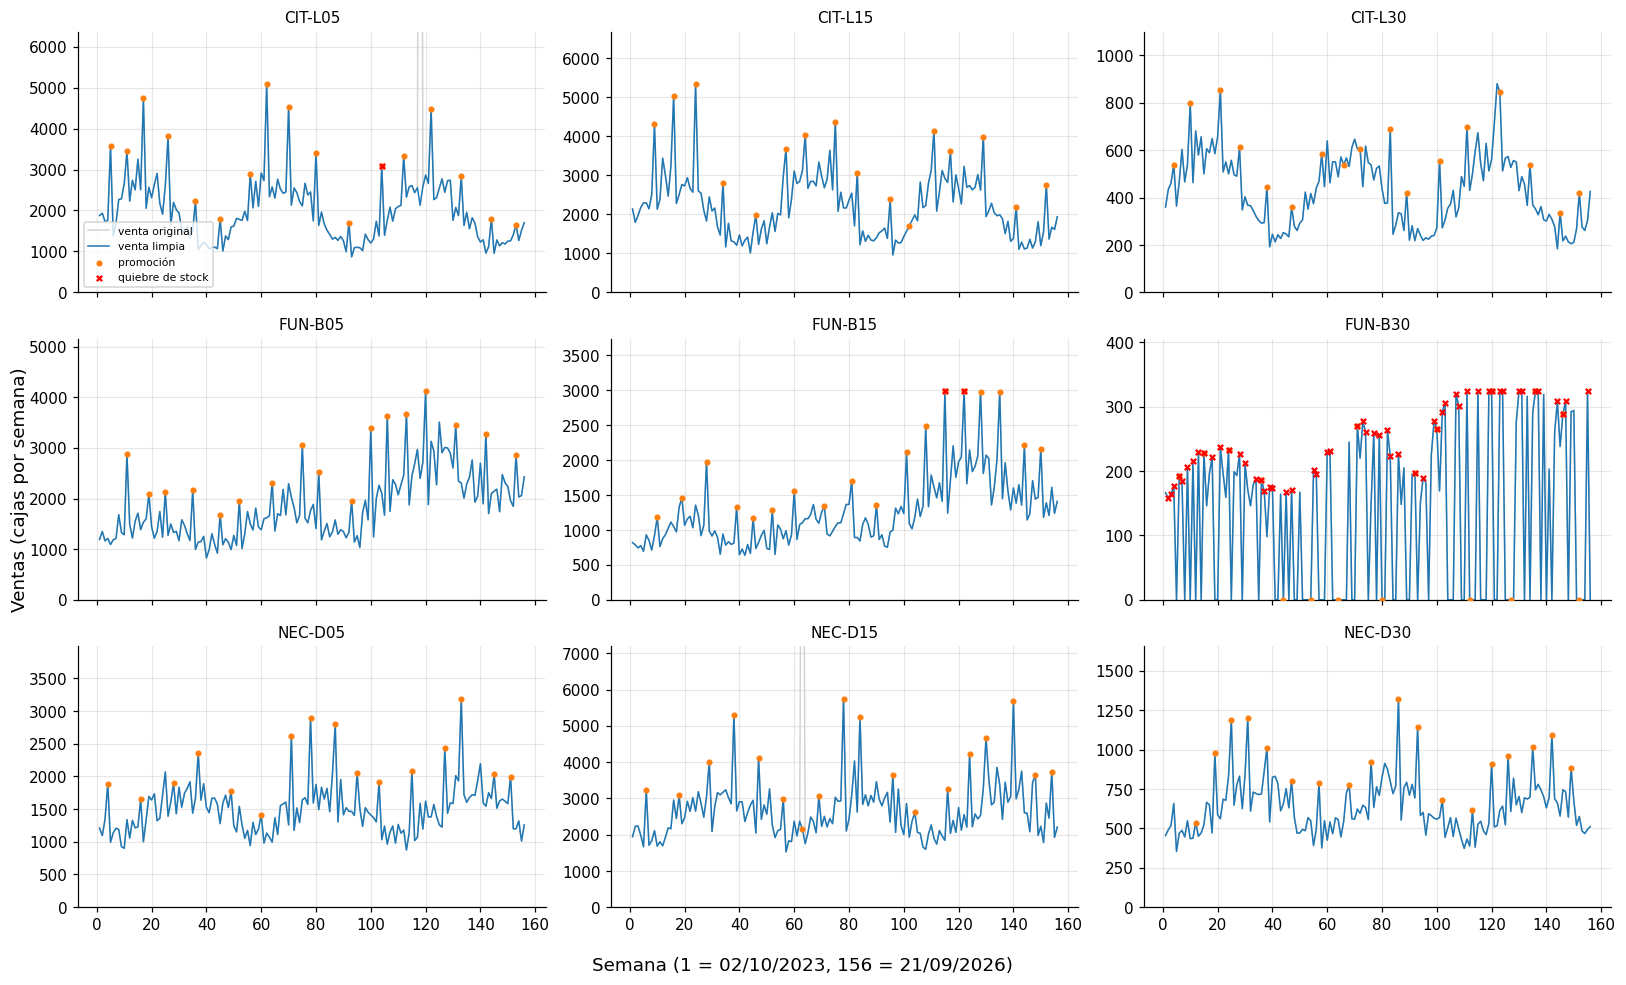

In [ ]:
fig, ejes = plt.subplots(3, 3, figsize=(15, 9), sharex=True)
for ax, sku in zip(ejes.flatten(), skus):
    ax.plot(ventas.index, ventas[sku], color="lightgray", lw=1, label="venta original")
    ax.plot(limpia.index, limpia[sku], color="tab:blue", lw=1, label="venta limpia")
    p = promo[sku] == 1
    ax.scatter(limpia.index[p], limpia[sku][p], color="tab:orange", s=9, zorder=3, label="promoción")
    q = sin_stock_l[sku] > 0
    ax.scatter(limpia.index[q], limpia[sku][q], color="red", marker="x", s=12, zorder=3, label="quiebre de stock")
    ax.set_title(sku, fontsize=10)
    ax.set_ylim(0, limpia[sku].max() * 1.25)          # el eje no se estira por los atípicos originales
ejes[0, 0].legend(fontsize=7, loc="lower left")
fig.supxlabel("Semana (1 = 02/10/2023, 156 = 21/09/2026)")
fig.supylabel("Ventas (cajas por semana)")
plt.tight_layout()
plt.show()

### 4.2 Tratamiento de la censura: de ventas a demanda

**Supuesto.** La demanda de una semana se reparte de forma homogénea entre sus 7 días. Si hubo
$d$ días sin stock, lo vendido corresponde solo a los $7-d$ días con stock, y la demanda se reconstruye
como

$$\hat D_t = V_t \cdot \frac{7}{7-d_t}$$

**Justificación.** Es el supuesto más simple que usa la información disponible dias_sin_stock y no
requiere estimar nada sobre los datos: es una corrección fila a fila, por lo que **no genera fuga**.

**Límites:** (i) si $d = 7$ no hay información y se conserva la venta (no ocurre en estos datos); (ii) si
la demanda se concentra en ciertos días o parte de ella se traslada a otro SKU, la corrección sobrestima o
subestima. El efecto relevante está en FUN-B30, el SKU con más quiebres.

,semanas_quiebre,dias_sin_stock,ventas_cajas,demanda_estimada,cajas_perdidas,incremento_%
sku,,,,,,
CIT-L05,1,1.0,312559.0,313072.0,513.0,0.2
CIT-L15,0,0.0,346485.0,346485.0,0.0,0.0
CIT-L30,0,0.0,67345.0,67345.0,0.0,0.0
FUN-B05,0,0.0,287498.0,287498.0,0.0,0.0
FUN-B15,2,2.0,197744.0,198740.0,996.0,0.5
FUN-B30,55,139.0,20182.0,30050.3,9868.3,48.9
NEC-D05,0,0.0,235004.0,235004.0,0.0,0.0
NEC-D15,0,0.0,415969.0,415969.0,0.0,0.0
NEC-D30,0,0.0,99852.0,99852.0,0.0,0.0


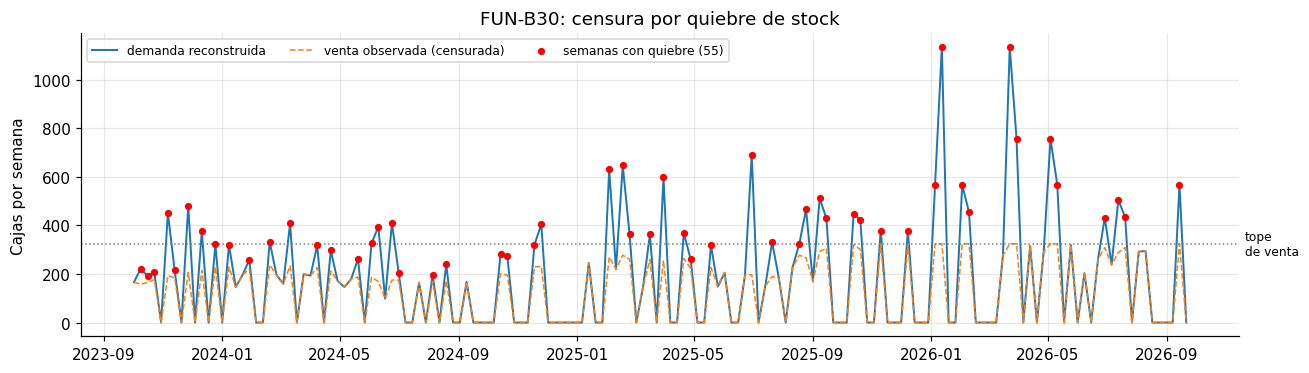

In [ ]:
assert (sin_stock_l < 7).all().all(), "Hay semanas con 7 días sin stock: el supuesto no aplica"
factor = 7 / (7 - sin_stock_l)
demanda = limpia * factor                       # demanda reconstruida (desrestringida)

tabla_censura = pd.DataFrame({"semanas_quiebre": (sin_stock_l > 0).sum(), "dias_sin_stock": sin_stock_l.sum(),
                              "ventas_cajas": limpia.sum(), "demanda_estimada": demanda.sum()})
tabla_censura["cajas_perdidas"] = tabla_censura["demanda_estimada"] - tabla_censura["ventas_cajas"]
tabla_censura["incremento_%"] = 100 * tabla_censura["cajas_perdidas"] / tabla_censura["ventas_cajas"]
display(tabla_censura.round(1))

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(fechas, demanda["FUN-B30"], color="tab:blue", lw=1.3, label="demanda reconstruida")
ax.plot(fechas, limpia["FUN-B30"], color="tab:orange", ls="--", lw=1, label="venta observada (censurada)")
q = sin_stock_l["FUN-B30"] > 0
ax.scatter(fechas[q], demanda["FUN-B30"][q], color="red", s=14, zorder=4, label=f"semanas con quiebre ({q.sum()})")
ax.axhline(ventas["FUN-B30"].max(), color="gray", ls=":", lw=1)
ax.text(1.005, ventas["FUN-B30"].max(), "tope\nde venta", transform=ax.get_yaxis_transform(), va="center", fontsize=8)
ax.set(title="FUN-B30: censura por quiebre de stock", ylabel="Cajas por semana")
ax.legend(fontsize=8, loc="upper left", ncol=3)
plt.tight_layout()
plt.show()

**Lectura de resultados.** La corrección es despreciable en CIT-L05 (+0,2 %) y FUN-B15 (+0,5 %). En
**FUN-B30 la demanda reconstruida es 48,9 % mayor que la venta** (+9.868 cajas en 3 años). Tratar las ventas
como demanda en este SKU subestimaría su pronóstico en casi un tercio y perpetuaría el quiebre: si se
planifica para lo que se vendió, se vuelve a producir de menos. Un costo del supuesto: en semanas con 4 o
5 días sin stock el factor es 2,3 a 3,5, y esas semanas quedan como picos de hasta ≈ 1.100 cajas. Es el
precio de no tener un dato de demanda directo, y por eso FUN-B30 es el SKU más incierto. A partir de aquí
todo el pronóstico usa `demanda` (reconstruida), no `ventas`.

### 4.3 Partición temporal, regresores y modelos

**Partición.** El tramo de prueba son las últimas $H = 13$ semanas (144 a 156) y no se usa para
ajustar ni para elegir nada, solo se mira una vez, al final, para confirmar. Toda la selección (modelo
ganador, órdenes de SARIMA, método jerárquico) se hace con origen deslizante dentro de las semanas
1 a 143.

In [ ]:
FIN_TRAIN = len(demanda) - H                                  # semana 143
train, test = demanda.loc[:FIN_TRAIN], demanda.loc[FIN_TRAIN + 1:]
print("Entrenamiento: semanas", train.index.min(), "a", train.index.max(), f"({len(train)} semanas)")
print("Prueba:        semanas", test.index.min(), "a", test.index.max(), f"({len(test)} semanas)")
assert train.index.max() < test.index.min()

Entrenamiento: semanas 1 a 143 (143 semanas)
Prueba:        semanas 144 a 156 (13 semanas)


**¿Promoción y precio como regresores? (se justifica, no se asume).** Se revisan tres cosas: si el precio
de lista cambia en el tiempo, si el precio efectivo se mueve fuera de las promociones y si la promoción
mueve las ventas.

In [ ]:
descuento = 1 - precio_ef / precio_li
print("Valores distintos del precio de lista por SKU:", precio_li.nunique().unique().tolist())
print("Semanas con descuento SIN promoción:", int(((descuento > 0) & (promo == 0)).sum().sum()))
print(f"Descuento en semanas con promoción: media {100 * descuento[promo == 1].stack().mean():.1f} % "
      f"| desviación {100 * descuento[promo == 1].stack().std():.1f} %")
print("Correlación entre la promoción y el descuento:", round(np.corrcoef(promo.values.ravel(), descuento.values.ravel())[0, 1], 3))

Valores distintos del precio de lista por SKU: [1]
Semanas con descuento SIN promoción: 0
Descuento en semanas con promoción: media 22.9 % | desviación 4.1 %
Correlación entre la promoción y el descuento: 0.983


**Lectura de resultados y decisión.** El precio de lista **nunca cambia** en las 156 semanas, el precio
efectivo **solo** baja en semanas de promoción y el descuento es casi constante (22,9 % ± 4,1 %). La
correlación promoción–descuento es 0,98. **Precio y promoción contienen la misma información**: meter
ambos en el modelo sería colinealidad sin ganancia. Se usa solo promocion como regresor, y la celda
siguiente verifica que sea significativa.

**Modelos.** Los cuatro modelos son los mismos del cuaderno original y se definen como funciones con la
misma firma, para usarlas igual en la validación, en la prueba y en el pronóstico final:

1. **Ingenuo estacional** (benchmark): $\hat y_{T+h} = y_{T+h-52}$. Es el benchmark apropiado porque las
   series tienen estacionalidad anual fuerte. Un ingenuo simple ignoraría el verano.
2. **ETS (Holt-Winters)**: nivel + tendencia amortiguada + estacionalidad *aditiva* de 52 semanas. Es
   aditiva porque FUN-B30 tiene ceros y la multiplicativa no los admite. Amortiguada para que el quiebre
   de FUN no se proyecte como crecimiento infinito.
3. **SARIMA** $(p,0,q)(0,1,0)_{52}$: la diferencia estacional compara cada semana con la del año anterior
   y la parte ARMA corrige lo que queda. Con 3 años no hay datos para términos estacionales adicionales.
4. **SARIMAX**: el mismo SARIMA con promocion como regresor. Como no existe un calendario de
   promociones futuras en los datos, el pronóstico usa la promoción esperada: la fracción de semanas
   con promoción del último año de entrenamiento (≈ 0,11). Así el pronóstico incluye el aumento medio que
   traen las promociones. Como referencia se evalúa también SARIMAX (calendario), que usa la promoción
   real de las semanas pronosticadas. Mide cuánto mejoraría el pronóstico si Comercial compartiera su
   calendario, pero no se puede elegir porque esa información no está disponible para el futuro.

Cada ajuste va dentro de `try/except`. Si un modelo no converge, se usa el ingenuo estacional y se deja
registrado (manejo de errores).

In [ ]:
fallos = []                                          # registro de ajustes que fallaron

def pron_naive_est(y, h):
    return y.iloc[-S:].iloc[:h].values

def pron_ets(y, h):
    try:
        m = ExponentialSmoothing(y.values, trend="add", damped_trend=True, seasonal="add", seasonal_periods=S,
                                 initialization_method="estimated").fit()
        return np.maximum(m.forecast(h), 0)
    except Exception as err:
        fallos.append(("ETS", y.name, len(y), str(err)[:60]))
        return pron_naive_est(y, h)

def ajustar_sarima(y, orden, x_hist=None):
    p, q, tendencia = orden
    return SARIMAX(y.values, exog=x_hist, order=(p, 0, q), seasonal_order=(0, 1, 0, S), trend=tendencia).fit(disp=False)

def elegir_orden(y, x_hist=None):
    """p, q y constante por AIC, usando SOLO la serie y que se le entrega."""
    mejor_aic, mejor = np.inf, (0, 0, "n")
    for p in [0, 1, 2]:
        for q in [0, 1]:
            for tendencia in ["n", "c"]:
                try:
                    aic = ajustar_sarima(y, (p, q, tendencia), x_hist).aic
                    if aic < mejor_aic:
                        mejor_aic, mejor = aic, (p, q, tendencia)
                except Exception:
                    pass
    return mejor

def pron_sarimas(y, h, orden_s, orden_x, x_hist, x_fut_real):
    """Devuelve los pronósticos SARIMA, SARIMAX (promo esperada) y SARIMAX (calendario real)."""
    salida = {}
    try:
        salida["SARIMA"] = np.maximum(ajustar_sarima(y, orden_s).forecast(h), 0)
    except Exception as err:
        fallos.append(("SARIMA", y.name, len(y), str(err)[:60])); salida["SARIMA"] = pron_naive_est(y, h)
    try:
        m = ajustar_sarima(y, orden_x, x_hist)
        x_esp = np.full((h, 1), x_hist[-S:].mean())                     # promoción esperada (último año)
        salida["SARIMAX"] = np.maximum(m.forecast(h, exog=x_esp), 0)
        salida["SARIMAX (calendario)"] = np.maximum(m.forecast(h, exog=x_fut_real), 0)
    except Exception as err:
        fallos.append(("SARIMAX", y.name, len(y), str(err)[:60]))
        salida["SARIMAX"] = salida["SARIMAX (calendario)"] = pron_naive_est(y, h)
    return salida

**¿La promoción es significativa?** Se ajusta el SARIMAX con todo el entrenamiento y se mira el
coeficiente de promocion y su p-valor. Es solo una prueba de significancia: los órdenes que se usan
en la validación se eligen en la celda de 4.4, con datos anteriores al primer origen.

In [ ]:
filas, orden_x_143 = [], {}
for sku in skus:
    y, x = train[sku], promo.loc[:FIN_TRAIN, [sku]].values
    orden = elegir_orden(y, x)
    orden_x_143[sku] = orden                                  # se reutiliza en la prueba (mismos datos 1-143)
    m = ajustar_sarima(y, orden, x)
    i = m.param_names.index("x1")
    filas.append([sku, orden, m.params[i], m.pvalues[i], m.params[i] / y.mean() * 100])
regresor = pd.DataFrame(filas, columns=["sku", "orden SARIMAX (p,q,tend)", "efecto_promo_cajas", "p_valor", "efecto_%_del_nivel"])
regresor["significativa_5%"] = regresor["p_valor"] < 0.05
display(regresor.round(3))

,sku,"orden SARIMAX (p,q,tend)",efecto_promo_cajas,p_valor,efecto_%_del_nivel,significativa_5%
0,CIT-L05,"(2, 1, n)",1367.002,0.000,66.162,True
1,CIT-L15,"(0, 0, n)",1315.056,0.000,57.591,True
2,CIT-L30,"(0, 0, n)",158.150,0.000,35.454,True
3,FUN-B05,"(1, 1, c)",981.198,0.000,54.143,True
4,FUN-B15,"(1, 1, n)",768.631,0.000,61.289,True
5,FUN-B30,"(0, 0, c)",178.852,0.003,93.713,True
6,NEC-D05,"(1, 0, n)",736.925,0.000,48.938,True
7,NEC-D15,"(0, 1, n)",1394.789,0.000,52.155,True
8,NEC-D30,"(0, 0, n)",295.789,0.000,45.998,True


**Lectura de resultados.** El coeficiente de promoción es **significativo al 5 % en los 9 SKU** (p ≤ 0,003)
y equivale a +35 % a +94 % del nivel medio de cada serie. **La promoción se justifica como regresor**. Que
mejore el pronóstico *fuera de muestra* se verifica en la validación (4.4), no se asume por el p-valor.

### 4.4 Validación por origen deslizante (8 ventanas, h = 13): WAPE, MASE y sesgo por horizonte

**Diseño.** Hay 8 orígenes dentro del entrenamiento. El último origen es la semana 130 (130 + 13 = 143)
y los demás retroceden de a paso = 3 semanas: 109, 112, …, 130. En cada origen se ajusta cada modelo
solo con las semanas hasta el origen y se pronostican las 13 siguientes. La ventana de ajuste es
*creciente* (expanding window).

**Selección de órdenes sin fuga.** Los órdenes $(p,q)$ de SARIMA y SARIMAX se eligen por AIC con las
semanas 1 a 109 (el primer origen). Esos datos están dentro del entrenamiento de *todos* los
pliegues, así que ningún pliegue usa información posterior a su origen para elegir el modelo.

**Métricas** (error $e = \hat y - y$;)
- **WAPE** $= \sum|e| / \sum y$: error relativo al volumen; no explota con ceros (FUN-B30), a
  diferencia del MAPE.
- **MASE** $= \text{media}(|e|/q)$, con $q = \text{media}|y_t - y_{t-52}|$, el error del **ingenuo
  estacional** dentro del entrenamiento de ese origen (escala estacional, porque las series son
  estacionales). MASE < 1 significa que el modelo es mejor que ese benchmark.
- **Sesgo %** $= \sum e / \sum y$: un sesgo sistemático genera quiebres (si es negativo) o inventario (si
  es positivo).

In [ ]:
ORIGENES = [FIN_TRAIN - H - CONFIG["paso"] * k for k in range(CONFIG["ventanas"] - 1, -1, -1)]
assert len(ORIGENES) >= 8 and max(ORIGENES) + H <= FIN_TRAIN, "Algún pliegue toca la prueba"
print("Orígenes:", ORIGENES, "| semanas evaluadas:", ORIGENES[0] + 1, "a", ORIGENES[-1] + H)

SEMANA_SELECCION = ORIGENES[0]                                # los órdenes se eligen con las semanas 1 a 109
ordenes_cv = {}
for sku in skus:
    y0, x0 = demanda.loc[:SEMANA_SELECCION, sku], promo.loc[:SEMANA_SELECCION, [sku]].values
    ordenes_cv[sku] = (elegir_orden(y0), elegir_orden(y0, x0))
display(pd.DataFrame(ordenes_cv, index=["orden SARIMA", "orden SARIMAX"]).T)

def pronosticar_todos(y, x_hist, x_fut_real, ordenes, h=H):
    f = {"Ingenuo estacional": pron_naive_est(y, h), "ETS": pron_ets(y, h)}
    f.update(pron_sarimas(y, h, ordenes[0], ordenes[1], x_hist, x_fut_real))
    return f

filas = []
for sku in skus:
    for o in ORIGENES:
        y = demanda.loc[:o, sku]
        assert y.index.max() == o                                     # el ajuste no ve nada después del origen
        x_hist, x_fut = promo.loc[:o, [sku]].values, promo.loc[o + 1:o + H, [sku]].values
        real = demanda.loc[o + 1:o + H, sku].values
        escala = y.diff(S).abs().mean()                               # escala del MASE: ingenuo estacional en el entrenamiento del pliegue
        for modelo, f in pronosticar_todos(y, x_hist, x_fut, ordenes_cv[sku]).items():
            for h in range(1, H + 1):
                filas.append([sku, modelo, o, h, real[h - 1], f[h - 1], escala])

cv = pd.DataFrame(filas, columns=["sku", "modelo", "origen", "h", "y", "yhat", "escala"])
cv["e"] = cv["yhat"] - cv["y"]
MODELOS = ["Ingenuo estacional", "ETS", "SARIMA", "SARIMAX", "SARIMAX (calendario)"]
print("Filas de validación:", len(cv), "=", len(skus), "SKU x", len(ORIGENES), "orígenes x", H, "h x", len(MODELOS), "modelos")
print("Ajustes con error (se usó el ingenuo):", len(fallos))

Orígenes: [109, 112, 115, 118, 121, 124, 127, 130] | semanas evaluadas: 110 a 143


,orden SARIMA,orden SARIMAX
CIT-L05,"(1, 0, n)","(2, 1, n)"
CIT-L15,"(0, 1, n)","(0, 0, n)"
CIT-L30,"(0, 1, c)","(0, 1, c)"
FUN-B05,"(0, 0, c)","(1, 1, c)"
FUN-B15,"(0, 0, c)","(1, 1, c)"
FUN-B30,"(0, 0, n)","(0, 0, n)"
NEC-D05,"(0, 1, n)","(0, 0, n)"
NEC-D15,"(1, 0, n)","(0, 0, n)"
NEC-D30,"(0, 1, n)","(0, 0, n)"


Filas de validación: 4680 = 9 SKU x 8 orígenes x 13 h x 5 modelos
Ajustes con error (se usó el ingenuo): 0


 La validación genera 4.680 pronósticos (9 SKU × 8 orígenes × 13 horizontes ×
5 modelos). Todos los ajustes convergieron. Los órdenes elegidos con las semanas 1 a 109 son pequeños,
$p \le 2$ y $q \le 1$, como corresponde a una serie ya diferenciada estacionalmente. La constante (drift)
aparece sobre todo en FUN-B05 y FUN-B15, las series que crecen.

=== MÉTRICAS GLOBALES (9 SKU, 8 orígenes, h = 1 a 13) ===


,WAPE_%,MASE,Sesgo_%
modelo,,,
Ingenuo estacional,27.60,1.32,-12.53
ETS,20.86,1.03,0.95
SARIMA,23.94,1.19,-7.88
SARIMAX,20.23,1.05,-4.60
SARIMAX (calendario),17.18,0.90,-4.65


=== WAPE_% por horizonte ===


modelo,Ingenuo estacional,ETS,SARIMA,SARIMAX,SARIMAX (calendario)
h,,,,,
1,26.81,19.46,21.31,20.56,17.27
2,25.41,18.81,21.50,17.03,13.27
3,29.36,23.43,27.56,22.21,19.42
4,26.36,19.27,22.08,20.10,16.38
5,26.41,18.76,22.56,16.71,13.95
6,30.94,24.62,28.75,22.96,19.54
7,26.34,17.46,22.05,19.75,16.51
8,26.02,19.44,21.96,17.93,15.57
9,29.49,23.97,27.37,22.02,19.27


=== MASE por horizonte ===


modelo,Ingenuo estacional,ETS,SARIMA,SARIMAX,SARIMAX (calendario)
h,,,,,
1,1.23,0.94,1.04,1.01,0.89
2,1.18,0.97,1.04,0.90,0.68
3,1.45,1.14,1.38,1.18,1.04
4,1.26,0.96,1.10,1.05,0.89
5,1.21,0.97,1.07,0.86,0.68
6,1.52,1.20,1.43,1.22,1.05
7,1.26,0.89,1.11,1.03,0.88
8,1.28,1.02,1.13,0.95,0.79
9,1.38,1.08,1.30,1.10,0.99


=== Sesgo_% por horizonte ===


modelo,Ingenuo estacional,ETS,SARIMA,SARIMAX,SARIMAX (calendario)
h,,,,,
1,-14.69,-1.98,-8.89,-4.06,-3.91
2,-13.46,0.07,-8.95,-3.61,-3.62
3,-6.94,2.72,-2.37,-1.18,0.54
4,-13.69,-1.24,-9.23,-4.17,-3.86
5,-12.54,1.41,-8.01,-4.32,-4.65
6,-7.92,3.03,-3.37,-3.41,-2.87
7,-15.36,-2.61,-10.92,-6.13,-6.80
8,-14.63,2.14,-10.10,-6.56,-6.94
9,-4.71,6.44,0.01,0.21,-0.38


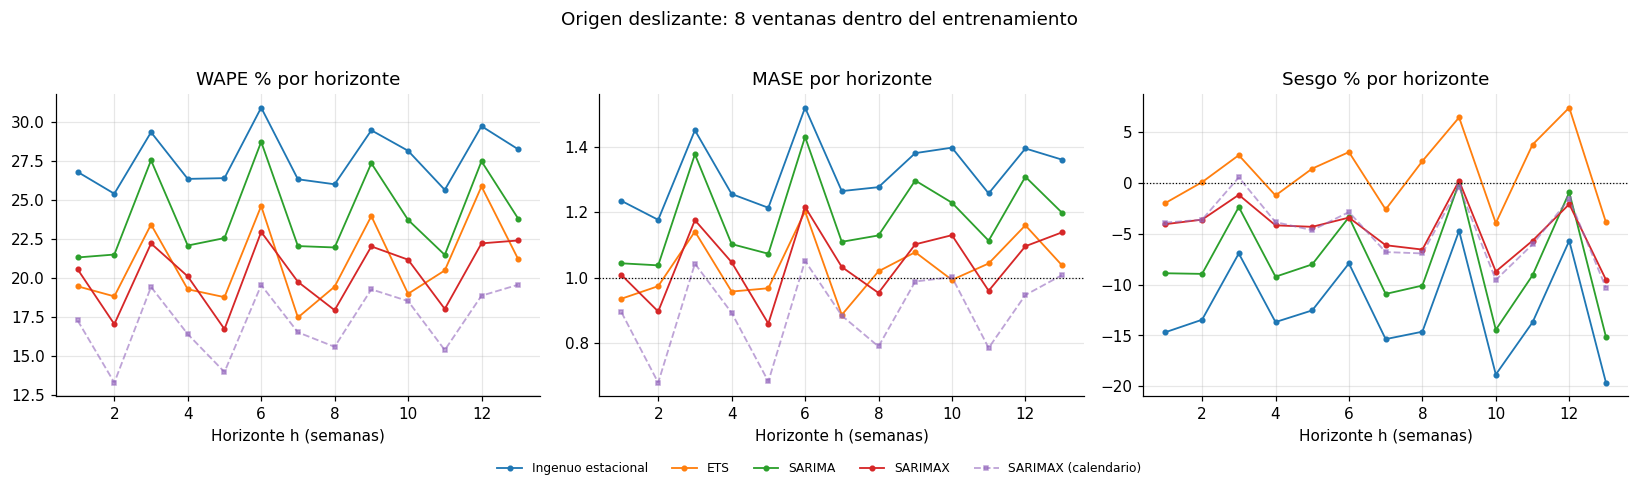

In [ ]:
def metricas(g):
    return pd.Series({"WAPE_%": 100 * g["e"].abs().sum() / g["y"].sum(),
                      "MASE": (g["e"].abs() / g["escala"]).mean(),
                      "Sesgo_%": 100 * g["e"].sum() / g["y"].sum()})

global_cv = cv.groupby("modelo").apply(metricas).loc[MODELOS]
print("=== MÉTRICAS GLOBALES (9 SKU, 8 orígenes, h = 1 a 13) ===")
display(global_cv.round(2))

por_h = cv.groupby(["modelo", "h"]).apply(metricas).reset_index()
for met in ["WAPE_%", "MASE", "Sesgo_%"]:
    print(f"=== {met} por horizonte ===")
    display(por_h.pivot(index="h", columns="modelo", values=met)[MODELOS].round(2))

fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
for ax, met, ref in zip(ejes, ["WAPE_%", "MASE", "Sesgo_%"], [None, 1, 0]):
    for m in MODELOS:
        r = por_h[por_h["modelo"] == m]
        ax.plot(r["h"], r[met], "o-" if m != "SARIMAX (calendario)" else "s--", ms=3, lw=1.2, label=m,
                alpha=0.6 if m == "SARIMAX (calendario)" else 1)
    if ref is not None:
        ax.axhline(ref, color="black", lw=0.8, ls=":")
    ax.set(xlabel="Horizonte h (semanas)", title=met.replace("_", " ") + " por horizonte")
h_, l_ = ejes[0].get_legend_handles_labels()
fig.legend(h_, l_, loc="lower center", ncol=5, fontsize=8, frameon=False, bbox_to_anchor=(0.5, -0.06))
plt.suptitle("Origen deslizante: 8 ventanas dentro del entrenamiento", y=1.02)
plt.tight_layout()
plt.show()

**Lectura de resultados.**
- **Todos los modelos le ganan al benchmark.** El ingenuo estacional tiene WAPE = 27,6 % y un sesgo de
  −12,5 % (subestima siempre, porque repite el año anterior y no ve el crecimiento de FUN). SARIMAX
  (20,2 %) y ETS (20,9 %) lo mejoran en ≈ 25 %.
- **SARIMAX y ETS quedan casi empatados en WAPE y MASE.** ETS tiene menos sesgo (+0,9 % contra −4,6 %).
  SARIMAX se queda corto en las semanas de promoción reales, porque pronostica la promoción *esperada*. El
  criterio fijado de antemano es el menor WAPE, así que se elige SARIMAX. ETS queda como alternativa
  robusta y el sesgo de SARIMAX se reporta.
- **El error no crece con fuerza dentro de 13 semanas** (WAPE de 17 a 23 % en todo el rango). Los
  dientes en h = 3, 6, 9 y 12 son un **artefacto del paso 3**: una misma semana difícil (una promoción
  fuerte) cae en h = 3, 6, 9 y 12 de orígenes distintos.
- **SARIMAX (calendario)** baja el WAPE a 17,2 % y el MASE a 0,90. Es el **valor de la información de
  Comercial**: si el calendario de promociones se compartiera con Planificación, el pronóstico mejoraría
  3 puntos más. Esto responde directamente a la segunda queja de la gerencia (dos planes porque nadie
  comparte su número).
- El MASE del propio ingenuo estacional es > 1 (1,32) porque el periodo evaluado incluye el año posterior
  al salto de FUN, que ese benchmark no puede seguir. El MASE se lee para **comparar** modelos.

In [ ]:
wape_sku = cv.groupby(["sku", "modelo"]).apply(lambda g: 100 * g["e"].abs().sum() / g["y"].sum()).unstack()[MODELOS]
print(" WAPE (%) por SKU y modelo ")
display(wape_sku.round(1))
mase_sku = cv.groupby(["sku", "modelo"]).apply(lambda g: (g["e"].abs() / g["escala"]).mean()).unstack()[MODELOS]
print(" MASE por SKU y modelo")
display(mase_sku.round(2))

ELEGIBLES = ["ETS", "SARIMA", "SARIMAX"]                      # el calendario futuro no está disponible
MODELO_BASE = global_cv.loc[ELEGIBLES, "WAPE_%"].idxmin()
mejora_vs_naive = 100 * (1 - global_cv.loc[MODELO_BASE, "WAPE_%"] / global_cv.loc["Ingenuo estacional", "WAPE_%"])
valor_calendario = global_cv.loc[MODELO_BASE, "WAPE_%"] - global_cv.loc["SARIMAX (calendario)", "WAPE_%"]
print(f"Modelo elegido (menor WAPE global entre los implementables): {MODELO_BASE}")
print(f"Mejora sobre el benchmark ingenuo estacional: {mejora_vs_naive:.1f} % menos WAPE")
print(f"Si Comercial compartiera el calendario de promociones, el WAPE bajaría {valor_calendario:.1f} puntos más")

 WAPE (%) por SKU y modelo 


modelo,Ingenuo estacional,ETS,SARIMA,SARIMAX,SARIMAX (calendario)
sku,,,,,
CIT-L05,16.8,18.3,16.6,14.7,11.2
CIT-L15,20.2,18.9,19.9,17.0,12.7
CIT-L30,17.1,14.0,17.7,16.3,14.9
FUN-B05,36.5,18.2,24.1,18.3,17.2
FUN-B15,43.5,25.3,32.9,24.2,20.2
FUN-B30,100.6,110.8,100.6,101.1,99.8
NEC-D05,24.0,19.0,23.7,20.9,16.4
NEC-D15,22.8,19.1,22.7,19.4,17.5
NEC-D30,17.1,14.9,17.2,19.9,14.5


 MASE por SKU y modelo


modelo,Ingenuo estacional,ETS,SARIMA,SARIMAX,SARIMAX (calendario)
sku,,,,,
CIT-L05,0.76,0.82,0.75,0.66,0.50
CIT-L15,0.89,0.84,0.88,0.75,0.56
CIT-L30,1.07,0.87,1.10,1.02,0.93
FUN-B05,1.86,0.93,1.23,0.94,0.89
FUN-B15,2.39,1.35,1.82,1.35,1.14
FUN-B30,1.40,1.55,1.40,1.41,1.39
NEC-D05,1.46,1.16,1.45,1.28,1.00
NEC-D15,1.18,0.99,1.17,1.00,0.91
NEC-D30,0.88,0.77,0.89,1.02,0.74


Modelo elegido (menor WAPE global entre los implementables): SARIMAX
Mejora sobre el benchmark ingenuo estacional: 26.7 % menos WAPE
Si Comercial compartiera el calendario de promociones, el WAPE bajaría 3.0 puntos más


 El ranking cambia por SKU: ETS es mejor en CIT-L30, FUN-B05 (por poco) y los tres
NEC; SARIMAX en CIT-L05, CIT-L15 y FUN-B15. Se mantiene **un solo modelo** para todas las series porque la
diferencia global es pequeña y elegir por SKU con solo 8 orígenes sobreajusta la selección. En **FUN-B30
ningún modelo baja de ≈ 100 % de WAPE**: con demanda intermitente, lo que se pronostica bien es el nivel,
no la semana. El MASE lo confirma: en FUN-B30 todos los modelos quedan en ≈ 1,4, sin mejorar al ingenuo.
Un método específico para demanda intermitente (Croston o TSB) queda como mejora propuesta para este SKU.

### 4.5 Reconciliación jerárquica: bottom-up, top-down y middle-out

La jerarquía tiene 13 series: 9 SKU, 3 familias y la Planta. Un pronóstico **coherente** cumple que
cada familia es la suma de sus SKU y la Planta es la suma de todo.

- **Bottom-up:** se pronostica cada SKU y se suma hacia arriba.
- **Top-down:** se pronostica la Planta y se reparte con la proporción histórica de cada SKU.
- **Middle-out:** se pronostica cada familia y se reparte entre sus SKU con su proporción dentro de la
  familia; la Planta es la suma.

Se usa el modelo elegido en 4.4, los **mismos 8 orígenes** dentro del entrenamiento y las proporciones
calculadas con el último año **anterior a cada origen** (sin fuga). Para las familias y la Planta, el
regresor de promoción es el número de SKU en promoción esa semana.

In [ ]:
niveles = demanda[skus].copy()
promo_niv = promo[skus].copy()
for f in familias:
    niveles[f] = demanda[skus_de[f]].sum(axis=1)
    promo_niv[f] = promo[skus_de[f]].sum(axis=1)
niveles["Planta"], promo_niv["Planta"] = demanda[skus].sum(axis=1), promo[skus].sum(axis=1)
SERIES = list(niveles.columns)
nivel_de = {**{s: "SKU" for s in skus}, **{f: "Familia" for f in familias}, "Planta": "Planta"}

for uid in familias + ["Planta"]:                             # órdenes de las series agregadas, con datos hasta el primer origen
    y0, x0 = niveles.loc[:SEMANA_SELECCION, uid], promo_niv.loc[:SEMANA_SELECCION, [uid]].values
    ordenes_cv[uid] = (elegir_orden(y0), elegir_orden(y0, x0))

def pron_base(uid, hasta, ordenes, modelo=None, h=H):
    """Pronóstico base de una serie de la jerarquía con datos hasta la semana `hasta`."""
    modelo = modelo or MODELO_BASE
    y = niveles.loc[:hasta, uid]
    y.name = uid
    x_hist, x_fut = promo_niv.loc[:hasta, [uid]].values, promo_niv.reindex(range(hasta + 1, hasta + h + 1))[[uid]].fillna(0).values
    if modelo == "Ingenuo estacional":
        return pron_naive_est(y, h)
    if modelo == "ETS":
        return pron_ets(y, h)
    try:                                                      # se ajusta solo el modelo pedido
        if modelo == "SARIMA":
            return np.maximum(ajustar_sarima(y, ordenes[uid][0]).forecast(h), 0)
        m = ajustar_sarima(y, ordenes[uid][1], x_hist)
        x_f = x_fut if modelo == "SARIMAX (calendario)" else np.full((h, 1), x_hist[-S:].mean())
        return np.maximum(m.forecast(h, exog=x_f), 0)
    except Exception as err:
        fallos.append((modelo, uid, hasta, str(err)[:60]))
        return pron_naive_est(y, h)

def proporciones(hasta):
    hist = niveles.loc[hasta - CONFIG["semanas_proporcion"] + 1: hasta]
    assert hist.index.max() <= hasta                          # las proporciones no usan datos posteriores al origen
    en_planta = {s: hist[s].sum() / hist["Planta"].sum() for s in skus}
    en_familia = {s: hist[s].sum() / hist[familia_de[s]].sum() for s in skus}
    return en_planta, en_familia

def reconciliar(base, en_planta, en_familia):
    """base: DataFrame h x 13 series. Devuelve los tres métodos coherentes."""
    bu, td, mo = base.copy(), base.copy(), base.copy()
    for s in skus:
        td[s] = base["Planta"] * en_planta[s]
        mo[s] = base[familia_de[s]] * en_familia[s]
    for tabla_m in [bu, td, mo]:
        for f in familias:
            tabla_m[f] = tabla_m[skus_de[f]].sum(axis=1)
        tabla_m["Planta"] = tabla_m[skus].sum(axis=1)
    return {"Base (sin reconciliar)": base, "Bottom-up": bu, "Top-down": td, "Middle-out": mo}

METODOS = ["Base (sin reconciliar)", "Bottom-up", "Top-down", "Middle-out"]
filas = []
for o in ORIGENES:
    base = pd.DataFrame({uid: pron_base(uid, o, ordenes_cv) for uid in SERIES}, index=range(1, H + 1))
    real = niveles.loc[o + 1:o + H].reset_index(drop=True)
    real.index = range(1, H + 1)
    escala = niveles.loc[:o].diff(S).abs().mean()
    for metodo, pr in reconciliar(base, *proporciones(o)).items():
        for uid in SERIES:
            for h in range(1, H + 1):
                filas.append([metodo, nivel_de[uid], uid, o, h, pr.loc[h, uid], real.loc[h, uid], escala[uid]])

errores = pd.DataFrame(filas, columns=["metodo", "nivel", "serie", "origen", "h", "yhat", "y", "escala"])
errores["e"] = errores["yhat"] - errores["y"]

ORDEN_NIV = ["Planta", "Familia", "SKU"]
tab_jer = errores.groupby(["nivel", "metodo"]).apply(metricas).reset_index()
for met in ["WAPE_%", "MASE", "Sesgo_%"]:
    print(f"=== {met} por nivel y método (origen deslizante, entrenamiento) ===")
    display(tab_jer.pivot(index="nivel", columns="metodo", values=met).loc[ORDEN_NIV, METODOS].round(2))

wape_serie = errores[errores["nivel"] != "SKU"].groupby(["serie", "metodo"]).apply(
    lambda g: 100 * g["e"].abs().sum() / g["y"].sum()).unstack().loc[["Planta"] + familias, METODOS]
print("=== WAPE (%) de cada familia y de la Planta ===")
display(wape_serie.round(1))

METODO_ELEGIDO = tab_jer[(tab_jer["nivel"] == "SKU") & (tab_jer["metodo"] != "Base (sin reconciliar)")].set_index("metodo")["WAPE_%"].idxmin()
print("Método elegido (menor WAPE a nivel SKU, que es el que usa el plan de producción):", METODO_ELEGIDO)

=== WAPE_% por nivel y método (origen deslizante, entrenamiento) ===


metodo,Base (sin reconciliar),Bottom-up,Top-down,Middle-out
nivel,,,,
Planta,10.82,9.85,10.82,9.99
Familia,14.47,14.47,20.26,14.47
SKU,20.23,20.23,24.23,19.06


=== MASE por nivel y método (origen deslizante, entrenamiento) ===


metodo,Base (sin reconciliar),Bottom-up,Top-down,Middle-out
nivel,,,,
Planta,1.17,1.07,1.17,1.08
Familia,0.96,0.96,1.35,0.96
SKU,1.05,1.05,1.24,1.00


=== Sesgo_% por nivel y método (origen deslizante, entrenamiento) ===


metodo,Base (sin reconciliar),Bottom-up,Top-down,Middle-out
nivel,,,,
Planta,-7.77,-4.6,-7.77,-4.57
Familia,-4.57,-4.6,-7.77,-4.57
SKU,-4.60,-4.6,-7.77,-4.57


=== WAPE (%) de cada familia y de la Planta ===


metodo,Base (sin reconciliar),Bottom-up,Top-down,Middle-out
serie,,,,
Planta,10.8,9.8,10.8,10.0
CIT,11.1,11.0,16.3,11.1
FUN,17.8,17.7,24.3,17.8
NEC,14.8,15.1,20.5,14.8


Método elegido (menor WAPE a nivel SKU, que es el que usa el plan de producción): Middle-out


**Lectura de resultados.**
- **A nivel SKU** (el que usa el plan) gana **middle-out**, con WAPE 19,1 % contra 20,2 % de bottom-up y
  24,2 % de top-down. **Top-down es el peor en los niveles bajos**: a nivel familia su WAPE es 20,3 %
  contra 14,5 % de los otros dos, y en CIT sube de 11,0 a 16,3 %.
- **A nivel Planta** los tres quedan cerca (9,9 a 10,8 %). Bottom-up es algo mejor y top-down tiene el
  mayor sesgo (−7,8 %).
- Middle-out gana a nivel SKU porque la **familia** es el nivel donde la señal es más limpia: sus tres
  formatos comparten la misma fase estacional, así que al sumarlos el ruido se cancela y la estación se
  refuerza. Luego la proporción dentro de la familia es estable.

**Evidencia de la pista: las familias no comparten la fase estacional.** Si cada familia tiene su pico en
un mes distinto, al sumarlas los picos de unas compensan los valles de otras. La Planta queda «plana» y
su pronóstico ya no sabe *qué* familia sube. Top-down reparte con una proporción fija y por eso traslada
mal la estacionalidad a los SKU.

,mes_pico,mes_valle,amplitud (pico/valle)
sku,,,
Planta,3,7,1.52
CIT,1,7,2.41
FUN,1,7,1.73
NEC,6,11,1.62


Correlación entre los perfiles estacionales de las familias:


sku,CIT,FUN,NEC
sku,,,
CIT,1.00,0.89,-0.47
FUN,0.89,1.00,-0.22
NEC,-0.47,-0.22,1.00


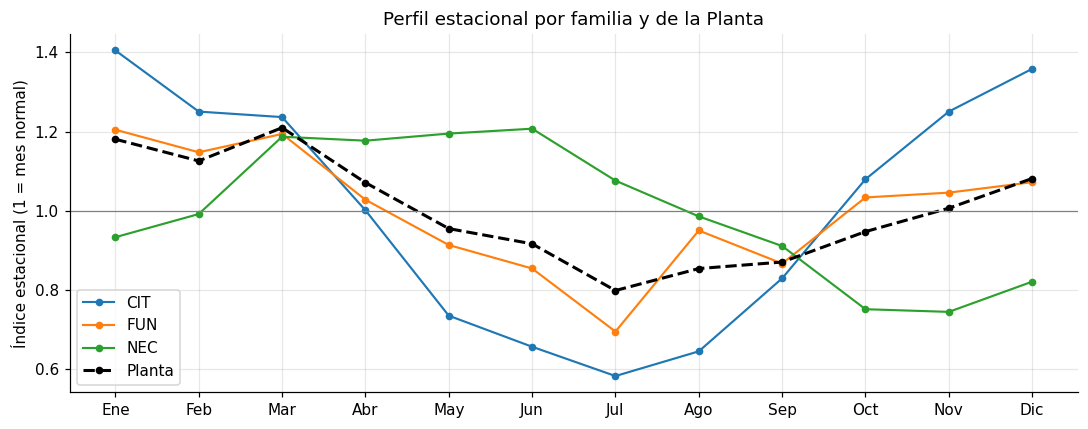

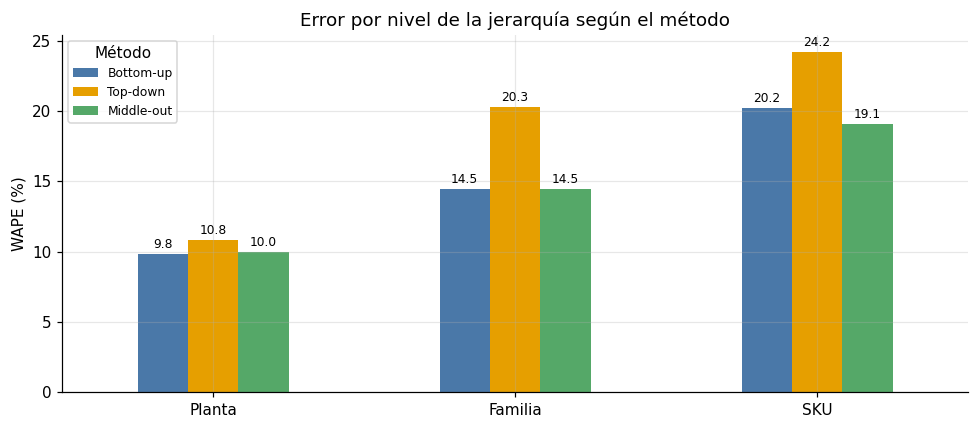

In [ ]:
tc = niveles.rolling(52, center=True, min_periods=40).mean()
indice_niv = (niveles / tc).groupby(mes).mean()
amplitud = pd.DataFrame({"mes_pico": indice_niv.idxmax(), "mes_valle": indice_niv.idxmin(),
                         "amplitud (pico/valle)": indice_niv.max() / indice_niv.min()}).loc[["Planta"] + familias]
display(amplitud.round(2))
print("Correlación entre los perfiles estacionales de las familias:")
display(indice_niv[familias].corr().round(2))

fig, ax = plt.subplots(figsize=(10, 4))
meses_txt = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
for uid, est in zip(familias + ["Planta"], ["-", "-", "-", "--"]):
    ax.plot(meses_txt, indice_niv[uid], est, marker="o", ms=4, lw=2 if uid == "Planta" else 1.4,
            color="black" if uid == "Planta" else None, label=uid)
ax.axhline(1, color="gray", lw=0.8)
ax.set(ylabel="Índice estacional (1 = mes normal)", title="Perfil estacional por familia y de la Planta")
ax.legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
piv = tab_jer.pivot(index="nivel", columns="metodo", values="WAPE_%").loc[ORDEN_NIV, METODOS[1:]]
piv.plot(kind="bar", ax=ax, rot=0, color=["#4a78a8", "#e69f00", "#55a868"])
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.1f", fontsize=8, padding=2)
ax.set(ylabel="WAPE (%)", xlabel="", title="Error por nivel de la jerarquía según el método")
ax.legend(title="Método", fontsize=8)
plt.tight_layout()
plt.show()

**Lectura de resultados (la pista, con evidencia).** CIT y FUN tienen la misma fase (correlación 0,89),
pero **NEC va en contrafase** (−0,47 con CIT, −0,22 con FUN). Al sumar las tres familias, la Planta queda
con una amplitud de solo 1,52 y su peak se va a **marzo**, un mes que no es el peak de ninguna familia.
**La agregación al total cancela parte de la señal en lugar de reforzarla.** Top-down pronostica esa serie
«aplanada» y la reparte con proporciones fijas, así que en diciembre le da a NEC una parte que en realidad
es de CIT, y en junio al revés. Por eso top-down falla justamente a nivel familia y SKU, y por eso el
nivel intermedio (familia), donde la fase es común, es el mejor punto para pronosticar.

### 4.6 Confirmación en el tramo de prueba (semanas 144 a 156) y cobertura de los intervalos

Recién ahora se usa la prueba, y **una sola vez**. Se reentrena con las semanas 1 a 143 (órdenes
re-elegidos con esas semanas y proporciones del último año del entrenamiento) y se compara contra lo que
realmente pasó. El modelo y el método ya están fijados: la prueba **confirma**, no elige.

**Desviación del error $\hat\sigma_{i,h}$.** Sale de los errores fuera de muestra del origen deslizante
con el modelo y método elegidos: la raíz del error cuadrático medio por SKU y horizonte. Con 8 orígenes
hay solo 8 errores por SKU y $h$, así que se usa una banda $h-1$ a $h+1$ (24 errores) para estabilizar la
estimación. Además se fuerza a que no disminuya con $h$, porque la incertidumbre no puede bajar al
alejarse. El intervalo es
$\hat y \pm z\,\hat\sigma_{i,h}$ con $z = 1{,}28$ (80 %) y $1{,}96$ (95 %), truncado en 0. La **cobertura
empírica** es el porcentaje de semanas de prueba en que la demanda real cayó dentro del intervalo.

In [ ]:
def sigma_por_h(err):
    """RMSE por serie y horizonte, con una banda h-1..h+1 (24 errores en vez de 8) y forzado a no decrecer."""
    sig = {}
    for h in range(1, H + 1):
        banda = err[(err["h"] >= h - 1) & (err["h"] <= h + 1)]
        sig[h] = banda.groupby("serie")["e"].apply(lambda e: np.sqrt((e ** 2).mean()))
    return pd.DataFrame(sig).T.cummax()

sigma_cv = sigma_por_h(errores[errores["metodo"] == METODO_ELEGIDO])
Z = {nivel: stats.norm.ppf(0.5 + nivel / 2) for nivel in CONFIG["niveles_ip"]}

ordenes_test = {}
for uid in SERIES:                                            # órdenes re-elegidos con las semanas 1 a 143
    y0, x0 = niveles.loc[:FIN_TRAIN, uid], promo_niv.loc[:FIN_TRAIN, [uid]].values
    orden_x = orden_x_143[uid] if uid in orden_x_143 else elegir_orden(y0, x0)
    ordenes_test[uid] = (elegir_orden(y0) if MODELO_BASE == "SARIMA" else None, orden_x)

base_t = pd.DataFrame({uid: pron_base(uid, FIN_TRAIN, ordenes_test) for uid in SERIES}, index=range(1, H + 1))
naive_t = pd.DataFrame({uid: pron_base(uid, FIN_TRAIN, ordenes_test, "Ingenuo estacional") for uid in SERIES}, index=range(1, H + 1))
rec_t = reconciliar(base_t, *proporciones(FIN_TRAIN))
real_t = niveles.loc[FIN_TRAIN + 1:].reset_index(drop=True)
real_t.index = range(1, H + 1)

filas = []
for metodo, pr in list(rec_t.items()) + [("Benchmark ingenuo (bottom-up)", reconciliar(naive_t, *proporciones(FIN_TRAIN))["Bottom-up"])]:
    for nivel in ORDEN_NIV:
        cols = [u for u in SERIES if nivel_de[u] == nivel]
        e = (pr[cols] - real_t[cols]).values
        filas.append([metodo, nivel, 100 * np.abs(e).sum() / real_t[cols].values.sum(), 100 * e.sum() / real_t[cols].values.sum()])
prueba = pd.DataFrame(filas, columns=["metodo", "nivel", "WAPE_%", "Sesgo_%"])
print(f"=== PRUEBA (semanas 144-156), modelo {MODELO_BASE} ===")
display(prueba.pivot(index="metodo", columns="nivel", values="WAPE_%")[ORDEN_NIV].round(1))

pr_el = rec_t[METODO_ELEGIDO]
filas = []
for s in skus:
    for h in range(1, H + 1):
        y_, f_, sg_ = real_t.loc[h, s], pr_el.loc[h, s], sigma_cv.loc[h, s]
        fila = [s, h, y_, f_]
        for nivel, z in Z.items():
            fila.append(max(0, f_ - z * sg_) <= y_ <= f_ + z * sg_)
        filas.append(fila)
cob = pd.DataFrame(filas, columns=["sku", "h", "y", "yhat"] + [f"dentro_{int(100 * n)}" for n in Z])
cobertura = pd.DataFrame({f"IP {int(100 * n)} %": [100 * cob[f"dentro_{int(100 * n)}"].mean()] for n in Z}, index=["cobertura empírica %"])
cobertura.loc["cobertura nominal %"] = [100 * n for n in Z]
print("=== COBERTURA DE LOS INTERVALOS EN LA PRUEBA (9 SKU x 13 semanas = 117 puntos) ===")
display(cobertura.round(1))
print("Cobertura por SKU (%):")
display(cob.groupby("sku")[["dentro_80", "dentro_95"]].mean().mul(100).round(0).T)

=== PRUEBA (semanas 144-156), modelo SARIMAX ===


nivel,Planta,Familia,SKU
metodo,,,
Base (sin reconciliar),9.0,17.4,25.8
Benchmark ingenuo (bottom-up),8.6,19.1,27.9
Bottom-up,9.7,17.1,25.8
Middle-out,9.1,17.4,22.8
Top-down,9.0,18.7,24.2


=== COBERTURA DE LOS INTERVALOS EN LA PRUEBA (9 SKU x 13 semanas = 117 puntos) ===


,IP 80 %,IP 95 %
cobertura empírica %,93.2,99.1
cobertura nominal %,80.0,95.0


Cobertura por SKU (%):


sku,CIT-L05,CIT-L15,CIT-L30,FUN-B05,FUN-B15,FUN-B30,NEC-D05,NEC-D15,NEC-D30
dentro_80,100.0,92.0,100.0,92.0,100.0,100.0,100.0,62.0,92.0
dentro_95,100.0,100.0,100.0,100.0,100.0,100.0,100.0,92.0,100.0


**Lectura de resultados.**
- **La prueba confirma la elección.** A nivel SKU, SARIMAX + middle-out tiene WAPE = 22,8 % contra 27,9 %
  del benchmark ingenuo, 25,8 % de bottom-up y 24,2 % de top-down. A nivel Planta el benchmark es
  levemente mejor (8,6 % contra 9,1 %). Se reporta tal cual: el valor del modelo está en la desagregación,
  que es lo que usa el plan.
- **Cobertura:** 93 % para el IP 80 % y 99 % para el IP 95 %. **Los intervalos son conservadores**
  (sobrecubren). Hay dos razones: (i) $\hat\sigma$ incluye los grandes errores de las semanas de
  promoción (celda siguiente), y (ii) la prueba (julio a septiembre, temporada baja de CIT y FUN) es más
  tranquila que las ventanas de validación, que incluyen el verano. Solo NEC-D15 queda bajo lo nominal
  (62 % en el IP 80 %).
- **Implicancia para la Entrega 2:** un stock de seguridad calculado con estos $\hat\sigma$ protege bien
  contra quiebres. El costo es algo más de inventario en temporada baja.

**¿De dónde viene la incertidumbre?** Se separan los errores de validación según si la semana pronosticada
tuvo promoción o no. Sin calendario, el modelo pronostica la promoción *esperada* (≈ 0,11), así que en una
semana real de promoción se queda corto.

In [ ]:
err_el = errores[(errores["metodo"] == METODO_ELEGIDO) & (errores["nivel"] == "SKU")].copy()
err_el["semana"] = err_el["origen"] + err_el["h"]
err_el["promo"] = [promo_niv.loc[w, s_] for w, s_ in zip(err_el["semana"], err_el["serie"])]
desc_err = err_el.groupby(["serie", "promo"])["e"].agg(lambda e: np.sqrt((e ** 2).mean())).unstack("promo")
desc_err.columns = ["RMSE semanas sin promo", "RMSE semanas con promo"]
desc_err["sesgo medio con promo (cajas)"] = err_el[err_el["promo"] == 1].groupby("serie")["e"].mean()
desc_err["sigma_h13 usado"] = sigma_cv.loc[H, skus]
desc_err["reduccion_sigma_%_con_calendario"] = 100 * (1 - desc_err["RMSE semanas sin promo"] / desc_err["sigma_h13 usado"])
display(desc_err.round(0))

,RMSE semanas sin promo,RMSE semanas con promo,sesgo medio con promo (cajas),sigma_h13 usado,reduccion_sigma_%_con_calendario
serie,,,,,
CIT-L05,306.0,1021.0,-969.0,460.0,33.0
CIT-L15,404.0,1151.0,-1118.0,685.0,41.0
CIT-L30,77.0,244.0,-228.0,119.0,35.0
FUN-B05,493.0,1091.0,-960.0,659.0,25.0
FUN-B15,319.0,1557.0,-1529.0,735.0,57.0
FUN-B30,304.0,588.0,-302.0,361.0,16.0
NEC-D05,328.0,1087.0,-1044.0,528.0,38.0
NEC-D15,510.0,1606.0,-1376.0,985.0,48.0
NEC-D30,134.0,331.0,-318.0,187.0,28.0


**Lectura de resultados.** En todos los SKU el error de las semanas con promoción es **2 a 5 veces mayor**
que el de las semanas sin promoción, y es sistemáticamente negativo: se pronostica de menos, entre ≈ 230 y
1.500 cajas por semana de promoción. **La mayor fuente de incertidumbre del pronóstico es no conocer el
calendario de promociones.** Si Comercial lo compartiera, $\hat\sigma$ y el stock de seguridad de la
Entrega 2 se acercarían a la columna «sin promo»: la última columna muestra que bajarían entre ≈ 15 y 55 %
según el SKU.

### 4.7 Pronóstico final a 13 semanas por SKU (coherente, con intervalos al 80 % y 95 %)

Con el modelo y el método ya validados se reentrena con **toda** la historia (semanas 1 a 156). Los
órdenes se re-eligen con esas 156 semanas y las proporciones salen de las semanas 105 a 156. Las 13
semanas pronosticadas son el horizonte táctico de la Entrega 2: del 28/09/2026 al 21/12/2026.

In [ ]:
ULTIMA = niveles.index.max()
ordenes_fin = {}
for uid in SERIES:                                            # órdenes re-elegidos con las 156 semanas
    ordenes_fin[uid] = (elegir_orden(niveles[uid]) if MODELO_BASE == "SARIMA" else None,
                        elegir_orden(niveles[uid], promo_niv[[uid]].values) if MODELO_BASE.startswith("SARIMAX") else None)

base_fin = pd.DataFrame({uid: pron_base(uid, ULTIMA, ordenes_fin) for uid in SERIES}, index=range(1, H + 1))
pron_rec = reconciliar(base_fin, *proporciones(ULTIMA))[METODO_ELEGIDO]

# coherencia: cada familia = suma de sus SKU y Planta = suma de los 9 SKU
dif = max((pron_rec[skus_de[f]].sum(axis=1) - pron_rec[f]).abs().max() for f in familias)
dif = max(dif, (pron_rec[skus].sum(axis=1) - pron_rec["Planta"]).abs().max())
assert dif < 1e-6, "El pronóstico final no es coherente"
print(f"Modelo: {MODELO_BASE} | método: {METODO_ELEGIDO} | diferencia máxima de coherencia: {dif:.2e}")

fechas_fut = [fechas.iloc[-1] + pd.Timedelta(weeks=h) for h in range(1, H + 1)]
filas = []
for uid in SERIES:
    for h in range(1, H + 1):
        f_ = pron_rec.loc[h, uid]
        sg_ = sigma_cv.loc[h, uid] if uid in sigma_cv.columns else np.nan
        fila = [nivel_de[uid], uid, h, ULTIMA + h, fechas_fut[h - 1].date(), f_]
        for nivel, z in Z.items():
            fila += [max(0, f_ - z * sg_), f_ + z * sg_]
        filas.append(fila + [sg_])
pronostico_final = pd.DataFrame(filas, columns=["nivel", "serie", "t", "semana", "fecha_lunes", "pronostico",
                                                "inf_80", "sup_80", "inf_95", "sup_95", "sigma_h"])
pronostico_final.to_csv(os.path.join(CONFIG["carpeta_resultados"], "pronostico_final.csv"), index=False)

tabla_sku = pron_rec[skus].copy()
tabla_sku.index = [d.date() for d in fechas_fut]
print("=== PRONÓSTICO FINAL POR SKU (cajas por semana) ===")
display(tabla_sku.round(0))
tabla_fam = pron_rec[familias + ["Planta"]].copy()
tabla_fam.index = tabla_sku.index
print("=== FAMILIAS Y PLANTA (suma de los SKU) ===")
display(tabla_fam.round(0))
print("=== TOTAL 13 SEMANAS: pronóstico vs mismas 13 semanas del año anterior (demanda reconstruida) ===")
comp = pd.DataFrame({"pronostico_13s": pron_rec[skus].sum(), "año_anterior_13s": niveles.loc[ULTIMA - 51:ULTIMA - 39, skus].sum(),
                     "13 x media_ultimas_52s": 13 * niveles.loc[ULTIMA - 51:, skus].mean()})
comp["variacion_vs_año_anterior_%"] = 100 * (comp["pronostico_13s"] / comp["año_anterior_13s"] - 1)
display(comp.round(1))

Modelo: SARIMAX | método: Middle-out | diferencia máxima de coherencia: 0.00e+00
=== PRONÓSTICO FINAL POR SKU (cajas por semana) ===


,CIT-L05,CIT-L15,CIT-L30,FUN-B05,FUN-B15,FUN-B30,NEC-D05,NEC-D15,NEC-D30
2026-09-28,1647.0,1851.0,362.0,2023.0,1438.0,188.0,1260.0,2227.0,515.0
2026-10-05,2249.0,2527.0,495.0,2567.0,1826.0,239.0,1180.0,2086.0,482.0
2026-10-12,2062.0,2316.0,454.0,2248.0,1599.0,209.0,1144.0,2022.0,467.0
2026-10-19,1955.0,2197.0,430.0,2808.0,1996.0,261.0,1136.0,2008.0,464.0
2026-10-26,2386.0,2681.0,525.0,2284.0,1624.0,212.0,1165.0,2059.0,476.0
2026-11-02,2532.0,2845.0,557.0,2417.0,1719.0,225.0,1315.0,2324.0,537.0
2026-11-09,2317.0,2604.0,510.0,2639.0,1877.0,245.0,1177.0,2079.0,480.0
2026-11-16,2216.0,2490.0,488.0,2041.0,1451.0,190.0,1127.0,1991.0,460.0
2026-11-23,2419.0,2717.0,532.0,2831.0,2013.0,263.0,957.0,1691.0,391.0
2026-11-30,2800.0,3145.0,616.0,2085.0,1482.0,194.0,1181.0,2087.0,482.0


=== FAMILIAS Y PLANTA (suma de los SKU) ===


,CIT,FUN,NEC,Planta
2026-09-28,3861.0,3649.0,4001.0,11511.0
2026-10-05,5272.0,4631.0,3748.0,13651.0
2026-10-12,4832.0,4056.0,3634.0,12521.0
2026-10-19,4583.0,5065.0,3608.0,13256.0
2026-10-26,5592.0,4121.0,3701.0,13413.0
2026-11-02,5935.0,4361.0,4177.0,14473.0
2026-11-09,5431.0,4761.0,3736.0,13927.0
2026-11-16,5194.0,3682.0,3578.0,12453.0
2026-11-23,5669.0,5108.0,3038.0,13815.0
2026-11-30,6561.0,3761.0,3751.0,14072.0


=== TOTAL 13 SEMANAS: pronóstico vs mismas 13 semanas del año anterior (demanda reconstruida) ===


,pronostico_13s,año_anterior_13s,13 x media_ultimas_52s,variacion_vs_año_anterior_%
CIT-L05,30489.6,29055.0,25581.0,4.9
CIT-L15,34253.2,36298.0,28738.8,-5.6
CIT-L30,6708.2,6323.0,5628.2,6.1
FUN-B05,32583.0,32154.0,32249.0,1.3
FUN-B15,23168.7,22168.0,22931.2,4.5
FUN-B30,3027.2,1625.4,2996.2,86.2
NEC-D05,15426.6,15331.0,19808.2,0.6
NEC-D15,27257.1,26473.0,34999.0,3.0
NEC-D30,6300.3,6252.0,8089.8,0.8


**Lectura de resultados.** El pronóstico es **coherente**: la suma de los SKU es exactamente cada familia y
la Planta (diferencia 0). Para las 13 semanas (28/09 a 21/12/2026) la Planta suma ≈ 179.200 cajas. La
forma sigue la estación: CIT sube hacia diciembre, FUN crece y NEC se mantiene. Contra las mismas semanas
del año anterior, ocho SKU quedan dentro de ±7 %. La excepción es **FUN-B30 (+86 %)**: middle-out le asigna
su participación media dentro de FUN y la forma estacional de la familia, y las mismas semanas del año
anterior fueron especialmente bajas para este SKU intermitente. La columna «13 × media de las últimas 52
semanas» muestra que el pronóstico de FUN-B30 es coherente con su nivel anual reciente, ya corregido por
censura. Es el SKU con mayor incertidumbre relativa y conviene revisarlo con Comercial.

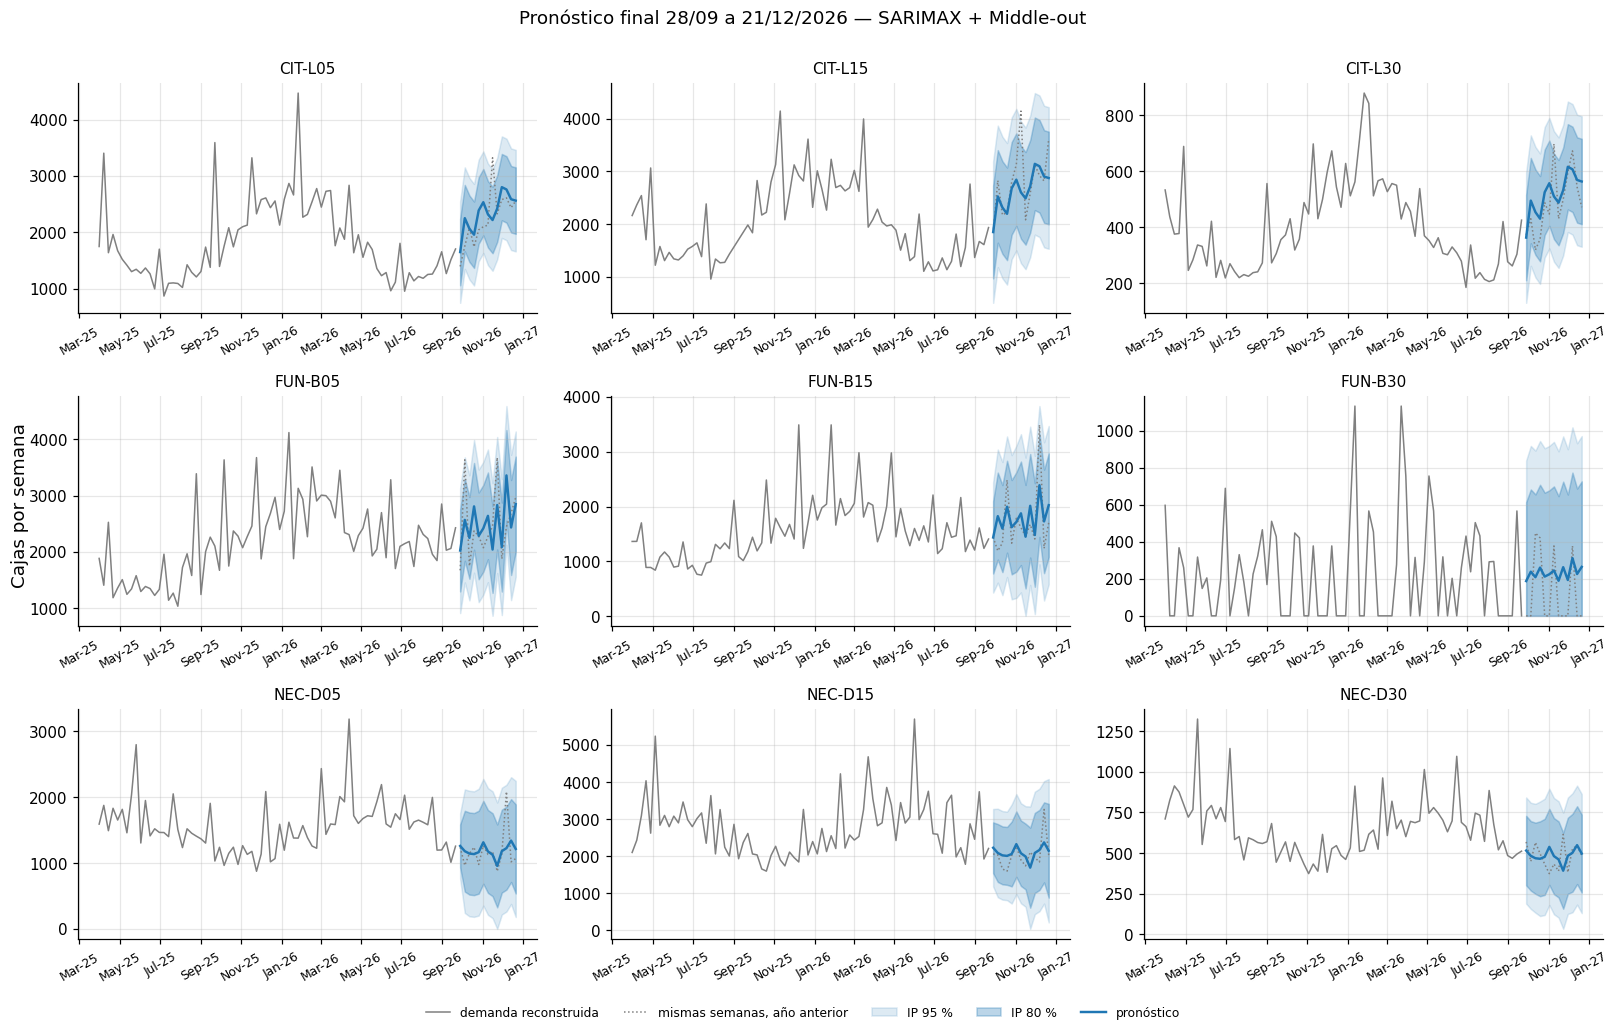

In [ ]:
fig, ejes = plt.subplots(3, 3, figsize=(15, 9))
for ax, sku in zip(ejes.flatten(), skus):
    d = pronostico_final[pronostico_final["serie"] == sku]
    fx = pd.to_datetime(d["fecha_lunes"])
    hist_sku = niveles[sku].loc[ULTIMA - 77:]
    ax.plot(fechas.loc[hist_sku.index], hist_sku.values, color="gray", lw=1, label="demanda reconstruida")
    ax.plot(fechas.loc[ULTIMA - 51:ULTIMA - 39] + pd.Timedelta(weeks=52), niveles.loc[ULTIMA - 51:ULTIMA - 39, sku].values,
            color="gray", ls=":", lw=1, label="mismas semanas, año anterior")
    ax.fill_between(fx, d["inf_95"], d["sup_95"], color="tab:blue", alpha=0.15, label="IP 95 %")
    ax.fill_between(fx, d["inf_80"], d["sup_80"], color="tab:blue", alpha=0.30, label="IP 80 %")
    ax.plot(fx, d["pronostico"], color="tab:blue", lw=1.6, label="pronóstico")
    ax.set_title(sku, fontsize=10)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
    ax.tick_params(axis="x", rotation=30, labelsize=8)
h_, l_ = ejes[0, 0].get_legend_handles_labels()
fig.legend(h_, l_, loc="lower center", ncol=5, fontsize=8, frameon=False, bbox_to_anchor=(0.5, -0.03))
fig.supylabel("Cajas por semana")
plt.suptitle(f"Pronóstico final 28/09 a 21/12/2026 — {MODELO_BASE} + {METODO_ELEGIDO}", y=1.0)
plt.tight_layout()
plt.show()

## 5. Parte C — Tabla de traspaso a la Entrega 2

La Entrega 2 usará estos cuatro parámetros **literalmente**. Cada uno sale de una celda anterior y se
guarda en `resultados/` para que el modelo de lot-sizing los lea sin transcribir nada a mano.

**C1. Tasa de merma efectiva $\rho_\ell$ por línea** (carta p). Se usa la proporción defectuosa de
**todas** las inspecciones de las 10 semanas, *incluido* el episodio de la semana 8 en L2. En 10 semanas
hubo un episodio: si el plan usara solo la tasa «estable», produciría de menos cada vez que se repitiera.
La tasa estable (p̄ de Fase I) se entrega como escenario de sensibilidad. El plan debe producir
$x/(1-\rho_\ell)$ para obtener $x$ cajas vendibles.

In [ ]:
filas = []
for linea_nom, d in cartas_p.items():
    rho = d["n_defectuosas"].sum() / d["n_inspeccionadas"].sum()
    rho_est = d["p_bar"].iloc[0]
    filas.append([linea_nom, rho, rho_est, 1 / (1 - rho), 100 / (1 - rho)])
c1 = pd.DataFrame(filas, columns=["linea", "rho_efectiva", "rho_estable_FaseI", "factor_produccion_1/(1-rho)",
                                  "producir_por_100_vendibles"])
display(c1.round(4))

,linea,rho_efectiva,rho_estable_FaseI,factor_produccion_1/(1-rho),producir_por_100_vendibles
0,L1,0.0192,0.0186,1.0196,101.9594
1,L2,0.0311,0.0261,1.0321,103.2147


**Lectura de resultados.** $\rho_{L1}$ = **1,92 %** y $\rho_{L2}$ = **3,11 %**. Para entregar 100 cajas
vendibles hay que producir **102,0 cajas en L1 y 103,2 en L2**. En L2 la diferencia entre la tasa efectiva y
la estable (2,61 %) es el episodio de etiquetas de la semana 8. Si BdM controla esos insumos, la Entrega 2
puede probar el escenario de 2,61 %.

**C2. Sobrellenado medio por formato y litros de jarabe adicionales por caja.** Se usa el escenario
**vigente** (Fase II, semanas 6 a 10), porque el corrimiento de L1 sigue activo y el plan de las próximas
13 semanas lo heredará mientras no se corrija. El promedio de 10 semanas queda como referencia.
Litros extra por caja = mL extra por botella × botellas por caja / 1000.

In [ ]:
nominales = esp["nominal_mL"]
bxc = maestro.drop_duplicates("formato_L").set_index("formato_L")["botellas_por_caja"]
c2 = pd.DataFrame({
    "sobrellenado_vigente_mL": d_vig.groupby("formato_L")["volumen_mL"].mean() - nominales,
    "sobrellenado_10sem_mL": llen.groupby("formato_L")["volumen_mL"].mean() - nominales,
    "botellas_por_caja": bxc})
c2["L_jarabe_extra_por_caja"] = c2["sobrellenado_vigente_mL"] * c2["botellas_por_caja"] / 1000
c2["L_jarabe_extra_por_caja_10sem"] = c2["sobrellenado_10sem_mL"] * c2["botellas_por_caja"] / 1000
c2.index.name = "formato_L"
display(c2.round(4))

,sobrellenado_vigente_mL,sobrellenado_10sem_mL,botellas_por_caja,L_jarabe_extra_por_caja,L_jarabe_extra_por_caja_10sem
formato_L,,,,,
0.5,5.7198,4.0936,12,0.0686,0.0491
1.5,4.6455,4.6011,6,0.0279,0.0276
3.0,8.0724,8.5012,4,0.0323,0.0340


**Lectura de resultados.** Sobrellenado vigente: **0,5 L: +5,72 mL por botella → 0,069 L de jarabe extra por
caja; 1,5 L: +4,65 mL → 0,028 L/caja; 3,0 L: +8,07 mL → 0,032 L/caja**. En la Entrega 2 esto se suma al
consumo de jarabe por caja en la restricción de capacidad de la mezcladora, el cuello de botella. Si se
recentra L1 (sección 3.5), el valor de 0,5 L baja a cerca de 0,004 L/caja y libera capacidad de mezcla.

**C3. Pronóstico puntual $\hat d_{it}$** ($t = 1$ es la semana del 28/09/2026). **C4. Desviación estándar
del error $\hat\sigma_{i,h}$** por SKU y horizonte (cajas). Fija el stock de seguridad de la Entrega 2:
$SS_{it} = z_{\alpha}\,\hat\sigma_{i,h}$.

In [ ]:
c3 = pron_rec[skus].copy()
c3.index.name = "t"
print("C3. Pronóstico puntual (cajas por semana)")
display(c3.round(0))

c4 = sigma_cv[skus].copy()
c4.index.name = "h"
print("C4. Desviación estándar del error de pronóstico (cajas)")
display(c4.round(0))
print("σ̂ como % del pronóstico medio (para dimensionar):")
display((100 * c4.mean() / c3.mean()).round(1).to_frame("sigma_medio_%").T)

R = CONFIG["carpeta_resultados"]
c1.to_csv(os.path.join(R, "traspaso_C1_merma.csv"), index=False)
c2.to_csv(os.path.join(R, "traspaso_C2_sobrellenado.csv"))
c3.to_csv(os.path.join(R, "traspaso_C3_pronostico.csv"))
c4.to_csv(os.path.join(R, "traspaso_C4_sigma.csv"))
print("Archivos de traspaso guardados en", R, ":", sorted(f for f in os.listdir(R) if f.startswith("traspaso")))

C3. Pronóstico puntual (cajas por semana)


,CIT-L05,CIT-L15,CIT-L30,FUN-B05,FUN-B15,FUN-B30,NEC-D05,NEC-D15,NEC-D30
t,,,,,,,,,
1,1647.0,1851.0,362.0,2023.0,1438.0,188.0,1260.0,2227.0,515.0
2,2249.0,2527.0,495.0,2567.0,1826.0,239.0,1180.0,2086.0,482.0
3,2062.0,2316.0,454.0,2248.0,1599.0,209.0,1144.0,2022.0,467.0
4,1955.0,2197.0,430.0,2808.0,1996.0,261.0,1136.0,2008.0,464.0
5,2386.0,2681.0,525.0,2284.0,1624.0,212.0,1165.0,2059.0,476.0
6,2532.0,2845.0,557.0,2417.0,1719.0,225.0,1315.0,2324.0,537.0
7,2317.0,2604.0,510.0,2639.0,1877.0,245.0,1177.0,2079.0,480.0
8,2216.0,2490.0,488.0,2041.0,1451.0,190.0,1127.0,1991.0,460.0
9,2419.0,2717.0,532.0,2831.0,2013.0,263.0,957.0,1691.0,391.0


C4. Desviación estándar del error de pronóstico (cajas)


serie,CIT-L05,CIT-L15,CIT-L30,FUN-B05,FUN-B15,FUN-B30,NEC-D05,NEC-D15,NEC-D30
h,,,,,,,,,
1,460.0,685.0,119.0,567.0,512.0,333.0,254.0,533.0,166.0
2,460.0,685.0,119.0,567.0,618.0,347.0,479.0,608.0,166.0
3,460.0,685.0,119.0,567.0,618.0,349.0,487.0,608.0,171.0
4,460.0,685.0,119.0,602.0,652.0,349.0,487.0,608.0,180.0
5,460.0,685.0,119.0,602.0,670.0,354.0,492.0,680.0,182.0
6,460.0,685.0,119.0,602.0,705.0,354.0,492.0,687.0,182.0
7,460.0,685.0,119.0,602.0,735.0,355.0,492.0,687.0,182.0
8,460.0,685.0,119.0,602.0,735.0,357.0,492.0,691.0,182.0
9,460.0,685.0,119.0,617.0,735.0,361.0,492.0,841.0,182.0


σ̂ como % del pronóstico medio (para dimensionar):


serie,CIT-L05,CIT-L15,CIT-L30,FUN-B05,FUN-B15,FUN-B30,NEC-D05,NEC-D15,NEC-D30
sigma_medio_%,19.6,26.0,23.1,24.2,38.5,152.0,40.0,34.7,37.1


Archivos de traspaso guardados en resultados : ['traspaso_C1_merma.csv', 'traspaso_C2_sobrellenado.csv', 'traspaso_C3_pronostico.csv', 'traspaso_C4_sigma.csv']


**Tabla de traspaso (resumen).**

| Parámetro | Valor | Origen | Uso en la Entrega 2 |
|---|---|---|---|
| $\rho_{L1}$, $\rho_{L2}$ | 1,92 % y 3,11 % | Carta p, 10 semanas | Producir $x/(1-\rho_\ell)$ |
| Sobrellenado por formato | 0,069 / 0,028 / 0,032 L de jarabe por caja (0,5 / 1,5 / 3,0 L) | Fase II vigente | Capacidad de mezcla |
| $\hat d_{it}$ | Tabla C3, 9 SKU × 13 semanas | SARIMAX + middle-out | Demanda del lot-sizing |
| $\hat\sigma_{i,h}$ | Tabla C4, 9 SKU × 13 horizontes | Errores del origen deslizante | Stock de seguridad $z_\alpha\hat\sigma_{i,h}$ |

Los cuatro archivos `traspaso_C*.csv` quedan en `resultados/`.



## 6. Verificaciones programadas (fuga, partición, reproducibilidad) y cifras clave

La rúbrica de laboratorio pide, en su nivel más alto, *verificaciones programadas que detecten fuga
temporal o inconsistencias de partición*. Cada línea de la celda siguiente es una comprobación. Si
alguna falla, la ejecución se detiene con un mensaje explicativo.

In [ ]:
chequeos = []
def chequear(descripcion, condicion):
    assert condicion, "FALLÓ: " + descripcion
    chequeos.append({"chequeo": descripcion, "resultado": "OK"})

# datos crudos intactos
chequear("calidad_llenado.csv no fue modificado", leer("calidad_llenado.csv").equals(llen_raw))
chequear("calidad_atributos.csv no fue modificado", leer("calidad_atributos.csv").equals(atr_raw))
chequear("demanda_semanal.csv no fue modificado", leer("demanda_semanal.csv").equals(dem_raw))
# Parte A
for (l, f), lim in lims.items():
    chequear(f"Límites X̄–R {l} {f} L calculados solo con Fase I",
             sg[sg["subgrupo"].isin(lim["subgrupos_estables"])]["semana"].max() <= FASE1)
chequear("Capacidad calculada solo con subgrupos estables de Fase I",
         all(set(llen[llen["subgrupo"].isin(lims[k]["subgrupos_estables"])]["semana_registro"]) <= set(range(1, FASE1 + 1)) for k in lims))
chequear("p̄ de la carta p calculado con Fase I (no cambia al agregar Fase II)",
         all(abs(d["p_bar"].iloc[0] - d[d["fase"] == "I"]["n_defectuosas"].sum() / d[d["fase"] == "I"]["n_inspeccionadas"].sum()) < 0.01
             for d in cartas_p.values()))
# Parte B
chequear("Atípicos detectados con nivel local solo del pasado (shift(1))", nivel_local.loc[8:].notna().all().all())
chequear("Entrenamiento y prueba sin traslape", train.index.max() < test.index.min())
chequear("Ningún pliegue del origen deslizante toca la prueba", cv["origen"].max() + H <= FIN_TRAIN)
chequear("Al menos 8 ventanas y h = 13", cv["origen"].nunique() >= 8 and cv["h"].max() == 13)
chequear("Órdenes de validación elegidos con datos hasta el primer origen (incluido en todos los pliegues)",
         SEMANA_SELECCION <= min(ORIGENES) and set(ordenes_cv) == set(SERIES))
chequear("Evaluación de la jerarquía solo dentro del entrenamiento", errores["origen"].max() + H <= FIN_TRAIN)
chequear("Modelo elegido = mínimo WAPE calculado solo con pliegues del entrenamiento",
         MODELO_BASE == cv[cv["modelo"].isin(ELEGIBLES)].groupby("modelo").apply(lambda g: g["e"].abs().sum() / g["y"].sum()).idxmin())
chequear("Método jerárquico elegido = mínimo WAPE SKU solo con pliegues del entrenamiento",
         METODO_ELEGIDO == errores[(errores["nivel"] == "SKU") & (errores["metodo"] != METODOS[0])].groupby("metodo").apply(
             lambda g: g["e"].abs().sum() / g["y"].sum()).idxmin())
chequear("Pronóstico final coherente (familias y Planta = suma de SKU)", dif < 1e-6)
chequear("Pronóstico final no negativo", (pron_rec >= 0).all().all())
chequear("σ̂ no decrece con el horizonte", (sigma_cv.diff().dropna() >= -1e-9).all().all())
chequear("Sin ajustes fallidos de modelos", len(fallos) == 0)

display(pd.DataFrame(chequeos))
print(f"{len(chequeos)} comprobaciones superadas.")

,chequeo,resultado
0,calidad_llenado.csv no fue modificado,OK
1,calidad_atributos.csv no fue modificado,OK
2,demanda_semanal.csv no fue modificado,OK
3,Límites X̄–R L1 0.5 L calculados solo con Fase I,OK
4,Límites X̄–R L2 1.5 L calculados solo con Fase I,OK
5,Límites X̄–R L2 3.0 L calculados solo con Fase I,OK
6,Capacidad calculada solo con subgrupos estable...,OK
7,p̄ de la carta p calculado con Fase I (no camb...,OK
8,Atípicos detectados con nivel local solo del p...,OK
9,Entrenamiento y prueba sin traslape,OK


20 comprobaciones superadas.


In [ ]:
# Cifras clave del informe: todas salen de variables calculadas arriba (trazabilidad)
l1 = tabla_cap[(tabla_cap["linea"] == "L1") & (tabla_cap["grupo"] == "Global")].iloc[0]
cifras_clave = {
    "L1 0,5 L: corrimiento de la media Fase I -> Fase II (mL)": tabla_f2.iloc[0]["media"] - l1["media"],
    "L1 0,5 L: % subgrupos de Fase II con señal": tabla_we[(tabla_we["carta"] == "L1 0.5 L") & (tabla_we["fase"] == "II")]["% con señal"].iloc[0],
    "L1 0,5 L: Cp / Cpk Fase I": f"{l1['Cp']:.2f} / {l1['Cpk']:.2f}",
    "L1 0,5 L: Ppk Fase II": tabla_f2.iloc[0]["Ppk"],
    "L2 1,5 L: Cp / Cpk Fase I": "{:.2f} / {:.2f}".format(*tabla_cap[(tabla_cap["linea"] == "L2") & (tabla_cap["formato"] == 1.5) & (tabla_cap["grupo"] == "Global")][["Cp", "Cpk"]].iloc[0]),
    "L2 3,0 L: Cp / Cpk Fase I": "{:.2f} / {:.2f}".format(*tabla_cap[(tabla_cap["linea"] == "L2") & (tabla_cap["formato"] == 3.0) & (tabla_cap["grupo"] == "Global")][["Cp", "Cpk"]].iloc[0]),
    "Turno C L2: Cpk 1,5 L / 3,0 L": "{:.2f} / {:.2f}".format(*tabla_cap[(tabla_cap["grupo"].str.startswith("C"))]["Cpk"].values),
    "Cumple OIML R87 en todas las combinaciones": bool(tabla_legal["cumple_R87"].all()),
    "Merma rho L1 / L2 (%)": "{:.2f} / {:.2f}".format(*(100 * c1["rho_efectiva"].values)),
    "Sobrellenado vigente: litros/año": tot_planta.loc["Vigente (Fase II)", "litros_anio"],
    "Sobrellenado vigente: MM CLP/año (costo variable)": tot_planta.loc["Vigente (Fase II)", "valor_MM_CLP"],
    "Recuperable recentrando L1 (MM CLP/año)": recuperable.iloc[0]["MM_CLP_ajustando_media"],
    "FUN-B30: demanda perdida por quiebres (% de la venta)": tabla_censura.loc["FUN-B30", "incremento_%"],
    "Modelo elegido / WAPE origen deslizante (%)": f"{MODELO_BASE} / {global_cv.loc[MODELO_BASE, 'WAPE_%']:.1f}",
    "WAPE benchmark ingenuo estacional (%)": global_cv.loc["Ingenuo estacional", "WAPE_%"],
    "Método jerárquico elegido / WAPE SKU (%)": f"{METODO_ELEGIDO} / {tab_jer[(tab_jer['nivel'] == 'SKU') & (tab_jer['metodo'] == METODO_ELEGIDO)]['WAPE_%'].iloc[0]:.1f}",
    "Prueba 144-156: WAPE SKU elegido vs benchmark (%)": "{:.1f} vs {:.1f}".format(
        prueba[(prueba["metodo"] == METODO_ELEGIDO) & (prueba["nivel"] == "SKU")]["WAPE_%"].iloc[0],
        prueba[(prueba["metodo"].str.startswith("Benchmark")) & (prueba["nivel"] == "SKU")]["WAPE_%"].iloc[0]),
    "Cobertura IP 80 % / 95 % en prueba (%)": "{:.0f} / {:.0f}".format(*cobertura.loc["cobertura empírica %"].values),
    "Pronóstico Planta 13 semanas (cajas)": pron_rec["Planta"].sum(),
}
cifras_df = pd.DataFrame({"valor": {k: (f"{v:,.2f}" if isinstance(v, (float, np.floating)) else str(v)) for k, v in cifras_clave.items()}})
display(cifras_df)
cifras_df.to_csv(os.path.join(CONFIG["carpeta_resultados"], "cifras_clave.csv"))

,valor
"L1 0,5 L: corrimiento de la media Fase I -> Fase II (mL)",3.25
"L1 0,5 L: % subgrupos de Fase II con señal",100.00
"L1 0,5 L: Cp / Cpk Fase I",1.28 / 0.88
"L1 0,5 L: Ppk Fase II",0.38
"L2 1,5 L: Cp / Cpk Fase I",1.01 / 0.72
"L2 3,0 L: Cp / Cpk Fase I",1.01 / 0.66
"Turno C L2: Cpk 1,5 L / 3,0 L",0.49 / 0.49
Cumple OIML R87 en todas las combinaciones,True
Merma rho L1 / L2 (%),1.92 / 3.11
Sobrellenado vigente: litros/año,"32,792.93"


## 7. Conclusiones para la gerencia

**Queja 1: Calidad dice que el proceso está bajo control, pero Finanzas ve merma Las dos cosas son
ciertas a la vez. *Bajo control* significa *predecible*, no *dentro de especificación*. L2 es predecible
pero incapaz (Cp ≈ 1,0), y L1 era casi capaz pero estaba descentrado, y desde el 24/08 además corrido
+3,25 mL. Ninguna línea incumple la ley (OIML R87 se cumple con holgura). La merma que ve Finanzas tiene
dos componentes con números propios:
- **Sobrellenado:** ≈ 32.800 L de jarabe al año, equivalente a 21,1 MM CLP a costo variable. aproximadamente 13,0 MM CLP se
  recuperan solo con recentrar la llenadora de L1, una acción barata e inmediata. Los ≈ 7,6 MM CLP de L2
  exigen reducir la variabilidad ≈ 24 %, empezando por el turno C, que regala ≈ 3,7 MM CLP al año.
- **Defectuosas:** 1,92 % en L1 y 3,11 % en L2. El problema crónico se reparte entre sello, etiqueta y
  nivel de llenado, más un episodio de etiquetas en la semana 8 que se corrige controlando insumos.

**Queja 2: «Comercial pronostica y Planificación no le cree».** Se entrega **un solo pronóstico** por SKU:
SARIMAX con promoción + reconciliación middle-out. Es coherente en Planta → Familia → SKU y está validado sin
fuga (WAPE 19,1 % a nivel SKU en validación y 22,8 % en la prueba, contra 27,9 % del ingenuo). La mayor
parte del error que queda viene de no conocer el calendario de promociones, compartirlo bajaría el WAPE
≈ 3 puntos y el stock de seguridad entre 15 y 55 %. Ésa es la razón económica para que Comercial y
Planificación trabajen con un mismo número.

### Decisiones metodológicas (para la defensa)

| Decisión | Alternativa descartada | Por qué |
|---|---|---|
| Carta X̄–R | X̄–S | n = 5 constante; el rango es eficiente para n ≤ 10 |
| Fase I iterativa y límites congelados | Recalcular con las 10 semanas | Recalcular esconde el cambio que se busca (fuga) |
| ANOVA turno + SKU | ANOVA de un factor | Separa el efecto turno del efecto SKU (están confundidos en L2) |
| Carta p con p̄ de Fase I | Carta np, o p̄ con las 10 semanas | n variable; el episodio de la semana 8 inflaría los límites |
| Sobrellenado vigente (Fase II) para la Entrega 2 | Promedio de 10 semanas | El corrimiento de L1 sigue activo |
| Atípicos con nivel local del pasado | Mediana centrada | La mediana centrada mira semanas futuras |
| Demanda = venta × 7/(7−d) | Usar ventas como demanda | Las ventas están censuradas (FUN-B30 +49 %) |
| Solo promoción como regresor | Promoción + precio | Correlación 0,98: misma información |
| Promoción futura = frecuencia esperada | Calendario real | No existe calendario futuro en los datos |
| Órdenes SARIMA con semanas 1 a 109 | Elegir con todo el entrenamiento | Así ningún pliegue usa datos posteriores a su origen |
| Middle-out | Bottom-up, top-down | Menor WAPE a nivel SKU; las familias no comparten fase |
| σ̂ con banda h ± 1 y no decreciente | RMSE de 8 errores por h | Estabiliza una estimación con pocos datos |

### Limitaciones declaradas
- El sobrellenado anual usa ventas (no producción) como volumen. Con la merma ρ la cifra real es aproximadamente de 2 a 3 %
  mayor.
- La reconstrucción de la demanda supone una venta homogénea en la semana. FUN-B30 concentra el efecto y su
  pronóstico es el más incierto.
- Los intervalos sobrecubren en la prueba (temporada baja). Son conservadores para el stock de seguridad.
- SARIMAX subestima en semanas de promoción reales (sesgo −4,6 %). ETS, con menos sesgo y casi el mismo
  WAPE, es la alternativa natural si la Entrega 2 penaliza más el quiebre que el inventario.

